# Project Introduction

The City of Seattle aims to become carbon‑neutral by **2050**. A key lever in this transition is the energy performance of **non‑residential buildings**, which together account for a substantial share of municipal electricity use and **CO₂ emissions**.

In **2016** the city conducted an extensive field survey that measured **total energy consumption** and associated **CO₂ emissions** for a representative sample of commercial, institutional, and industrial structures. Because these measurements are costly and time‑consuming, we will develop a **predictive model** that estimates:

- **Energy use (kWh)**
- **CO₂ emissions (kg)**  

for the many buildings that have not yet been measured.

Our approach relies solely on **structural attributes** that are readily available for every building—size, age, primary use, geographic location, HVAC system, insulation level, etc.  

## Workflow

1. **Exploratory Data Analysis**  
   - Uncover patterns and key drivers.  

2. **Supervised Learning**  
   - Train and evaluate several regression models.  

3. **Feature‑Importance Analysis**  
   - Identify the most influential factors for the best‑performing model.  

## Deliverable

A **reproducible Jupyter notebook** that can be applied city‑wide, enabling the Seattle Planning Department to:

- Prioritize retrofits  
- Set realistic energy‑reduction targets  
- Monitor progress toward the 2050 carbon‑neutral goal

# Functions

In [ ]:
# @title Variable analysis to identify the nature of features
import pandas as pd
import numpy as np
import re
import warnings # Import the warnings module

# Ignore all warnings
warnings.filterwarnings('ignore')


def analyze_variables(DF: pd.DataFrame) -> pd.DataFrame:
    """
    Performs an exhaustive analysis of variables in a DataFrame, suggesting potential type conversions
    and providing summary statistics.

    Args:
        DF: The input pandas DataFrame to analyze.

    Returns:
        A pandas DataFrame containing the variable analysis summary.
    """

    # ---------- Helper functions ----------

    def clean_numeric_strings(s: pd.Series) -> pd.Series:
        """Remove formatting characters (currency, commas, spaces) for numeric parsing."""
        if s.dtype == 'O':
            s2 = s.astype(str).str.strip()
            s2 = (s2
                  .str.replace(r'[\s,₹$€£]', '', regex=True)
                  .str.replace(r'^\((.*)\)$', r'-\1', regex=True))  # (123) -> -123
            return s2
        return s

    def try_numeric(series: pd.Series, min_ratio: float = 0.9):
        """Try to convert to numeric; return (is_numeric_like, parsed_series, ratio, note)."""
        s = series.dropna()
        if s.empty:
            return False, None, 0.0, "no non-null values"
        if series.dtype == 'O':
            s_clean = clean_numeric_strings(series)
            numeric = pd.to_numeric(s_clean, errors='coerce')
            ratio = numeric.notna().mean()
            return ratio >= min_ratio, numeric, ratio, "text numeric-like" if ratio >= min_ratio else "non-numeric text"
        else:
            return True, series, 1.0, "already numeric"

    def try_datetime(series: pd.Series, min_ratio: float = 0.9):
        s = series.dropna()
        if s.empty:
            return False, None, 0.0
        parsed = pd.to_datetime(series, errors='coerce', infer_datetime_format=True)
        ratio = parsed.notna().mean()
        return ratio >= min_ratio, parsed, ratio

    def is_boolean_like(series: pd.Series):
        """Detect yes/no, true/false, 0/1."""
        s = series.dropna().astype(str).str.strip().str.lower()
        vals = s.unique()
        bool_sets = [{'true', 'false'}, {'t', 'f'}, {'yes', 'no'}, {'y', 'n'}, {'0', '1'}]
        for bset in bool_sets:
            if set(vals).issubset(bset):
                return True
        if pd.api.types.is_numeric_dtype(series) and series.nunique(dropna=True) <= 2:
            return True
        return False

    def variable_nature(dtype, proposed=None):
        """Categorize variable nature."""
        if proposed:
            p = proposed.lower()
            if 'datetime' in p:
                return 'Temporal'
            if 'bool' in p:
                return 'Boolean'
            if 'category' in p:
                return 'Categorical'
            if 'int' in p or 'float' in p or 'numeric' in p:
                return 'Quantitative'
        if pd.api.types.is_numeric_dtype(dtype):
            return 'Quantitative'
        if 'datetime' in str(dtype):
            return 'Temporal'
        if str(dtype) == 'object':
            return 'Qualitative / Categorical'
        return 'Other'

    # ---------- Build audit summary ----------

    summary = pd.DataFrame({
        'Variable': DF.columns,
        'Type': [DF[col].dtype for col in DF.columns],
    })

    unique_counts = {}
    values_if_lt10 = {}
    fill_rates = {}
    proposed_types = {}
    type_proposals = {}

    for col in DF.columns:
        s = DF[col]
        unique_counts[col] = s.nunique(dropna=True)
        values_if_lt10[col] = ', '.join(map(str, s.dropna().unique())) if unique_counts[col] < 10 else ''
        fill_rates[col] = round(s.notna().mean() * 100, 2)

        dtype = s.dtype
        proposal_notes = []
        proposed = None

        # Boolean-like
        if is_boolean_like(s):
            proposed = 'bool'
            proposal_notes.append("boolean-like values (yes/no or 0/1)")

        # Numeric-like
        if proposed is None:
            is_num, num_parsed, ratio_num, note_num = try_numeric(s)
            if is_num:
                proposed = 'float' if (num_parsed % 1 != 0).any() else 'int'
                proposal_notes.append(f"numeric-like ({ratio_num:.0%} parseable)")

        # Datetime-like
        if proposed is None:
            is_dt, dt_parsed, ratio_dt = try_datetime(s)
            if is_dt:
                proposed = 'datetime64[ns]'
                proposal_notes.append(f"datetime-like ({ratio_dt:.0%} parseable)")

        # Numeric but categorical (≤10 unique)
        if proposed is None and pd.api.types.is_numeric_dtype(dtype):
            if unique_counts[col] <= 10:
                proposed = 'category'
                proposal_notes.append("numeric with ≤10 unique values (categorical codes)")

        # Object but categorical
        if proposed is None and dtype == 'O':
            nunique = unique_counts[col]
            non_null = s.notna().sum()
            if non_null > 0 and (nunique <= 50 or nunique / max(non_null,1) <= 0.05):
                proposed = 'category'
                proposal_notes.append("object with low unique ratio (likely category)")

        # Default fallback
        if proposed is None:
            proposed = str(dtype)
            proposal_notes.append("keep current dtype")

        proposed_types[col] = proposed
        type_proposals[col] = f"→ {proposed}. " + "; ".join(proposal_notes)

    summary['Proposed_Type'] = [proposed_types[c] for c in DF.columns]
    summary['Type_Proposal'] = [type_proposals[c] for c in DF.columns]
    summary['Type_Decision'] = ''  # <-- new empty column
    summary['Variable_Nature'] = [
        variable_nature(summary.loc[i, 'Type'], summary.loc[i, 'Proposed_Type'])
        for i in range(len(summary))
    ]
    summary['Unique_Values'] = [DF[c].nunique(dropna=True) for c in DF.columns]
    summary['Values_if_<10'] = [', '.join(map(str, DF[c].dropna().unique())) if DF[c].nunique(dropna=True) < 10 else '' for c in DF.columns]
    summary['Fill_Rate (%)'] = [round(DF[c].notna().mean() * 100, 2) for c in DF.columns]
    summary['Decision'] = ''
    summary['Reason'] = ''

    # ---- Reorder columns ----
    summary = summary[[
        'Variable', 'Type', 'Proposed_Type', 'Type_Proposal', 'Type_Decision',
        'Variable_Nature', 'Unique_Values', 'Values_if_<10',
        'Fill_Rate (%)', 'Decision', 'Reason'
    ]]

    return summary

    # Reset warnings to default
# warnings.filterwarnings('default') # Commented out to keep warnings ignored

In [ ]:
# @title Function to display correlation heatmap and identify highly correlated features

import matplotlib.pyplot as plt
import seaborn as sns

def analyze_correlation(df):
    """
    Calculates and displays the correlation heatmap for numerical columns
    and identifies pairs of highly correlated features.

    Args:
        df: The input pandas DataFrame.
    """
    # Calculate the correlation matrix for numerical columns
    correlation_matrix = df.corr(numeric_only=True)

    # Create a heatmap of the correlation matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
    plt.title('Correlation Heatmap of Variables')
    plt.show()


    # Identify highly correlated features
    correlation_threshold = 0.7  # You can adjust this threshold

    # Get the absolute values of the correlation matrix
    abs_correlation_matrix = correlation_matrix.abs()

    # Stack the matrix and reset the index to get a DataFrame of pairs
    stacked_corr = abs_correlation_matrix.stack().reset_index()
    stacked_corr.columns = ['Feature 1', 'Feature 2', 'Absolute Correlation']

    # Filter out self-correlations and duplicate pairs
    filtered_corr = stacked_corr[stacked_corr['Feature 1'] != stacked_corr['Feature 2']]
    filtered_corr = filtered_corr[filtered_corr['Absolute Correlation'] >= correlation_threshold]

    # Remove duplicate pairs (e.g., A-B and B-A)
    filtered_corr['sorted_pair'] = filtered_corr.apply(lambda row: tuple(sorted((row['Feature 1'], row['Feature 2']))), axis=1)
    unique_high_corr = filtered_corr.drop_duplicates(subset='sorted_pair').drop('sorted_pair', axis=1)

    # Sort by absolute correlation in descending order
    unique_high_corr = unique_high_corr.sort_values(by='Absolute Correlation', ascending=False)

    print(f"Pairs of features with absolute correlation >= {correlation_threshold}:")
    display(unique_high_corr)



# Import modules and visualise the data

In [ ]:
# @title Load the building energy consumption data

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

pd.set_option('display.max_columns', None)


# Check if Google Drive is already mounted
if not os.path.exists('/content/drive'):
else:
    print("Google Drive is already mounted.")


# Replace 'MyDataFolder' with the actual path to your data folder in Google Drive
drive_data_path = '/content/drive/MyDrive/PROJET 3/data'

# Check if the directory exists before changing the directory
if os.path.exists(drive_data_path):
    os.chdir(drive_data_path)
    print(f"Changed working directory to: {os.getcwd()}")
else:
    print(f"Error: The directory '{drive_data_path}' was not found.")
    print("Please check the path and make sure your Google Drive is mounted.")



try:
    building_consumption = pd.read_csv('/content/drive/MyDrive/PROJET 3/data/2016_Building_Energy_Benchmarking.csv', low_memory=False)
    display(building_consumption.head())
    print("Data loaded successfully.")
except FileNotFoundError:
    print("Error: The CSV file was not found. Please check the file path.")
except Exception as e:
    print(f"An error occurred while loading the data: {e}")

# Check if the DataFrame was created
if 'building_consumption' in locals() and isinstance(building_consumption, pd.DataFrame):
    print("building_consumption DataFrame successfully created.")
else:
    print("building_consumption DataFrame was NOT successfully created.")

Mounted at /content/drive
Changed working directory to: /content/drive/MyDrive/PROJET 3/data


,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


Data loaded successfully.
building_consumption DataFrame successfully created.


#  Data Cleansing

 - Choose the features to be retained woth reasoning based on professional judgement


- Choice of features (Professional Judgement)
 remove variables that are not needed with the reason.

[Choice of features](https://docs.google.com/spreadsheets/d/1UI-0VgL4qJ3IXSbu6btSqXYmXGVwyoBK/edit?usp=drive_link&ouid=116112012719919483650&rtpof=true&sd=true)



 - Filtering of Observations on vakues which are residential


 - Target choice for Machine Learning : SiteEnergyUseWN(kBtu),TotalGHGEmissions
 SiteEnergyUseWN(kBtu) has been selected as it has been adjusted to the weather unlike SiteEnergyUse(kBtu)

 - Management of missing values in SiteEnergyUseWN(kBtu) with the values in SiteEnergyUse(kBtu)

 - Analyse variables after cleansing and assign them the appropriate variable types

 - Remove observations tagged as outliers and drop the variable

-  For missing values that are empty, for quantitative variables fill with  0 and qualitative fill with NaN.

- PrimaryPropertyType and LargestPropertyUseType contain the same values in most cases. We drop the PrimaryPropertyType and in somecases, replace the LargestPropertyUseType value with PrimaryPropertyType if it is clearer.

[Conversion mapping](https://docs.google.com/spreadsheets/d/1pI6uxj5-9aRIZSpTCov0Gx8jqPnms686/edit?usp=drive_link&ouid=116112012719919483650&rtpof=true&sd=true)


In [ ]:
# @title Analyse the features of the dataset
# Ignore user warnings
warnings.filterwarnings('ignore', category=UserWarning)

# Call the analyze_variables function and save the output
summary_df = analyze_variables(building_consumption)

# Save the summary DataFrame to an Excel file in the active directory
excel_filename = 'variable_analysis_summary.xlsx'
summary_df.to_excel(excel_filename, index=False)

print(f"Variable analysis summary saved to '{excel_filename}'")


Variable analysis summary saved to 'variable_analysis_summary.xlsx'


In [ ]:
# @title Drop columns which are not needed (professional judgement)

columns_to_drop = [
    'DataYear',
    'PropertyName',
    'Address',
    'City',
    'State',
    'TaxParcelIdentificationNumber',
    'CouncilDistrictCode',
    'Latitude',
    'Longitude',
    'PropertyGFATotal',
    'ListOfAllPropertyUseTypes',
    'YearsENERGYSTARCertified',
    'SiteEUI(kBtu/sf)',
    'SiteEUIWN(kBtu/sf)',
    'SourceEUI(kBtu/sf)',
    'SourceEUIWN(kBtu/sf)',
    'SteamUse(kBtu)',
    'Electricity(kWh)',
    'Electricity(kBtu)',
    'NaturalGas(therms)',
    'NaturalGas(kBtu)',
    'Comments',
    'GHGEmissionsIntensity',
    'OSEBuildingID', # Added OSEBuildingID to the list
    'Neighborhood', # Added Neighborhood to the list
    'DefaultData', # Added DefaultData to the list
    'ComplianceStatus' # Added ComplianceStatus to the list

]

# Drop the specified columns from the building_consumption DataFrame
building_consumption = building_consumption.drop(columns=columns_to_drop, errors='ignore')


print(building_consumption.columns.tolist())
print (building_consumption.shape)

['BuildingType', 'PrimaryPropertyType', 'ZipCode', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'Outlier', 'TotalGHGEmissions']
(3376, 19)


In [ ]:
#@title  Define the list of building types to remove that are residential
# Updated to remove any BuildingType containing "Multifamily"
building_types_to_remove_pattern = 'Multifamily'


# Get the number of rows before filtering
rows_before_filtering = len(building_consumption)
print(f"Number of rows before removing specified building types: {rows_before_filtering}")


# Filter the DataFrame to keep rows where 'BuildingType' is NOT in the list
building_consumption = building_consumption[~building_consumption['BuildingType'].str.contains(building_types_to_remove_pattern, na=False)].copy()


# *** Added check to verify filtering ***
print("\nChecking if removed building types are still present:")
# Check if any remaining BuildingType contains the pattern
remaining_removed_types = building_consumption[building_consumption['BuildingType'].str.contains(building_types_to_remove_pattern, na=False)]
if not remaining_removed_types.empty:
    print("Error: Some rows with building types that should have been removed are still present.")
    display(remaining_removed_types['BuildingType'].value_counts())
else:
    print("Filtering successful: The specified building types have been removed.")
# *** End added check ***


# Display the first few rows and the updated number of rows to confirm the changes

print(f"\nNumber of rows after removing specified building types: {len(building_consumption)}")

Number of rows before removing specified building types: 3376

Checking if removed building types are still present:
Filtering successful: The specified building types have been removed.

Number of rows after removing specified building types: 1668


In [ ]:
# @title  Remove duplicate observations
initial_rows = len(building_consumption)
building_consumption.drop_duplicates(inplace=True)
rows_after_dropping_duplicates = len(building_consumption)

print(f"Number of rows before dropping duplicates: {initial_rows}")
print(f"Number of rows after dropping duplicates: {rows_after_dropping_duplicates}")
print(f"Number of duplicate rows removed: {initial_rows - rows_after_dropping_duplicates}")


Number of rows before dropping duplicates: 1668
Number of rows after dropping duplicates: 1668
Number of duplicate rows removed: 0


In [ ]:
# @title Fill initial missing values in 'SiteEnergyUseWN(kBtu)' with values from 'SiteEnergyUse(kBtu)

import numpy as np


missing_before_initial_fill = building_consumption['SiteEnergyUseWN(kBtu)'].isnull().sum()
print(f"Number of missing values in 'SiteEnergyUseWN(kBtu)' before initial fill: {missing_before_initial_fill}")

# Fill initial missing values in 'SiteEnergyUseWN(kBtu)' with values from 'SiteEnergyUse(kBtu)'
# This was done previously to handle initial NaNs
building_consumption['SiteEnergyUseWN(kBtu)'].fillna(building_consumption['SiteEnergyUse(kBtu)'], inplace=True)

# Count missing values after initial fill
missing_after_initial_fill = building_consumption['SiteEnergyUseWN(kBtu)'].isnull().sum()
print(f"Number of missing values in 'SiteEnergyUseWN(kBtu)' after initial fill: {missing_after_initial_fill}")
print(f"Number of initial missing values filled: {missing_before_initial_fill - missing_after_initial_fill}")


# Now, address the user's request to fill 0s in SiteEnergyUseWN(kBtu) with SiteEnergyUse(kBtu)
initial_zeros_wn = (building_consumption['SiteEnergyUseWN(kBtu)'] == 0).sum()
print(f"\nNumber of zero values in 'SiteEnergyUseWN(kBtu)' before filling with SiteEnergyUse(kBtu): {initial_zeros_wn}")

# Identify rows where SiteEnergyUseWN(kBtu) is 0
mask_wn_zero = building_consumption['SiteEnergyUseWN(kBtu)'] == 0

# Fill these rows in SiteEnergyUseWN(kBtu) with values from SiteEnergyUse(kBtu)
# Ensure SiteEnergyUse(kBtu) is not NaN in these rows before filling
building_consumption.loc[mask_wn_zero, 'SiteEnergyUseWN(kBtu)'] = building_consumption.loc[mask_wn_zero, 'SiteEnergyUse(kBtu)']

zeros_after_fill = (building_consumption['SiteEnergyUseWN(kBtu)'] == 0).sum()
print(f"Number of zero values in 'SiteEnergyUseWN(kBtu)' after filling: {zeros_after_fill}")
print(f"Number of zero values filled with SiteEnergyUse(kBtu): {initial_zeros_wn - zeros_after_fill}")


# Do NOT drop the SiteEnergyUse(kBtu) column

# Display the first few rows and the columns of the updated DataFrame to confirm the changes

print("\nRemaining columns:")


Number of missing values in 'SiteEnergyUseWN(kBtu)' before initial fill: 3
Number of missing values in 'SiteEnergyUseWN(kBtu)' after initial fill: 2
Number of initial missing values filled: 1

Number of zero values in 'SiteEnergyUseWN(kBtu)' before filling with SiteEnergyUse(kBtu): 25
Number of zero values in 'SiteEnergyUseWN(kBtu)' after filling: 16
Number of zero values filled with SiteEnergyUse(kBtu): 9

Remaining columns:


In [ ]:
# @title Remove observations where SiteEnergyUseWN(kBtu) is missing or zero
initial_rows = len(building_consumption)
building_consumption = building_consumption[(building_consumption['SiteEnergyUseWN(kBtu)'].notna()) & (building_consumption['SiteEnergyUseWN(kBtu)'] != 0)].copy()
rows_after_removal = len(building_consumption)

print(f"Number of rows before removing missing or zero SiteEnergyUseWN(kBtu): {initial_rows}")
print(f"Number of rows after removing missing or zero SiteEnergyUseWN(kBtu): {rows_after_removal}")
print(f"Number of rows removed: {initial_rows - rows_after_removal}")


print("\nMinimum value of SiteEnergyUseWN(kBtu) after removal:")
print(building_consumption['SiteEnergyUseWN(kBtu)'].min()) # Corrected syntax here

Number of rows before removing missing or zero SiteEnergyUseWN(kBtu): 1668
Number of rows after removing missing or zero SiteEnergyUseWN(kBtu): 1650
Number of rows removed: 18

Minimum value of SiteEnergyUseWN(kBtu) after removal:
17260.0


Created 'EnergyUseRatio' feature.

Descriptive statistics for 'EnergyUseRatio':


,EnergyUseRatio
count,1650.000000
mean,1.053147
std,0.054657
min,0.699107
25%,1.005022
50%,1.039888
75%,1.084479
max,1.320628


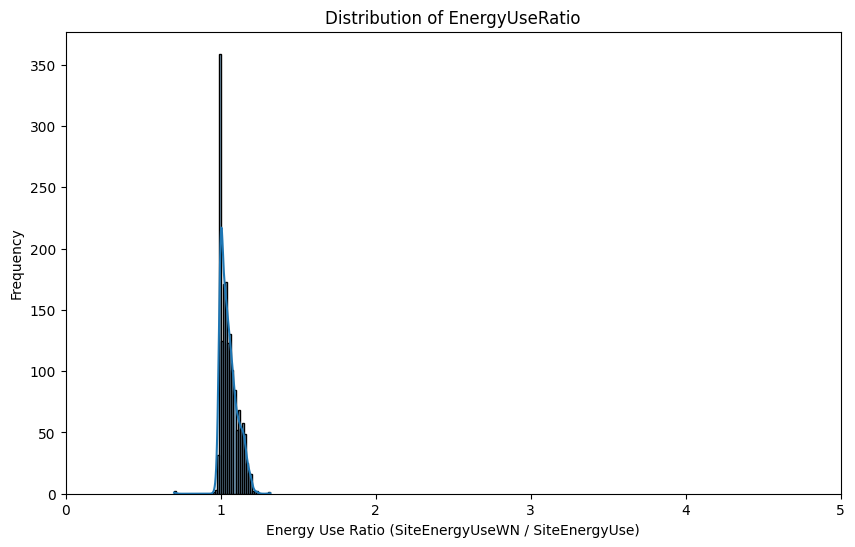

In [ ]:
# @title Check the relationship between SiteEnergyUseWN(kBtu) and SiteEnergyUse(kBtu)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Check if both required columns exist
if 'SiteEnergyUseWN(kBtu)' in building_consumption.columns and 'SiteEnergyUse(kBtu)' in building_consumption.columns:
    # Create the EnergyUseRatio feature, handling potential division by zero
    # Add a small epsilon to the denominator to avoid division by zero
    epsilon = 1e-9
    building_consumption['EnergyUseRatio'] = building_consumption['SiteEnergyUseWN(kBtu)'] / (building_consumption['SiteEnergyUse(kBtu)'] + epsilon)

    print("Created 'EnergyUseRatio' feature.")

    # Display descriptive statistics for the new feature
    print("\nDescriptive statistics for 'EnergyUseRatio':")
    display(building_consumption['EnergyUseRatio'].describe())

    # Plot a histogram of the EnergyUseRatio
    plt.figure(figsize=(10, 6))
    sns.histplot(data=building_consumption, x='EnergyUseRatio', kde=True)
    plt.title('Distribution of EnergyUseRatio')
    plt.xlabel('Energy Use Ratio (SiteEnergyUseWN / SiteEnergyUse)')
    plt.ylabel('Frequency')
    # Set a reasonable x-axis limit to focus on the main distribution, as ratios can be large
    plt.xlim(0, 5)
    plt.show()

else:
    print("Error: 'SiteEnergyUseWN(kBtu)' or 'SiteEnergyUse(kBtu)' not found in the DataFrame. Cannot calculate EnergyUseRatio.")
    # Optionally, print the current columns again for the user to see
    print("\nCurrent columns in the DataFrame:")
    print(building_consumption.columns.tolist())

In [ ]:
# @title Drop the 'EnergyUseRatio' column
if 'EnergyUseRatio' in building_consumption.columns:
    building_consumption = building_consumption.drop('EnergyUseRatio', axis=1)
    print("'EnergyUseRatio' column dropped.")
else:
    print("'EnergyUseRatio' column was not found.")

# Display the remaining columns to confirm the change
print("\nRemaining columns:")
print(building_consumption.columns.tolist())

'EnergyUseRatio' column dropped.

Remaining columns:
['BuildingType', 'PrimaryPropertyType', 'ZipCode', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'Outlier', 'TotalGHGEmissions']


In [ ]:
# @title analyze_variables function to analyse the remaining variables after variable removal

summary_df = analyze_variables(building_consumption)

# Save the summary DataFrame to a CSV file in the active directory
summary_df.to_excel('variable_analysis_summary_after_cleansing.xlsx', index=False)

print("Variable analysis summary saved to 'variable_analysis_summary_after_cleansing")


Variable analysis summary saved to 'variable_analysis_summary_after_cleansing


In [ ]:
# @title change variable types to valid type

import pandas as pd

# Define the path to the variable type changes file
type_changes_file_path = 'variable_type_changes.xlsx'

# Read the variable type changes file into a DataFrame
try:
    type_changes_df = pd.read_excel(type_changes_file_path)
    print(f"Successfully read variable type changes file: {type_changes_file_path}")
    display(type_changes_df.head()) # Display the head of the mapping file to confirm

    # Iterate through the type changes and apply them to the building_consumption DataFrame
    changes_made_count = 0
    for index, row in type_changes_df.iterrows():
        variable_name = row['Variable']
        desired_type = row['New_Type'] # Corrected column name to 'New_Type'

        if variable_name in building_consumption.columns:
            try:
                # Attempt to convert the column to the desired type
                building_consumption[variable_name] = building_consumption[variable_name].astype(desired_type)
                print(f"Changed type of '{variable_name}' to '{desired_type}'")
                changes_made_count += 1
            except Exception as e:
                print(f"Could not change type of '{variable_name}' to '{desired_type}': {e}")
        else:
            print(f"Warning: Column '{variable_name}' not found in the DataFrame.")

    print(f"\nApplied type changes to {changes_made_count} variables.")

    # Verify the data types after the changes
    print("\nData types after applying changes:")
    display(building_consumption.dtypes)

except FileNotFoundError:
    print(f"Error: Variable type changes file not found at '{type_changes_file_path}'. Please ensure the file is in the correct directory.")
except Exception as e:
    print(f"An error occurred while reading the type changes file or applying the changes: {e}")

Error: Variable type changes file not found at 'variable_type_changes.xlsx'. Please ensure the file is in the correct directory.


In [ ]:
# @title Remove observations tagged as outliers
initial_rows = len(building_consumption)
building_consumption = building_consumption[building_consumption['Outlier'].isnull()].copy()
rows_after_removing_outliers = len(building_consumption)

print(f"Number of rows before removing outliers: {initial_rows}")
print(f"Number of rows after removing outliers: {rows_after_removing_outliers}")
print(f"Number of outlier rows removed: {initial_rows - rows_after_removing_outliers}")

# Now drop the 'Outlier' column as it's no longer needed after filtering
if 'Outlier' in building_consumption.columns:
    building_consumption = building_consumption.drop('Outlier', axis=1)
    print("\n'Outlier' column dropped after filtering.")
else:
    print("\n'Outlier' column was not found after filtering.")

# Display the first few rows and the remaining columns

print("\nRemaining columns:")
print(building_consumption.columns.tolist())

Number of rows before removing outliers: 1650
Number of rows after removing outliers: 1633
Number of outlier rows removed: 17

'Outlier' column dropped after filtering.

Remaining columns:
['BuildingType', 'PrimaryPropertyType', 'ZipCode', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']


In [ ]:
# @title Drop the 'SiteEnergyUse(kBtu)' column
if 'SiteEnergyUse(kBtu)' in building_consumption.columns:
    building_consumption = building_consumption.drop('SiteEnergyUse(kBtu)', axis=1)
    print("'SiteEnergyUse(kBtu)' column dropped.")
else:
    print("'SiteEnergyUse(kBtu)' column was not found.")

# Display the remaining columns to confirm the change
print("\nRemaining columns:")
print(building_consumption.columns.tolist())

'SiteEnergyUse(kBtu)' column dropped.

Remaining columns:
['BuildingType', 'PrimaryPropertyType', 'ZipCode', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']


In [ ]:
# @title Missing values filled with 0 and NaN , quantitative and qualitative variables

import numpy as np

# Identify quantitative and qualitative columns
quantitative_cols = building_consumption.select_dtypes(include=np.number).columns
qualitative_cols = building_consumption.select_dtypes(include='object').columns

print("Missing values before filling:")
display(building_consumption.isnull().sum())

# Fill missing values in quantitative columns with 0
for col in quantitative_cols:
    if building_consumption[col].isnull().any():
        initial_missing = building_consumption[col].isnull().sum()
        building_consumption[col].fillna(0, inplace=True)
        filled_count = initial_missing - building_consumption[col].isnull().sum()
        if filled_count > 0:
            print(f"Filled {filled_count} missing values with 0 in quantitative column '{col}'")
        else:
             print(f"No missing values found to fill in quantitative column '{col}'")


# Qualitative columns should remain NaN, so no action is needed to fill them with 0

print("\nMissing values after filling quantitative columns with 0:")
display(building_consumption.isnull().sum())

Missing values before filling:


,0
BuildingType,0
PrimaryPropertyType,0
ZipCode,16
YearBuilt,0
NumberofBuildings,0
NumberofFloors,0
PropertyGFAParking,0
PropertyGFABuilding(s),0
LargestPropertyUseType,4
LargestPropertyUseTypeGFA,4


Filled 16 missing values with 0 in quantitative column 'ZipCode'
Filled 4 missing values with 0 in quantitative column 'LargestPropertyUseTypeGFA'
Filled 786 missing values with 0 in quantitative column 'SecondLargestPropertyUseTypeGFA'
Filled 1282 missing values with 0 in quantitative column 'ThirdLargestPropertyUseTypeGFA'
Filled 551 missing values with 0 in quantitative column 'ENERGYSTARScore'

Missing values after filling quantitative columns with 0:


,0
BuildingType,0
PrimaryPropertyType,0
ZipCode,0
YearBuilt,0
NumberofBuildings,0
NumberofFloors,0
PropertyGFAParking,0
PropertyGFABuilding(s),0
LargestPropertyUseType,4
LargestPropertyUseTypeGFA,0


In [ ]:
# @title Check if LargestPropertyUseType and PrimaryPropertyType have the same values

# Convert columns to string type for comparison to avoid TypeError if categories differ
largest_type_str = building_consumption['LargestPropertyUseType'].astype(str)
primary_type_str = building_consumption['PrimaryPropertyType'].astype(str)

# We need to handle potential NaN values when comparing
# Convert pandas NA to np.nan for consistent comparison with string representation of NaN ('nan')
largest_type_str = largest_type_str.replace('nan', np.nan)
primary_type_str = primary_type_str.replace('nan', np.nan)


different_types_mask = largest_type_str != primary_type_str


# Also consider cases where one is NaN and the other is not
# If both are NaN, they are considered the same for this purpose.
# The line below is no longer needed after converting to strings and handling np.nan
# different_types_mask = different_types_mask | (building_consumption['LargestPropertyUseType'].isnull() != building_consumption['PrimaryPropertyType'].isnull())


# Filter the DataFrame to get observations where the types are different
observations_with_different_types = building_consumption[different_types_mask].copy() # Add .copy() to avoid SettingWithCopyWarning


# Display the observations where LargestPropertyUseType and PrimaryPropertyType are different
print("Observations where LargestPropertyUseType and PrimaryPropertyType are different:")
display(observations_with_different_types[['LargestPropertyUseType', 'PrimaryPropertyType']])

print(f"\nNumber of observations where LargestPropertyUseType and PrimaryPropertyType are different: {len(observations_with_different_types)}")

# Export only the two concerned columns to an Excel file
excel_filename = 'LargestPropertyUseType_PrimaryPropertyType_Comparison.xlsx'
observations_with_different_types[['LargestPropertyUseType', 'PrimaryPropertyType']].to_excel(excel_filename, index=False)
print(f"\nObservations with different LargestPropertyUseType and PrimaryPropertyType saved to '{excel_filename}'")

Observations where LargestPropertyUseType and PrimaryPropertyType are different:


,LargestPropertyUseType,PrimaryPropertyType
5,Police Station,Other
7,Other - Entertainment/Public Assembly,Other
15,Library,Other
16,Fitness Center/Health Club/Gym,Other
18,Social/Meeting Hall,Mixed Use Property
...,...,...
3370,Other - Recreation,Other
3372,Other - Recreation,Other
3373,Other - Recreation,Other
3374,Other - Recreation,Mixed Use Property



Number of observations where LargestPropertyUseType and PrimaryPropertyType are different: 1020

Observations with different LargestPropertyUseType and PrimaryPropertyType saved to 'LargestPropertyUseType_PrimaryPropertyType_Comparison.xlsx'


In [ ]:
# @title Keep LargestPropertyUseType and replace some values from PrimaryPropertyType
import pandas as pd
import numpy as np

# Define the path to the mapping file (using just the filename as it's in the active directory)
mapping_file_path = 'LargestPropertyUseType_PrimaryPropertyType_Conversion.xlsx'

# Read the mapping file into a DataFrame
try:
    # Assuming the mapping file has columns named 'PrimaryPropertyType', 'LargestPropertyUseType',
    # and 'New Value in LargestPropertyUseType'
    mapping_df = pd.read_excel(mapping_file_path)
    print(f"Successfully read mapping file: {mapping_file_path}")
    display(mapping_df.head())  # Display the head of the mapping file to confirm

    # Convert 'LargestPropertyUseType' to categorical if it's not already
    if not pd.api.types.is_categorical_dtype(building_consumption['LargestPropertyUseType']):
        building_consumption['LargestPropertyUseType'] = building_consumption['LargestPropertyUseType'].astype('category')
        print("Converted 'LargestPropertyUseType' to categorical dtype.")

    # Get the new values from the mapping file that are not in the current categories
    new_categories = mapping_df['New Value in LargestPropertyUseType'].unique()
    current_categories = building_consumption['LargestPropertyUseType'].cat.categories
    categories_to_add = [cat for cat in new_categories if cat not in current_categories]

    # Add the new categories to the 'LargestPropertyUseType' column
    if categories_to_add:
        building_consumption['LargestPropertyUseType'] = building_consumption['LargestPropertyUseType'].cat.add_categories(categories_to_add)
        print(f"Added new categories to 'LargestPropertyUseType': {categories_to_add}")
    else:
        print("No new categories to add to 'LargestPropertyUseType'.")

    # Keep a copy of the original LargestPropertyUseType to track changes
    original_largest_type = building_consumption['LargestPropertyUseType'].copy()

    # Iterate through the mapping rules and apply them
    changes_made = 0
    for index, row in mapping_df.iterrows():
        primary_type_map = row['PrimaryPropertyType']
        largest_type_map = row['LargestPropertyUseType']
        new_value = row['New Value in LargestPropertyUseType']

        # Create a mask for rows that match the mapping rule
        # Handle both cases: LargestPropertyUseType matches the map value OR LargestPropertyUseType is NaN and PrimaryPropertyType matches
        if pd.isna(largest_type_map):
            # Case: Mapping rule is for when LargestPropertyUseType is NaN
            mask = (building_consumption['PrimaryPropertyType'].astype(str) == str(primary_type_map)) & \
                   (building_consumption['LargestPropertyUseType'].isnull())
        else:
            # Case: Mapping rule is for a specific LargestPropertyUseType value
            mask = (building_consumption['PrimaryPropertyType'].astype(str) == str(primary_type_map)) & \
                   (building_consumption['LargestPropertyUseType'].astype(str) == str(largest_type_map))


        # Apply the new value only to the rows that match the mask
        # Use .loc to avoid SettingWithCopyWarning
        building_consumption.loc[mask, 'LargestPropertyUseType'] = new_value

        # Count how many changes were made in this iteration
        changes_made_in_iter = mask.sum()
        changes_made += changes_made_in_iter

    # Report total changes
    print(f"Rows updated in LargestPropertyUseType: {changes_made}")

    # Identify and display the changed rows
    changed_rows_mask = original_largest_type != building_consumption['LargestPropertyUseType']

    if changed_rows_mask.sum() > 0:
        print("\nRows where LargestPropertyUseType was changed:")
        display(building_consumption.loc[changed_rows_mask, ['PrimaryPropertyType', 'LargestPropertyUseType']].head(changed_rows_mask.sum()))

        # Export the changed rows to an Excel file (optional, based on previous steps)
        # excel_filename_changed = 'property_types_changed_rows.xlsx'
        # building_consumption.loc[changed_rows_mask, ['PrimaryPropertyType', 'LargestPropertyUseType']].to_excel(excel_filename_changed, index=False)
        # print(f"\nChanged rows of PrimaryPropertyType and LargestPropertyUseType exported to '{excel_filename_changed}'")

    else:
        print("\nNo rows were changed based on the provided mapping rules.")


    # Display the first few rows of the entire DataFrame to show the change in context
    print("\nFirst few rows of the updated DataFrame:")
    display(building_consumption[['PrimaryPropertyType', 'LargestPropertyUseType']].head())

except FileNotFoundError:
    print(f"Error: Mapping file not found at '{mapping_file_path}'. Please ensure the file is in the correct directory.")
except Exception as e:
    print(f"An error occurred while reading the mapping file or applying the mapping: {e}")

Successfully read mapping file: LargestPropertyUseType_PrimaryPropertyType_Conversion.xlsx


,PrimaryPropertyType,LargestPropertyUseType,New Value in LargestPropertyUseType
0,Large Office,Office,Large Office
1,Retail Store,Other,Retail Store
2,Small- and Mid-Sized Office,Office,Small- and Mid-Sized Office
3,Hotel,NaN,Hotel
4,Restaurant,NaN,Restaurant


Converted 'LargestPropertyUseType' to categorical dtype.
Added new categories to 'LargestPropertyUseType': ['Large Office', 'Small- and Mid-Sized Office']
Rows updated in LargestPropertyUseType: 462

Rows where LargestPropertyUseType was changed:


,PrimaryPropertyType,LargestPropertyUseType
32,Small- and Mid-Sized Office,Small- and Mid-Sized Office
39,Small- and Mid-Sized Office,Small- and Mid-Sized Office
40,Small- and Mid-Sized Office,Small- and Mid-Sized Office
44,Large Office,Large Office
46,Small- and Mid-Sized Office,Small- and Mid-Sized Office
...,...,...
3317,Large Office,Large Office
3320,Large Office,Large Office
3324,Large Office,Large Office
3329,Large Office,Large Office



First few rows of the updated DataFrame:


,PrimaryPropertyType,LargestPropertyUseType
0,Hotel,Hotel
1,Hotel,Hotel
2,Hotel,Hotel
3,Hotel,Hotel
4,Hotel,Hotel


In [ ]:
# @title Drop the 'PrimaryPropertyType' column
if 'PrimaryPropertyType' in building_consumption.columns:
    building_consumption = building_consumption.drop('PrimaryPropertyType', axis=1)
    print("'PrimaryPropertyType' column dropped.")
else:
    print("'PrimaryPropertyType' column was not found.")



'PrimaryPropertyType' column dropped.


In [ ]:
# @title Listing of Property Types in LargestPropertyUseType


import pandas as pd

# Define the column to analyze
property_type_col = 'LargestPropertyUseType'

# Check if the column exists
if property_type_col in building_consumption.columns:
    # Get unique values and their counts for the column, including NaN if any exist
    value_counts = building_consumption[property_type_col].value_counts(dropna=False)

    # Convert the value counts Series to a DataFrame for export
    largest_property_type_analysis_df = value_counts.reset_index()
    largest_property_type_analysis_df.columns = [property_type_col, 'Count']

    # Export the DataFrame to an Excel file
    excel_filename = f'{property_type_col}_unique_values_analysis.xlsx'
    largest_property_type_analysis_df.to_excel(excel_filename, index=False)

    print(f"Analysis of unique values in '{property_type_col}' saved to '{excel_filename}'")


else:
    print(f"Error: Column '{property_type_col}' not found in the DataFrame.")

Analysis of unique values in 'LargestPropertyUseType' saved to 'LargestPropertyUseType_unique_values_analysis.xlsx'


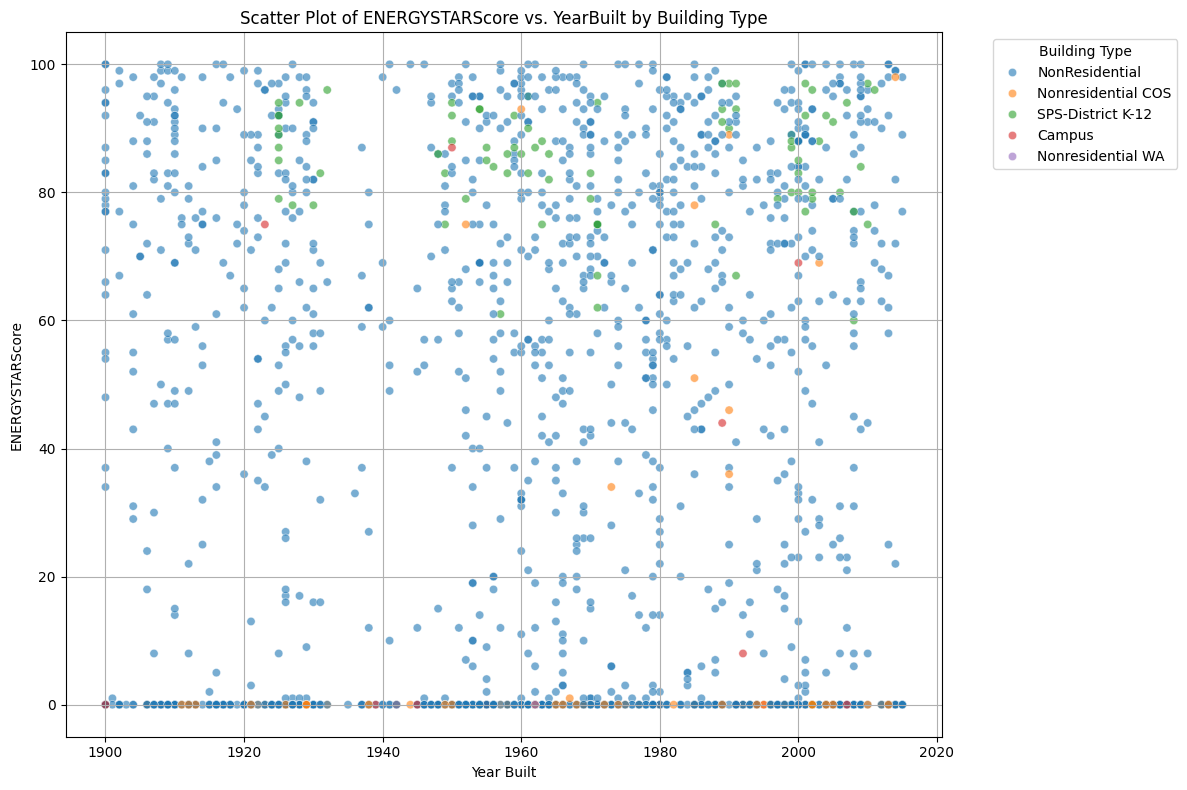

In [ ]:
# @title Plot ENERGYSTARScore against YearBuilt and Building Type

import matplotlib.pyplot as plt
import seaborn as sns

# Create a scatter plot of ENERGYSTARScore against YearBuilt, colored by BuildingType
plt.figure(figsize=(12, 8)) # Increased figure size for better visibility with more colors
sns.scatterplot(data=building_consumption, x='YearBuilt', y='ENERGYSTARScore', hue='BuildingType', alpha=0.6)
plt.title('Scatter Plot of ENERGYSTARScore vs. YearBuilt by Building Type')
plt.xlabel('Year Built')
plt.ylabel('ENERGYSTARScore')
plt.grid(True)
plt.legend(title='Building Type', bbox_to_anchor=(1.05, 1), loc='upper left') # Move legend outside plot
plt.tight_layout() # Adjust layout to prevent legend overlapping
plt.show()

Created 'SiteEnergyUSe/GFAbuildings' column.
DataFrame sorted by 'SiteEnergyUSe/GFAbuildings'.

Distribution of ENERGYSTARScore after sorting by SiteEnergyUSe/GFAbuildings:


,ENERGYSTARScore
count,1633.000000
mean,43.173301
std,38.508291
min,0.000000
25%,0.000000
50%,47.000000
75%,81.000000
max,100.000000


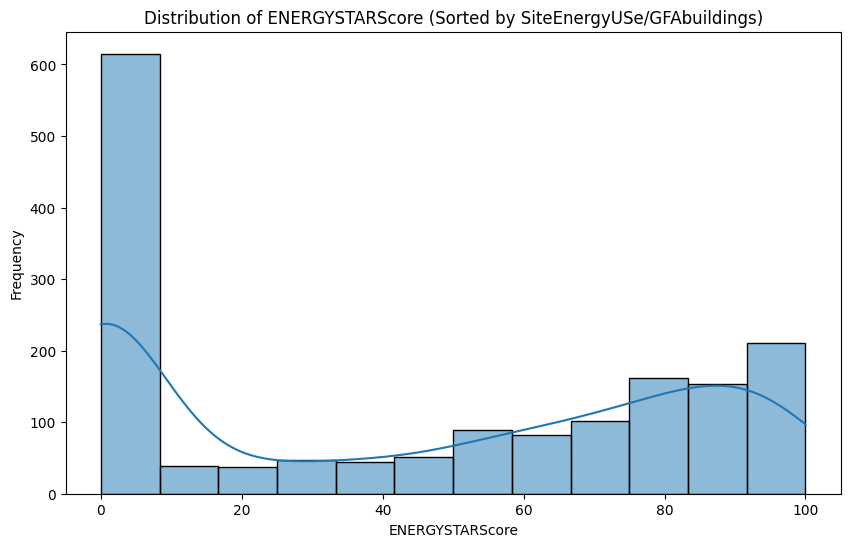

In [ ]:
# @title Plot ENERGYSTARScore against SiteEnergyUse/GFAbuildings

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Check if required columns exist before proceeding
required_cols = ['SiteEnergyUseWN(kBtu)', 'PropertyGFABuilding(s)', 'ENERGYSTARScore']
if all(col in building_consumption.columns for col in required_cols):

    # 1) Create the new column SiteEnergyUSe/GFAbuildings
    # Add a small epsilon to avoid division by zero if 'PropertyGFABuilding(s)' is 0
    epsilon = 1e-9
    building_consumption['SiteEnergyUSe/GFAbuildings'] = building_consumption['SiteEnergyUseWN(kBtu)'] / (building_consumption['PropertyGFABuilding(s)'] + epsilon)

    print("Created 'SiteEnergyUSe/GFAbuildings' column.")

    # 2) Sort the DataFrame by the new column in ascending order
    building_consumption_sorted = building_consumption.sort_values(by='SiteEnergyUSe/GFAbuildings', ascending=True).copy()

    print("DataFrame sorted by 'SiteEnergyUSe/GFAbuildings'.")

    # 3) Show the distribution of ENERGYSTARScore after sorting
    print("\nDistribution of ENERGYSTARScore after sorting by SiteEnergyUSe/GFAbuildings:")

    # Display descriptive statistics
    display(building_consumption_sorted['ENERGYSTARScore'].describe())

    # Plot a histogram
    plt.figure(figsize=(10, 6))
    sns.histplot(data=building_consumption_sorted, x='ENERGYSTARScore', kde=True)
    plt.title('Distribution of ENERGYSTARScore (Sorted by SiteEnergyUSe/GFAbuildings)')
    plt.xlabel('ENERGYSTARScore')
    plt.ylabel('Frequency')
    plt.show()

else:
    missing = [col for col in required_cols if col not in building_consumption.columns]
    print(f"Error: The following required columns are missing: {missing}. Cannot perform requested operations.")
    print("\nCurrent columns in the DataFrame:")
    print(building_consumption.columns.tolist())

In [ ]:
# @title Fill Missing Values of ENERGYSTARScore by interpolation and extrapolation with mean

import numpy as np
import pandas as pd

# Ensure 'SiteEnergyUSe/GFAbuildings' exists and the DataFrame is sorted
# Recreate SiteEnergyUSe/GFAbuildings and sort if not already done or if original DataFrame was modified
required_sort_cols = ['SiteEnergyUseWN(kBtu)', 'PropertyGFABuilding(s)', 'ENERGYSTARScore']
if all(col in building_consumption.columns for col in required_sort_cols):
    if 'SiteEnergyUSe/GFAbuildings' not in building_consumption.columns:
        epsilon = 1e-9
        building_consumption['SiteEnergyUSe/GFAbuildings'] = building_consumption['SiteEnergyUseWN(kBtu)'] / (building_consumption['PropertyGFABuilding(s)'] + epsilon)
        print("Created 'SiteEnergyUSe/GFAbuildings' column.")

    # Create a sorted copy for interpolation
    building_consumption_sorted = building_consumption.sort_values(by='SiteEnergyUSe/GFAbuildings', ascending=True).copy()
    print("DataFrame sorted by 'SiteEnergyUSe/GFAbuildings'.")

    # 1) Replace zero values in ENERGYSTARScore with NaN in the sorted DataFrame
    initial_zeros = (building_consumption_sorted['ENERGYSTARScore'] == 0).sum()
    building_consumption_sorted['ENERGYSTARScore'] = building_consumption_sorted['ENERGYSTARScore'].replace(0, np.nan)
    nan_after_replace = building_consumption_sorted['ENERGYSTARScore'].isnull().sum()
    print(f"\nReplaced {initial_zeros} zero values in ENERGYSTARScore with NaN.")
    print(f"Missing values in ENERGYSTARScore before interpolation: {nan_after_replace}")


    # 2) Perform interpolation and extrapolation on the new NaNs
    building_consumption_sorted['ENERGYSTARScore_filled'] = building_consumption_sorted['ENERGYSTARScore'].interpolate(method='linear', limit_direction='both', limit_area=None)

    missing_after_interpolation = building_consumption_sorted['ENERGYSTARScore_filled'].isnull().sum()
    print(f"Missing values in ENERGYSTARScore after interpolation: {missing_after_interpolation}")
    print(f"Number of values filled by interpolation: {nan_after_replace - missing_after_interpolation}")

    # Update the original DataFrame with the interpolated values
    # Use the index to align the filled values correctly
    building_consumption['ENERGYSTARScore'] = building_consumption_sorted['ENERGYSTARScore_filled']

    print("\nUpdated 'ENERGYSTARScore' in original DataFrame with interpolated values.")

    # Verify no missing values remain in the original DataFrame's ENERGYSTARScore
    print("Missing values in ENERGYSTARScore in original DataFrame after update:")
    print(building_consumption['ENERGYSTARScore'].isnull().sum())


    # 3) Drop the 'SiteEnergyUSe/GFAbuildings' column from the original DataFrame
    if 'SiteEnergyUSe/GFAbuildings' in building_consumption.columns:
        building_consumption = building_consumption.drop('SiteEnergyUSe/GFAbuildings', axis=1)
        print("\n'SiteEnergyUSe/GFAbuildings' column dropped.")
    else:
        print("\n'SiteEnergyUSe/GFAbuildings' column was not found.")

    # Drop the temporary filled column from the sorted DataFrame if it exists
    if 'ENERGYSTARScore_filled' in building_consumption_sorted.columns:
         building_consumption_sorted = building_consumption_sorted.drop('ENERGYSTARScore_filled', axis=1)


else:
    missing = [col for col in required_sort_cols if col not in building_consumption.columns]
    print(f"Cannot perform zero filling and interpolation. The following required columns are missing: {missing}.")


# Display the first few rows and columns to confirm changes
print("\nFirst few rows and columns after filling ENERGYSTARScore zeros and dropping SiteEnergyUSe/GFAbuildings:")
display(building_consumption.head())
print("\nRemaining columns:")
print(building_consumption.columns.tolist())

DataFrame sorted by 'SiteEnergyUSe/GFAbuildings'.

Replaced 551 zero values in ENERGYSTARScore with NaN.
Missing values in ENERGYSTARScore before interpolation: 551
Missing values in ENERGYSTARScore after interpolation: 0
Number of values filled by interpolation: 551

Updated 'ENERGYSTARScore' in original DataFrame with interpolated values.
Missing values in ENERGYSTARScore in original DataFrame after update:
0

'SiteEnergyUSe/GFAbuildings' column dropped.

First few rows and columns after filling ENERGYSTARScore zeros and dropping SiteEnergyUSe/GFAbuildings:


,BuildingType,ZipCode,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions
0,NonResidential,98101.0,1927,1.0,12,0,88434,Hotel,88434.0,NaN,0.0,NaN,0.0,60.0,7456910.0,249.98
1,NonResidential,98101.0,1996,1.0,11,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8664479.0,295.86
2,NonResidential,98101.0,1969,1.0,41,196718,759392,Hotel,756493.0,NaN,0.0,NaN,0.0,43.0,73937112.0,2089.28
3,NonResidential,98101.0,1926,1.0,10,0,61320,Hotel,61320.0,NaN,0.0,NaN,0.0,56.0,6946800.5,286.43
4,NonResidential,98121.0,1980,1.0,18,62000,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14656503.0,505.01



Remaining columns:
['BuildingType', 'ZipCode', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']


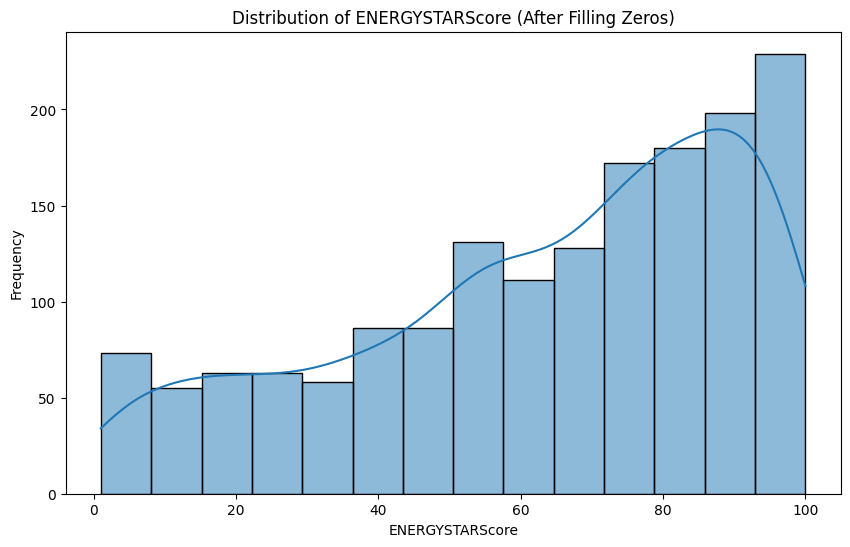

In [ ]:
# @title ENERGYSTARScore histogram after the filling of missing values



import matplotlib.pyplot as plt
import seaborn as sns

# Plot a histogram of the cleaned ENERGYSTARScore
plt.figure(figsize=(10, 6))
sns.histplot(data=building_consumption, x='ENERGYSTARScore', kde=True)
plt.title('Distribution of ENERGYSTARScore (After Filling Zeros)')
plt.xlabel('ENERGYSTARScore')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# @title Fill missing values in 'ZipCode' with '00000.0'

# Convert ZipCode to object dtype to allow adding new string values
building_consumption['ZipCode'] = building_consumption['ZipCode'].astype('object')

initial_missing_count = building_consumption['ZipCode'].isnull().sum()
building_consumption['ZipCode'].fillna('00000.0', inplace=True)
missing_after_fill = building_consumption['ZipCode'].isnull().sum()

print(f"Number of missing values in 'ZipCode' before filling: {initial_missing_count}")
print(f"Number of missing values in 'ZipCode' after filling: {missing_after_fill}")
print(f"Number of missing values filled: {initial_missing_count - missing_after_fill}")

# Verify the change by displaying sample values including the newly filled ones
print("\nSample values from 'ZipCode' after filling missing values:")
display(building_consumption['ZipCode'].sample(10))

# Optionally, check if '00000.0' now exists in the column
does_zero_zipcode_exist_after_fill = (building_consumption['ZipCode'] == '00000.0').any()
print(f"\nDoes '00000.0' now exist among the zip codes? {does_zero_zipcode_exist_after_fill}")

Number of missing values in 'ZipCode' before filling: 0
Number of missing values in 'ZipCode' after filling: 0
Number of missing values filled: 0

Sample values from 'ZipCode' after filling missing values:


,ZipCode
1237,98101.0
1889,98136.0
288,98101.0
1349,98116.0
2707,98104.0
278,98101.0
1780,98104.0
1513,98108.0
1971,98134.0
590,98108.0



Does '00000.0' now exist among the zip codes? False


In [ ]:
# @title Check for missing values (NaNs) and zero values for all columns
import pandas as pd
import numpy as np

missing_and_zero_counts = []

for col in building_consumption.columns:
    missing_count = building_consumption[col].isnull().sum()
    zero_count = (building_consumption[col] == 0).sum()

    # For numerical columns, also check for zeros that might be represented differently (e.g., float 0.0)
    if pd.api.types.is_numeric_dtype(building_consumption[col]):
        zero_count = (building_consumption[col] == 0).sum() # This handles both int 0 and float 0.0
    elif building_consumption[col].dtype == 'object' or pd.api.types.is_categorical_dtype(building_consumption[col]):
         # For object/categorical types, specifically check for string '0' if relevant, or just keep zero_count as 0 if not applicable
         # We'll assume numeric zero is not relevant for non-numeric types unless explicitly '0' string
         zero_count = (building_consumption[col].astype(str) == '0').sum()


    missing_and_zero_counts.append({
        'Variable': col,
        'Missing Count (NaN)': missing_count,
        'Zero Count': zero_count
    })

missing_and_zero_df = pd.DataFrame(missing_and_zero_counts)

print("Missing value and zero counts per variable:")
display(missing_and_zero_df)

Missing value and zero counts per variable:


,Variable,Missing Count (NaN),Zero Count
0,BuildingType,0,0
1,ZipCode,0,0
2,YearBuilt,0,0
3,NumberofBuildings,0,52
4,NumberofFloors,0,16
5,PropertyGFAParking,0,1302
6,PropertyGFABuilding(s),0,0
7,LargestPropertyUseType,0,0
8,LargestPropertyUseTypeGFA,0,4
9,SecondLargestPropertyUseType,786,0


In [ ]:
# @title remove  rows where LargestPropertyUseTypeGFA or TotalGHGEmissions are 0
initial_rows = len(building_consumption)
building_consumption = building_consumption[~((building_consumption['LargestPropertyUseTypeGFA'] == 0) | (building_consumption['TotalGHGEmissions'] == 0))].copy()
rows_after_removal = len(building_consumption)

print(f"Number of rows before removing rows where LargestPropertyUseTypeGFA or TotalGHGEmissions are 0: {initial_rows}")
print(f"Number of rows after removing rows where LargestPropertyUseTypeGFA or TotalGHGEmissions are 0: {rows_after_removal}")
print(f"Number of rows removed: {initial_rows - rows_after_removal}")



Number of rows before removing rows where LargestPropertyUseTypeGFA or TotalGHGEmissions are 0: 1633
Number of rows after removing rows where LargestPropertyUseTypeGFA or TotalGHGEmissions are 0: 1628
Number of rows removed: 5


In [ ]:
# @title correction of Inconsistent values wherein GFA is 0 but the PropertyType is filled
# Set ThirdLargestPropertyUseType to NaN where ThirdLargestPropertyUseTypeGFA is 0
building_consumption.loc[building_consumption['ThirdLargestPropertyUseTypeGFA'] == 0, 'ThirdLargestPropertyUseType'] = None

# Set SecondLargestPropertyUseType to NaN where SecondLargestPropertyUseTypeGFA is 0
building_consumption.loc[building_consumption['SecondLargestPropertyUseTypeGFA'] == 0, 'SecondLargestPropertyUseType'] = None

print("Updated 'ThirdLargestPropertyUseType' and 'SecondLargestPropertyUseType' based on GFA values.")

# Verify the changes by checking missing values again
print("\nMissing value counts after updating based on GFA:")
display(building_consumption[['SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType']].isnull().sum())

Updated 'ThirdLargestPropertyUseType' and 'SecondLargestPropertyUseType' based on GFA values.

Missing value counts after updating based on GFA:


,0
SecondLargestPropertyUseType,859
ThirdLargestPropertyUseType,1302


# DATA VISUALISATION


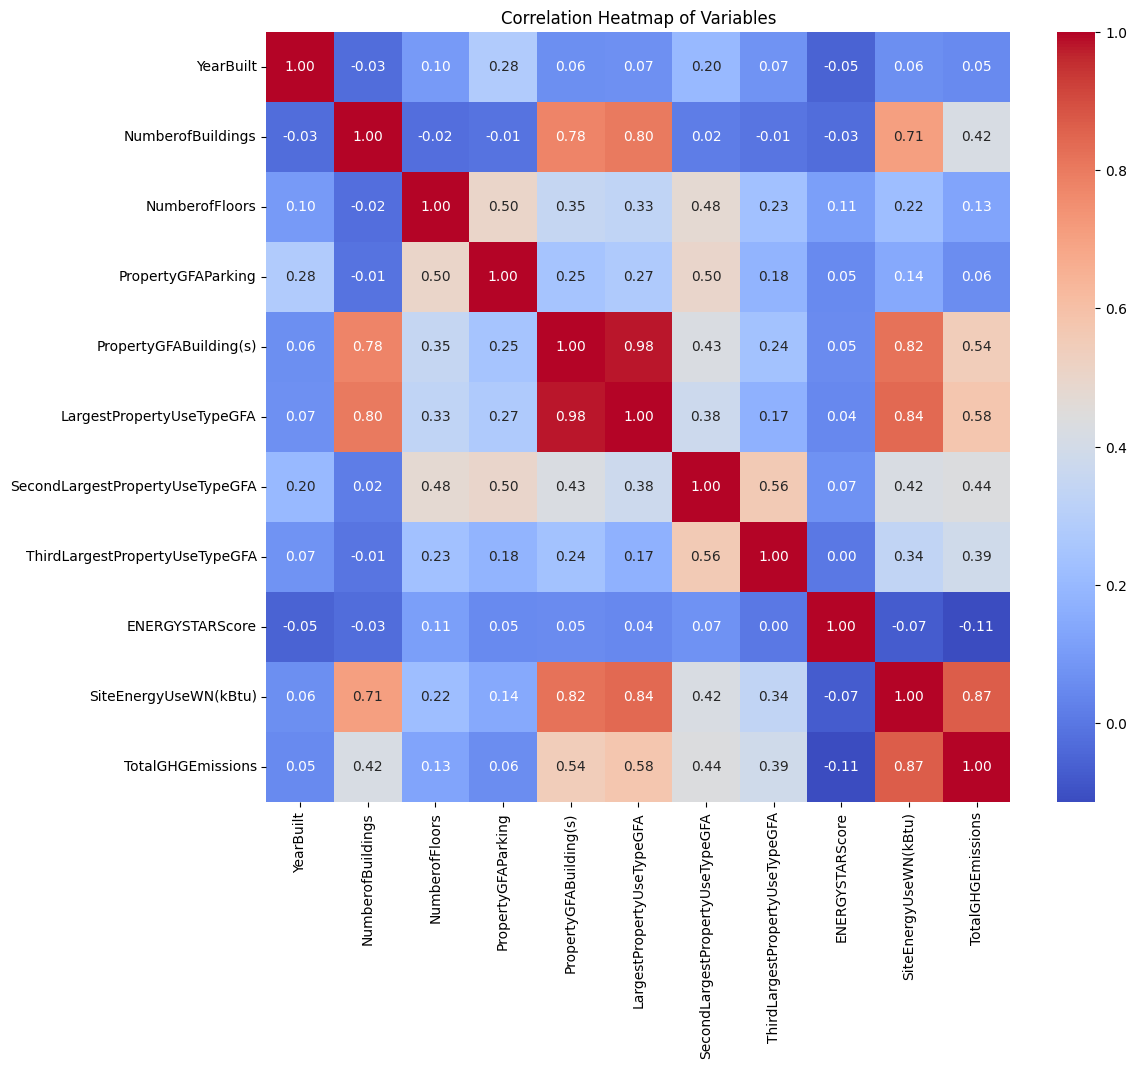

In [ ]:
# @title Correlation matrix

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix
correlation_matrix = building_consumption.corr(numeric_only=True)

# Create a heatmap of the correlation matrix
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Variables')
plt.show()

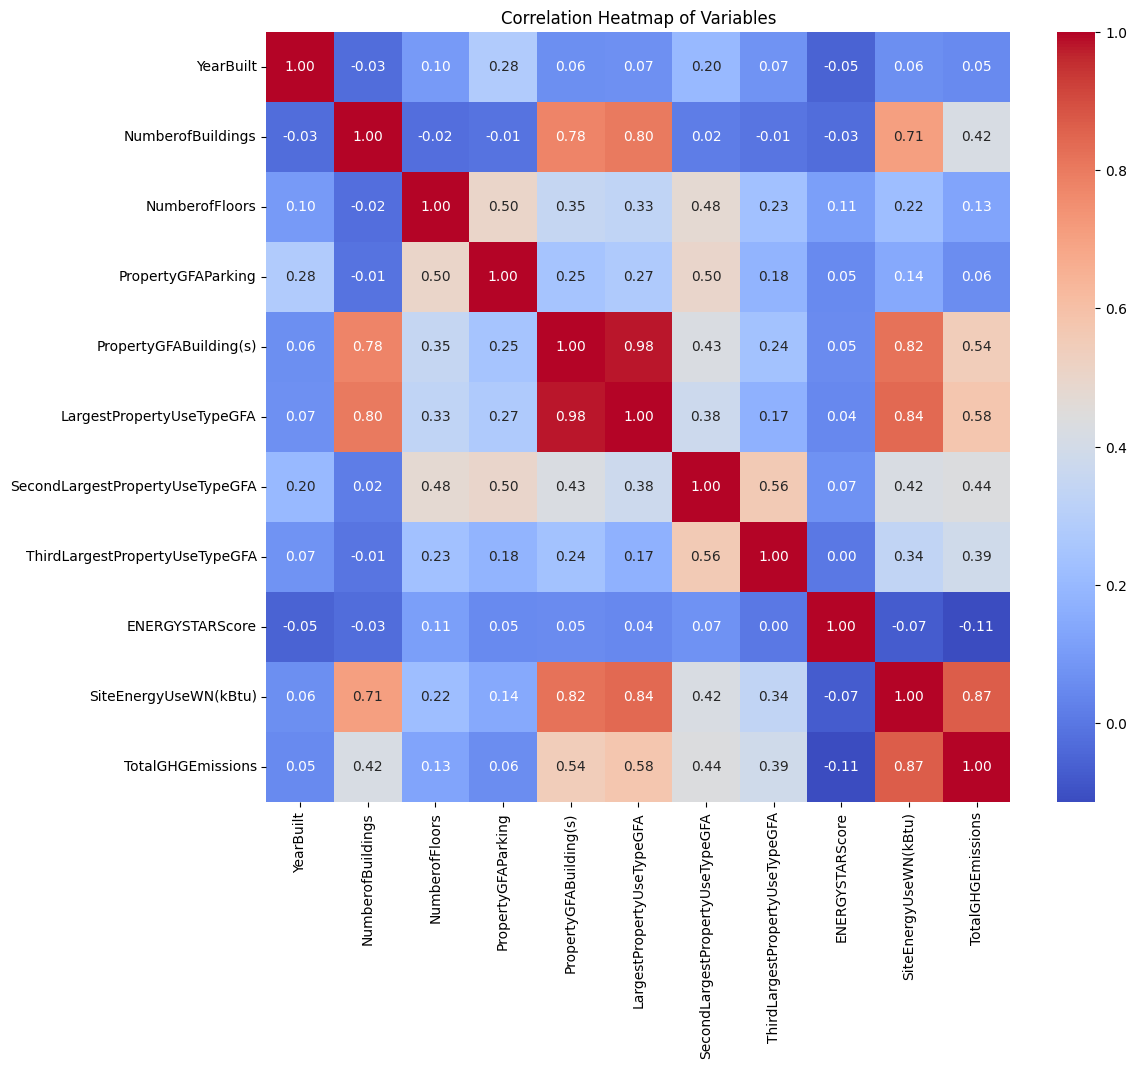

Pairs of features with absolute correlation >= 0.7:


,Feature 1,Feature 2,Absolute Correlation
49,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,0.982395
109,SiteEnergyUseWN(kBtu),TotalGHGEmissions,0.866874
64,LargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),0.842088
53,PropertyGFABuilding(s),SiteEnergyUseWN(kBtu),0.821505
16,NumberofBuildings,LargestPropertyUseTypeGFA,0.800157
15,NumberofBuildings,PropertyGFABuilding(s),0.775702
20,NumberofBuildings,SiteEnergyUseWN(kBtu),0.707209


In [ ]:
# @title Corelation matrix of old features
analyze_correlation(building_consumption)

Numerical columns for histogram plotting:
['YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']


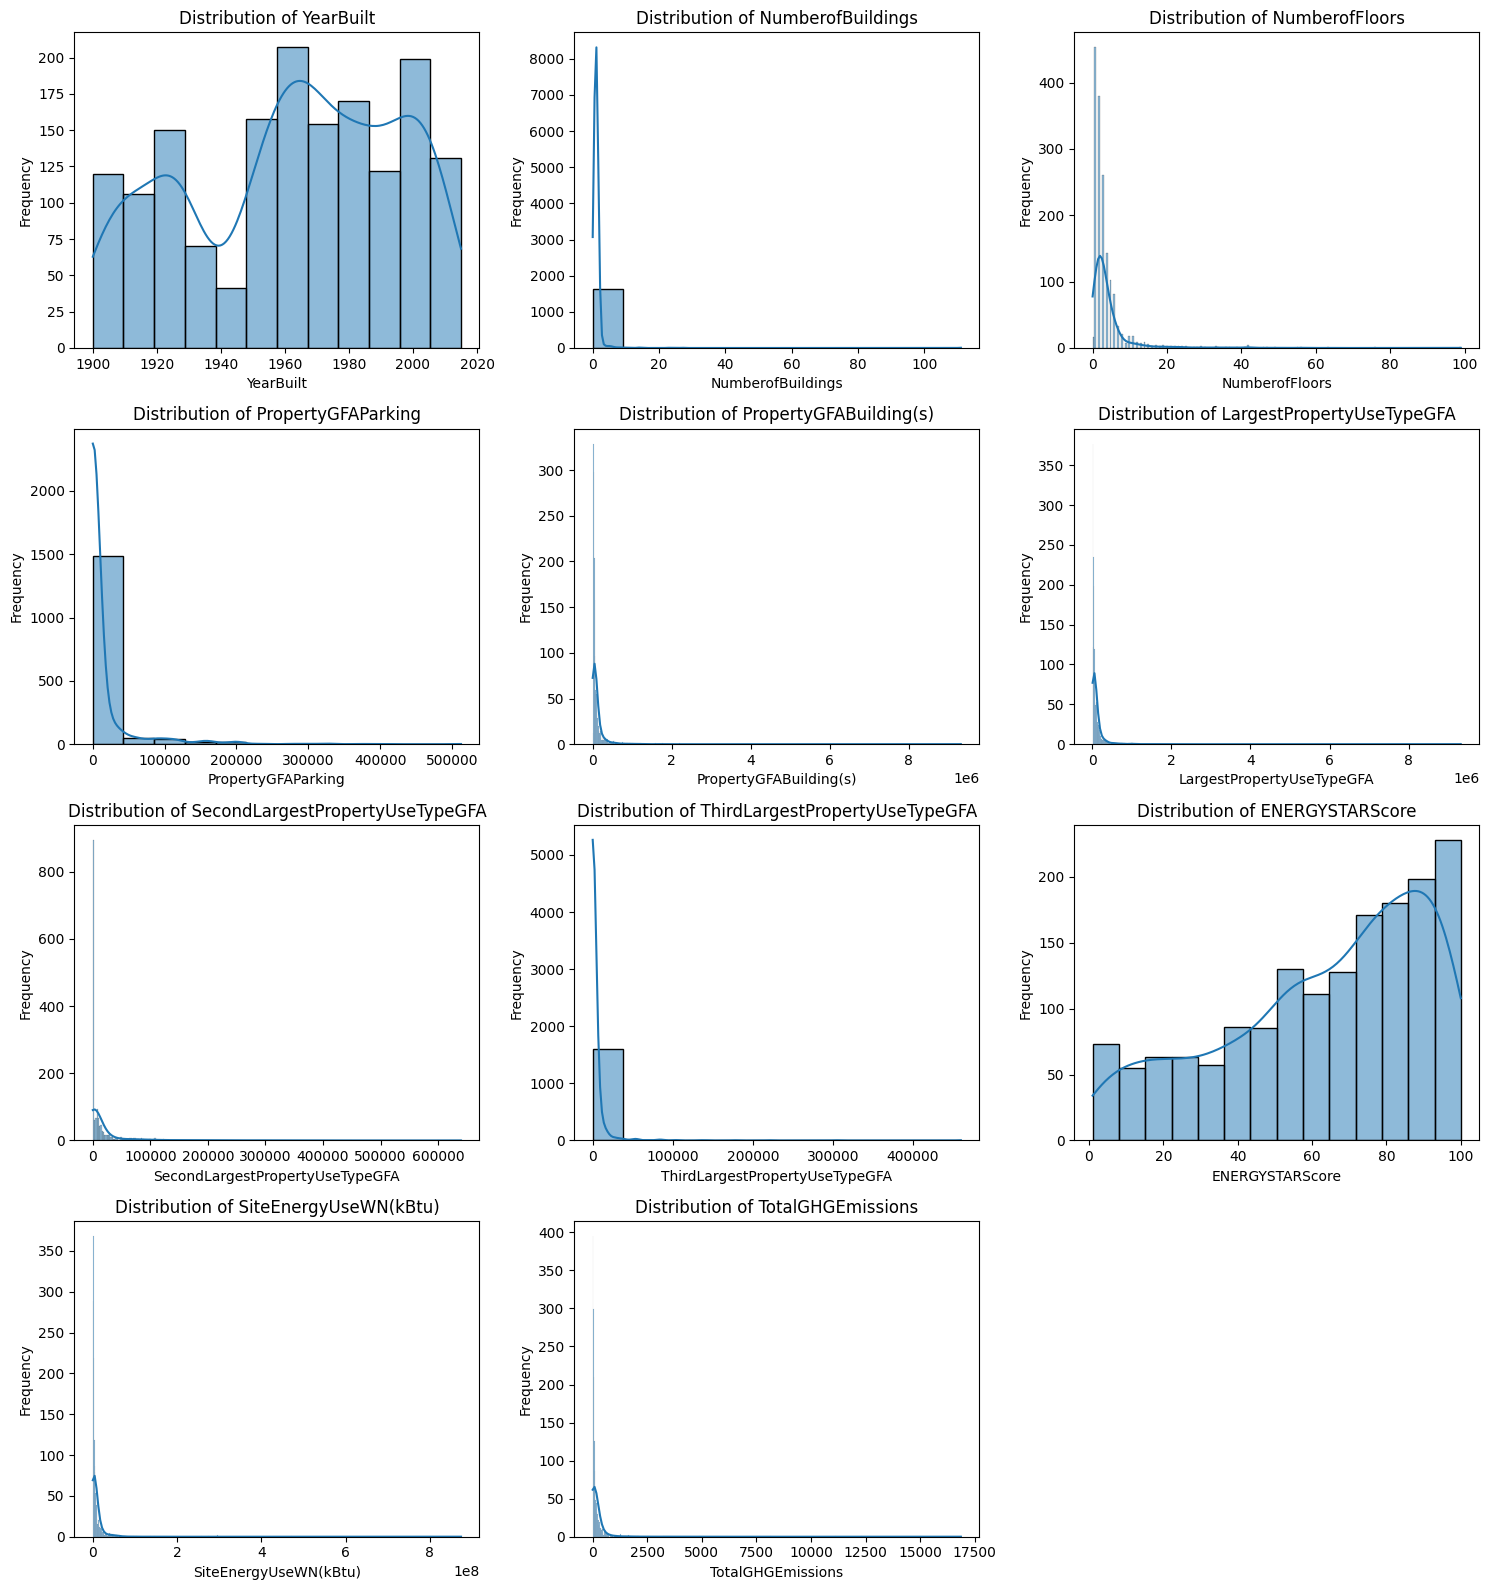

In [ ]:
# @title Plot histograms for quantitative variables
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numerical columns
numerical_cols = building_consumption.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns for histogram plotting:")
print(numerical_cols)

# Function to calculate descriptive statistics and outliers (keep as is, for potential use or removal later)
def get_stats_and_outliers(series, threshold=3):
    desc_stats = series.describe().to_string()
    # Calculate Z-scores
    mean = series.mean()
    std = series.std()
    if std == 0:
        outliers_count = 0
    else:
        z_scores = np.abs((series - mean) / std)
        outliers_count = (z_scores > threshold).sum()
    return desc_stats, outliers_count

# Determine grid size for subplots
n_cols = 3 # Number of columns in the subplot grid
n_rows = (len(numerical_cols) + n_cols - 1) // n_cols # Calculate number of rows needed

plt.figure(figsize=(n_cols * 5, n_rows * 4)) # Adjust figure size based on grid

# Create histograms for numerical variables in a grid of subplots
for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, n_cols, i + 1) # Select the current subplot
    sns.histplot(data=building_consumption, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout() # Adjust layout to prevent titles/labels overlapping
plt.show()

# The descriptive statistics and outlier text boxes from the previous version are removed for clarity in the side-by-side view.
# If needed, they could be added back or displayed separately.

Generating pair plots for a subset of quantitative columns due to the large number of variables.


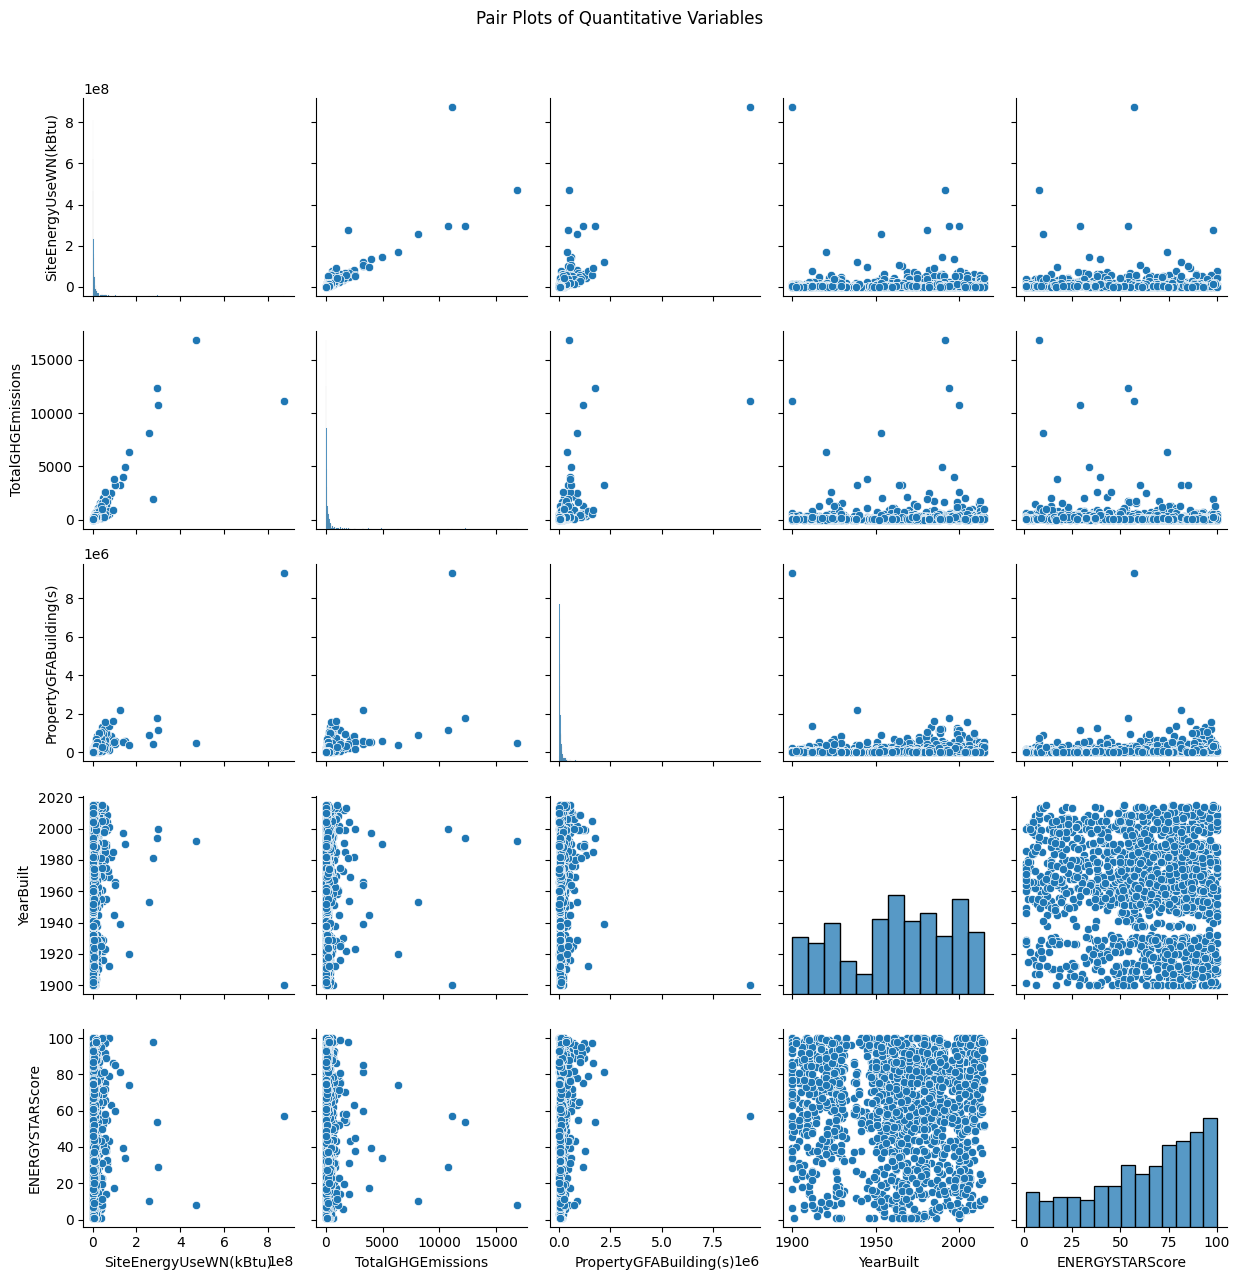

In [ ]:
# @title Plot pair plots for quantitative variables

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numerical columns
numerical_cols = building_consumption.select_dtypes(include=np.number).columns.tolist()

# Create pair plots
# Using a subset of columns if there are many to avoid an overly large plot
if len(numerical_cols) > 10: # Adjust threshold as needed
    print("Generating pair plots for a subset of quantitative columns due to the large number of variables.")
    # Select a relevant subset, e.g., target variables and some key features
    subset_cols = ['SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions', 'PropertyGFABuilding(s)', 'YearBuilt', 'ENERGYSTARScore'] # Example subset
    # Ensure all subset_cols are in the DataFrame
    subset_cols = [col for col in subset_cols if col in building_consumption.columns]
    if len(subset_cols) < 2: # Ensure there are at least two columns to plot pairs
         subset_cols = numerical_cols[:5] # Fallback to first 5 if subset is too small

    sns.pairplot(building_consumption[subset_cols])
else:
    print("Generating pair plots for all quantitative columns.")
    sns.pairplot(building_consumption[numerical_cols])


plt.suptitle('Pair Plots of Quantitative Variables', y=1.02) # Add a title
plt.tight_layout() # Adjust layout
plt.show()

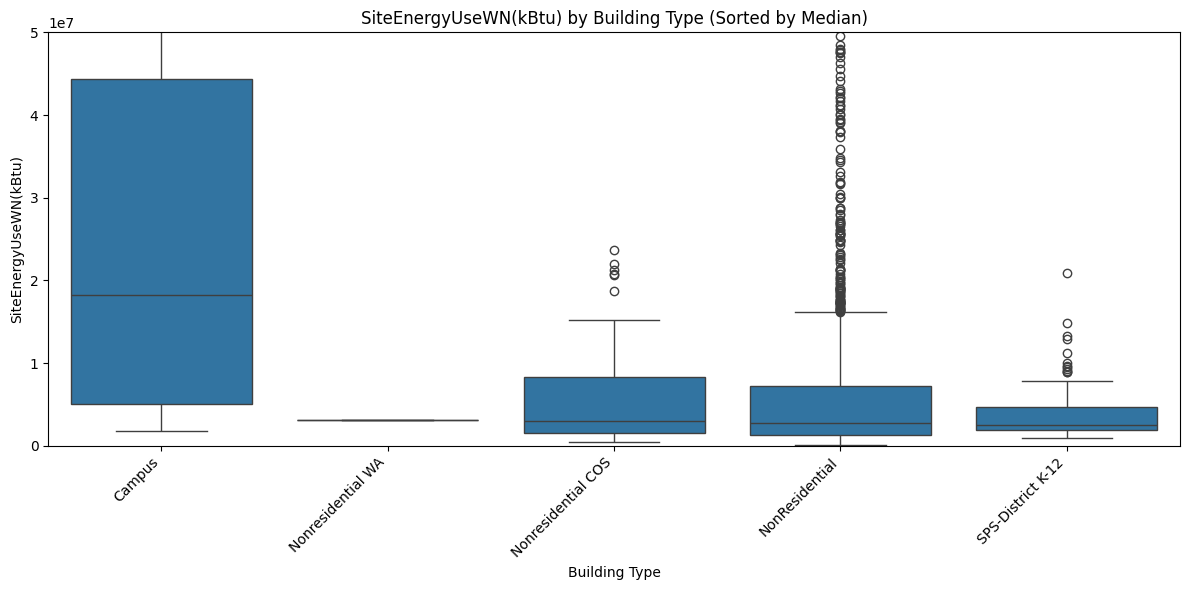

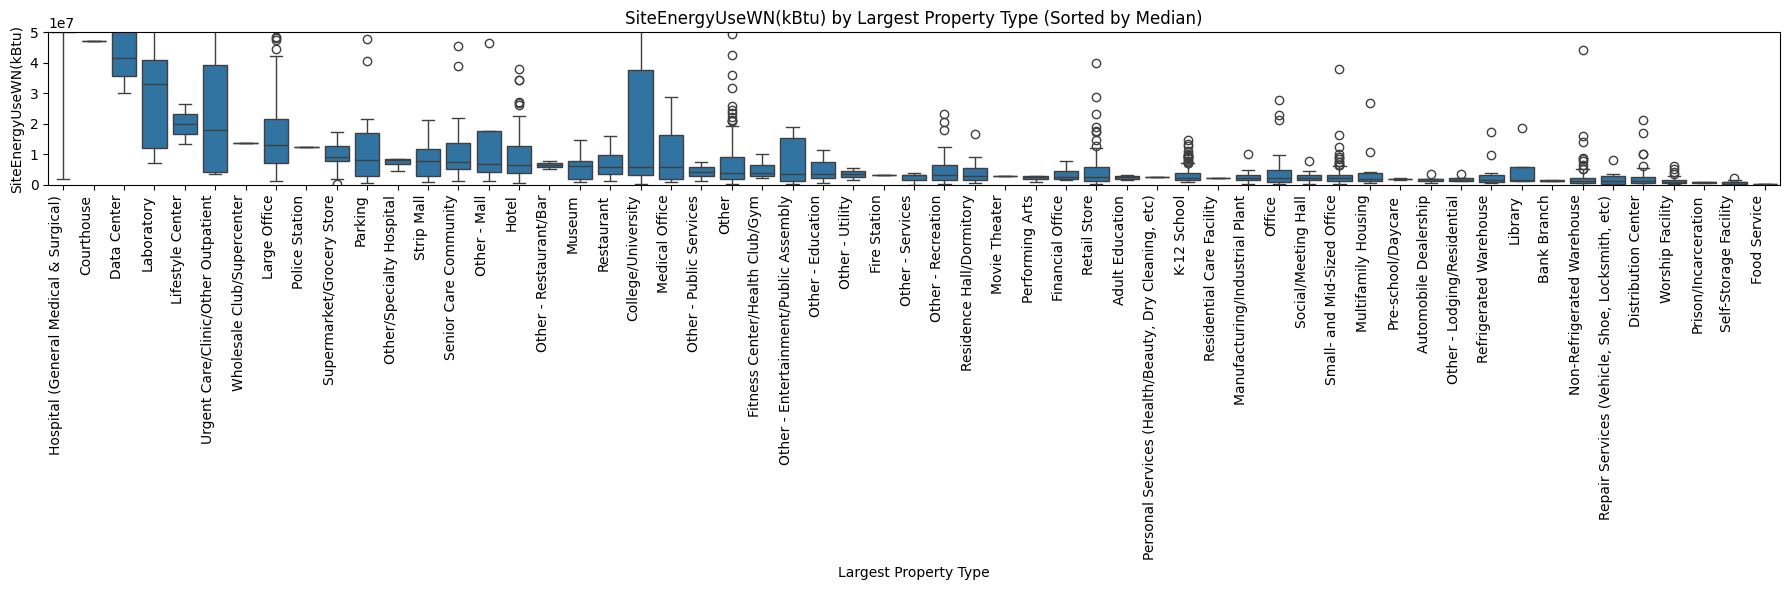

In [ ]:
# @title Plot Box Plots

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate order for BuildingType based on median SiteEnergyUseWN(kBtu)
building_type_order = building_consumption.groupby('BuildingType')['SiteEnergyUseWN(kBtu)'].median().sort_values(ascending=False).index

# Create a box plot of SiteEnergyUseWN(kBtu) by BuildingType, sorted by median
plt.figure(figsize=(12, 6))
sns.boxplot(data=building_consumption, x='BuildingType', y='SiteEnergyUseWN(kBtu)', order=building_type_order)
plt.title('SiteEnergyUseWN(kBtu) by Building Type (Sorted by Median)')
plt.xlabel('Building Type')
plt.ylabel('SiteEnergyUseWN(kBtu)')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.ylim(0, 50000000) # Set a reasonable y-axis limit for better visibility
plt.tight_layout()
plt.show()

# Calculate order for LargestPropertyUseType based on median SiteEnergyUseWN(kBtu)
largest_property_type_order = building_consumption.groupby('LargestPropertyUseType')['SiteEnergyUseWN(kBtu)'].median().sort_values(ascending=False).index


# Create a box plot of SiteEnergyUseWN(kBtu) by LargestPropertyUseType, sorted by median
plt.figure(figsize=(18, 6))
sns.boxplot(data=building_consumption, x='LargestPropertyUseType', y='SiteEnergyUseWN(kBtu)', order=largest_property_type_order)
plt.title('SiteEnergyUseWN(kBtu) by Largest Property Type (Sorted by Median)')
plt.xlabel('Largest Property Type')
plt.ylabel('SiteEnergyUseWN(kBtu)')
plt.xticks(rotation=90, ha='right') # Rotate labels for better readability
plt.ylim(0, 50000000) # Set a reasonable y-axis limit for better visibility
plt.tight_layout()
plt.show()

# Feature Engineering

- Feature Age = This Year - Year Built
- Feature : Macro Group
Provide a Macro Group to LargestPropertyUseType : This is done only for the LargestPropertyUseType.A mapping is provided and new column is created called "MacroGroupLargestPropertyUseType"
- Feature : isMixedProperty
If the count of values in LargestPropertyUseType, SecondPropertyUseType and ThirdPropertyUseType is greater than 1, the value is 1 else 0. (parking is excluded)


Created 'Age' feature.


,YearBuilt,Age
0,1927,98
1,1996,29
2,1969,56
3,1926,99
4,1980,45


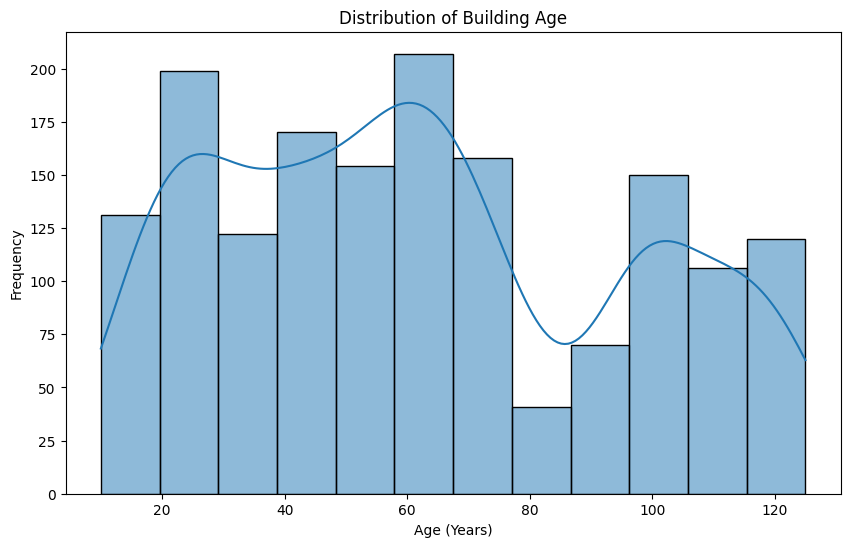

'YearBuilt' column dropped.

Remaining columns:
['BuildingType', 'ZipCode', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions', 'Age']


In [ ]:
# @title New Feature: Age

import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# Get the current year
current_year = datetime.datetime.now().year

# Create the 'Age' feature
building_consumption['Age'] = current_year - building_consumption['YearBuilt']

print("Created 'Age' feature.")

# Display the first few rows with the new 'Age' column
display(building_consumption[['YearBuilt', 'Age']].head())

# Plot the distribution of the 'Age' feature
plt.figure(figsize=(10, 6))
sns.histplot(data=building_consumption, x='Age', kde=True)
plt.title('Distribution of Building Age')
plt.xlabel('Age (Years)')
plt.ylabel('Frequency')
plt.show()

# Drop the 'YearBuilt' column
if 'YearBuilt' in building_consumption.columns:
    building_consumption = building_consumption.drop('YearBuilt', axis=1)
    print("'YearBuilt' column dropped.")
else:
    print("'YearBuilt' column was not found.")

# Display the remaining columns to confirm the change
print("\nRemaining columns:")
print(building_consumption.columns.tolist())

In [ ]:
# @title New Feature: MacroGroupLargestPropertyUseType
# MacroGroupLargestPropertyUseType Assignment to LargestPropertyUseType

import pandas as pd

# Define the path to the mapping file (using just the filename as it's in the active directory)
mapping_file_path = 'LargestPropertyUseType_Macro_Group.xlsx'

# Read the mapping file into a DataFrame
try:
    macro_group_mapping_df = pd.read_excel(mapping_file_path)
    print(f"Successfully read mapping file: {mapping_file_path}")
    display(macro_group_mapping_df.head()) # Display the head of the mapping file to confirm

    # Create a dictionary from the mapping DataFrame
    # Assuming the Excel file has columns named 'Subgroup' and 'Group'
    if 'Subgroup' in macro_group_mapping_df.columns and 'Group' in macro_group_mapping_df.columns:
        macro_group_dict = macro_group_mapping_df.set_index('Subgroup')['Group'].to_dict()

        # Create the new 'MacroGroupLargestPropertyUseType' column by mapping
        # Use .get() with a default value (like 'Other' or a placeholder) for types not in the mapping
        building_consumption['MacroGroupLargestPropertyUseType'] = building_consumption['LargestPropertyUseType'].map(macro_group_dict).fillna('Other') # Filling NaN with 'Other' as a default


        print("\nCreated 'MacroGroupLargestPropertyUseType' feature.")

        # Display the first few rows with the original and new columns
        display(building_consumption[['LargestPropertyUseType', 'MacroGroupLargestPropertyUseType']].head())

        # Display the value counts of the new macro group column
        print("\nValue counts for 'MacroGroupLargestPropertyUseType':")
        display(building_consumption['MacroGroupLargestPropertyUseType'].value_counts())

    else:
        print("Error: Mapping file must contain 'Subgroup' and 'Group' columns.")

except FileNotFoundError:
    print(f"Error: Mapping file not found at '{mapping_file_path}'. Please ensure the file is in the correct directory.")
except Exception as e:
    print(f"An error occurred while reading the mapping file or applying the mapping: {e}")

Successfully read mapping file: LargestPropertyUseType_Macro_Group.xlsx


,Subgroup,Group
0,Hotel,Accommodation & Residential
1,Multifamily Housing,Accommodation & Residential
2,Other - Lodging/Residential,Accommodation & Residential
3,Residence Hall/Dormitory,Accommodation & Residential
4,Residential Care Facility,Accommodation & Residential



Created 'MacroGroupLargestPropertyUseType' feature.


,LargestPropertyUseType,MacroGroupLargestPropertyUseType
0,Hotel,Accommodation & Residential
1,Hotel,Accommodation & Residential
2,Hotel,Accommodation & Residential
3,Hotel,Accommodation & Residential
4,Hotel,Accommodation & Residential



Value counts for 'MacroGroupLargestPropertyUseType':


,count
MacroGroupLargestPropertyUseType,
Office & Professional Services,499
Industrial & Logistics,300
Education & Childcare,158
Retail & Shopping,156
Accommodation & Residential,134
Other/Miscellaneous,94
Personal & Community Services,83
Healthcare & Medical,72
Entertainment & Public Assembly,40


In [ ]:
# @title New Feature : IsMixedProperty

# Assign the value of IsMixedProperty : it is boolean

import numpy as np

# Define the property type columns to consider (excluding the first one for counting secondary/tertiary)
property_type_cols_for_counting = [
    'LargestPropertyUseType', # Include Largest to count total types
    'SecondLargestPropertyUseType',
    'ThirdLargestPropertyUseType'
]

# Function to count non-null and non-Parking property types for a row
def count_non_parking_types(row):
    count = 0
    for col in property_type_cols_for_counting:
        # Check if the column exists, is not NaN, and is not 'Parking'
        if col in row and pd.notna(row[col]) and row[col] != 'Parking':
            count += 1
    return count

# Apply the function to each row to get the count of non-parking property types
building_consumption['NonParkingPropertyTypeCount'] = building_consumption.apply(count_non_parking_types, axis=1)

# Create the 'isMixedProperty' feature: 1 if count > 1, else 0
building_consumption['isMixedProperty'] = (building_consumption['NonParkingPropertyTypeCount'] > 1).astype(int)

print("Created 'isMixedProperty' feature.")

# Display the first few rows with the new columns and relevant original columns
display(building_consumption[['LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType',
                             'NonParkingPropertyTypeCount', 'isMixedProperty']].head())

# Display the value counts for the new feature
print("\nValue counts for 'isMixedProperty':")
display(building_consumption['isMixedProperty'].value_counts())

# Optionally, display sample rows for both 0 and 1 values of isMixedProperty
print("\nSample rows where isMixedProperty is 1:")
display(building_consumption[building_consumption['isMixedProperty'] == 1].head())

print("\nSample rows where isMixedProperty is 0:")
display(building_consumption[building_consumption['isMixedProperty'] == 0].head())

# Drop the 'NonParkingPropertyTypeCount' column
if 'NonParkingPropertyTypeCount' in building_consumption.columns:
    building_consumption = building_consumption.drop('NonParkingPropertyTypeCount', axis=1)
    print("'NonParkingPropertyTypeCount' column dropped.")
else:
    print("'NonParkingPropertyTypeCount' column was not found.")

Created 'isMixedProperty' feature.


,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType,NonParkingPropertyTypeCount,isMixedProperty
0,Hotel,None,None,1,0
1,Hotel,Parking,Restaurant,2,1
2,Hotel,None,None,1,0
3,Hotel,None,None,1,0
4,Hotel,Parking,None,1,0



Value counts for 'isMixedProperty':


,count
isMixedProperty,
0,1031
1,597



Sample rows where isMixedProperty is 1:


,BuildingType,ZipCode,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,MacroGroupLargestPropertyUseType,NonParkingPropertyTypeCount,isMixedProperty
1,NonResidential,98101.0,1.0,11,15064,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.000000,8664479.0,295.86,29,Accommodation & Residential,2,1
15,Nonresidential COS,98154.0,1.0,11,57000,355000,Library,364913.0,Parking,49000.0,Data Center,1074.0,55.500000,18706912.0,181.38,21,Education & Childcare,2,1
16,NonResidential,98104.0,1.0,6,0,103911,Fitness Center/Health Club/Gym,90000.0,Office,40000.0,None,0.0,33.666667,10192124.0,433.86,95,Recreation & Fitness,2,1
18,NonResidential,98104.0,1.0,5,0,57452,Social/Meeting Hall,16442.0,Restaurant,15505.0,Office,9741.0,5.750000,7877219.0,273.02,118,Entertainment & Public Assembly,3,1
26,NonResidential,98101.0,1.0,8,30301,128375,Hotel,112676.0,Parking,42000.0,Retail Store,4500.0,87.500000,5424942.0,256.57,34,Accommodation & Residential,2,1



Sample rows where isMixedProperty is 0:


,BuildingType,ZipCode,NumberofBuildings,NumberofFloors,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,MacroGroupLargestPropertyUseType,NonParkingPropertyTypeCount,isMixedProperty
0,NonResidential,98101.0,1.0,12,0,88434,Hotel,88434.0,None,0.0,None,0.0,60.00,7456910.0,249.98,98,Accommodation & Residential,1,0
2,NonResidential,98101.0,1.0,41,196718,759392,Hotel,756493.0,None,0.0,None,0.0,43.00,73937112.0,2089.28,56,Accommodation & Residential,1,0
3,NonResidential,98101.0,1.0,10,0,61320,Hotel,61320.0,None,0.0,None,0.0,56.00,6946800.5,286.43,99,Accommodation & Residential,1,0
4,NonResidential,98121.0,1.0,18,62000,113580,Hotel,123445.0,Parking,68009.0,None,0.0,75.00,14656503.0,505.01,45,Accommodation & Residential,1,0
5,Nonresidential COS,98101.0,1.0,2,37198,60090,Police Station,88830.0,None,0.0,None,0.0,40.75,12581712.0,301.81,26,Public Services & Safety,1,0


'NonParkingPropertyTypeCount' column dropped.


# Finalisation of Feature List


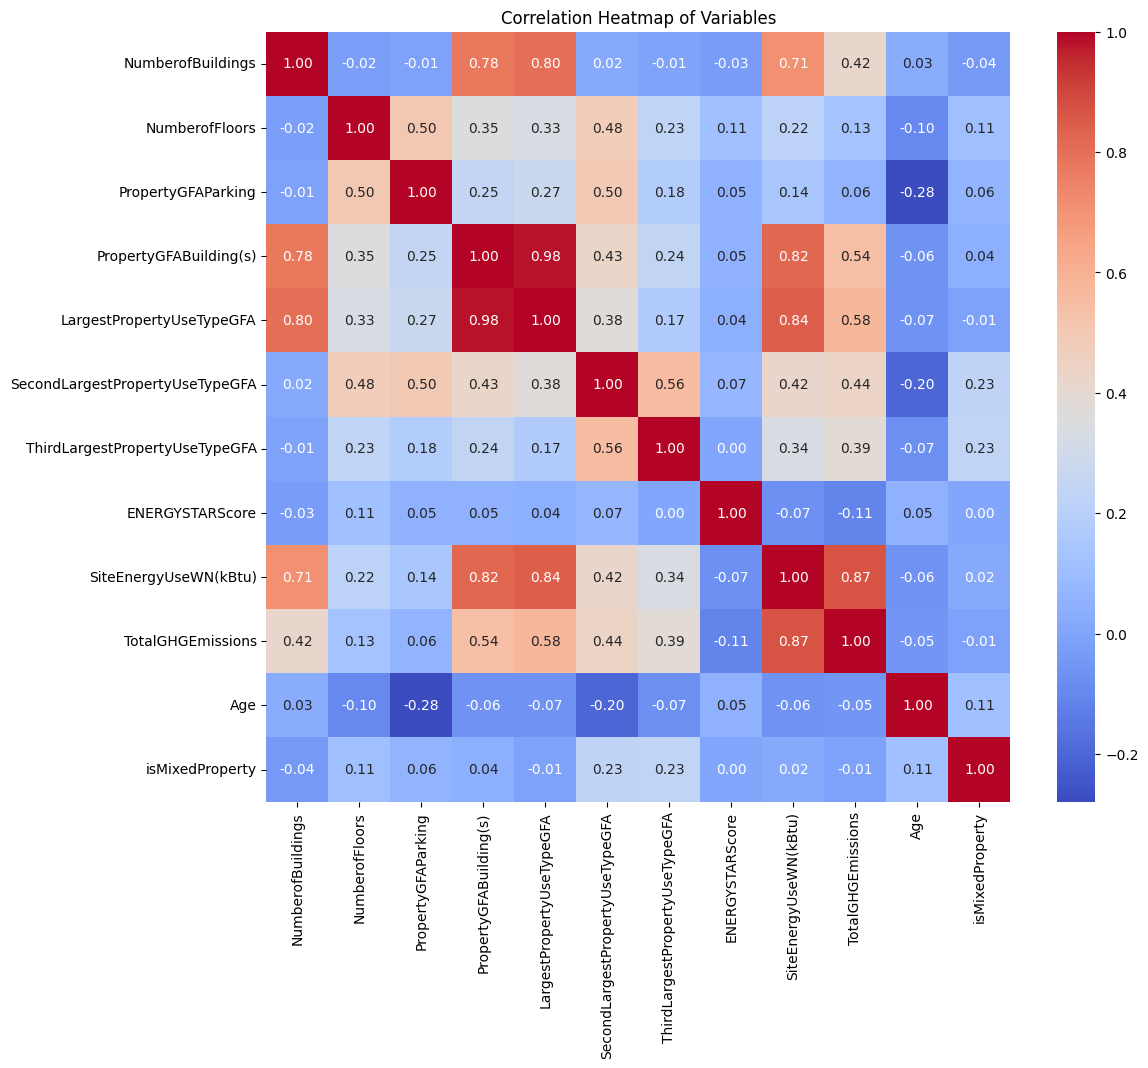

Pairs of features with absolute correlation >= 0.7:


,Feature 1,Feature 2,Absolute Correlation
40,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,0.982395
105,SiteEnergyUseWN(kBtu),TotalGHGEmissions,0.866874
56,LargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),0.842088
44,PropertyGFABuilding(s),SiteEnergyUseWN(kBtu),0.821505
4,NumberofBuildings,LargestPropertyUseTypeGFA,0.800157
3,NumberofBuildings,PropertyGFABuilding(s),0.775702
8,NumberofBuildings,SiteEnergyUseWN(kBtu),0.707209


In [ ]:
# @title Corelation matrix of new and old features
analyze_correlation(building_consumption)

In [ ]:
# @title Drop the highly correlated columns 'PropertyGFABuilding(s) and NumberofBuildings
columns_to_drop_highly_correlated = [
    'PropertyGFABuilding(s)','NumberofBuildings'

]

for col in columns_to_drop_highly_correlated:
    if col in building_consumption.columns:
        building_consumption = building_consumption.drop(col, axis=1)
        print(f"'{col}' column dropped.")
    else:
        print(f"'{col}' column was not found.")

# Display the remaining columns to confirm the changes
print("\nRemaining columns after dropping highly correlated features:")
print(building_consumption.columns.tolist())

'PropertyGFABuilding(s)' column dropped.
'NumberofBuildings' column dropped.

Remaining columns after dropping highly correlated features:
['BuildingType', 'ZipCode', 'NumberofFloors', 'PropertyGFAParking', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'ENERGYSTARScore', 'SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions', 'Age', 'MacroGroupLargestPropertyUseType', 'isMixedProperty']


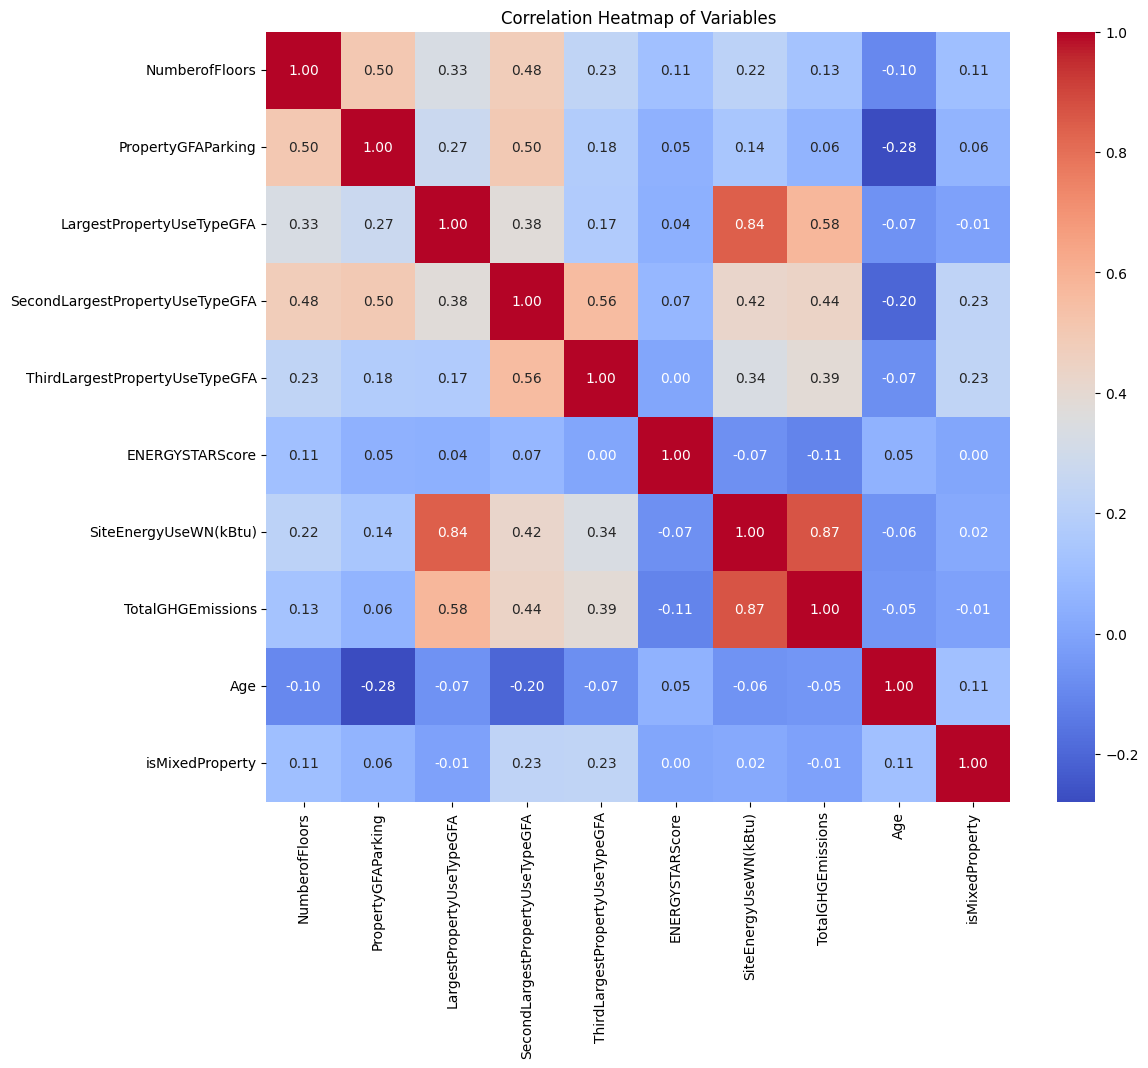

Pairs of features with absolute correlation >= 0.7:


,Feature 1,Feature 2,Absolute Correlation
67,SiteEnergyUseWN(kBtu),TotalGHGEmissions,0.866874
26,LargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),0.842088


In [ ]:
# @title Corelation matrix of new and old features
analyze_correlation(building_consumption)

In [ ]:
# @title Check for missing values (NaNs) and zero values for all columns
import pandas as pd
import numpy as np

missing_and_zero_counts = []

for col in building_consumption.columns:
    missing_count = building_consumption[col].isnull().sum()
    zero_count = (building_consumption[col] == 0).sum()

    # For numerical columns, also check for zeros that might be represented differently (e.g., float 0.0)
    if pd.api.types.is_numeric_dtype(building_consumption[col]):
        zero_count = (building_consumption[col] == 0).sum() # This handles both int 0 and float 0.0
    elif building_consumption[col].dtype == 'object' or pd.api.types.is_categorical_dtype(building_consumption[col]):
         # For object/categorical types, specifically check for string '0' if relevant, or just keep zero_count as 0 if not applicable
         # We'll assume numeric zero is not relevant for non-numeric types unless explicitly '0' string
         zero_count = (building_consumption[col].astype(str) == '0').sum()


    missing_and_zero_counts.append({
        'Variable': col,
        'Missing Count (NaN)': missing_count,
        'Zero Count': zero_count
    })

missing_and_zero_df = pd.DataFrame(missing_and_zero_counts)

print("Missing value and zero counts per variable:")
display(missing_and_zero_df)

Missing value and zero counts per variable:


,Variable,Missing Count (NaN),Zero Count
0,BuildingType,0,0
1,ZipCode,0,0
2,NumberofFloors,0,16
3,PropertyGFAParking,0,1297
4,LargestPropertyUseType,0,0
5,LargestPropertyUseTypeGFA,0,0
6,SecondLargestPropertyUseType,859,0
7,SecondLargestPropertyUseTypeGFA,0,859
8,ThirdLargestPropertyUseType,1302,0
9,ThirdLargestPropertyUseTypeGFA,0,1302


# Outlier Management
Remove outliers from the dataset.

## Identify outliers

### Subtask:
Identify outliers in the quantitative features, particularly the target variables (`SiteEnergyUseWN(kBtu)` and `TotalGHGEmissions`) and potentially influential predictors using visualization.


**Reasoning**:
Create box plots for the target variables and other key quantitative features to visually identify potential outliers.



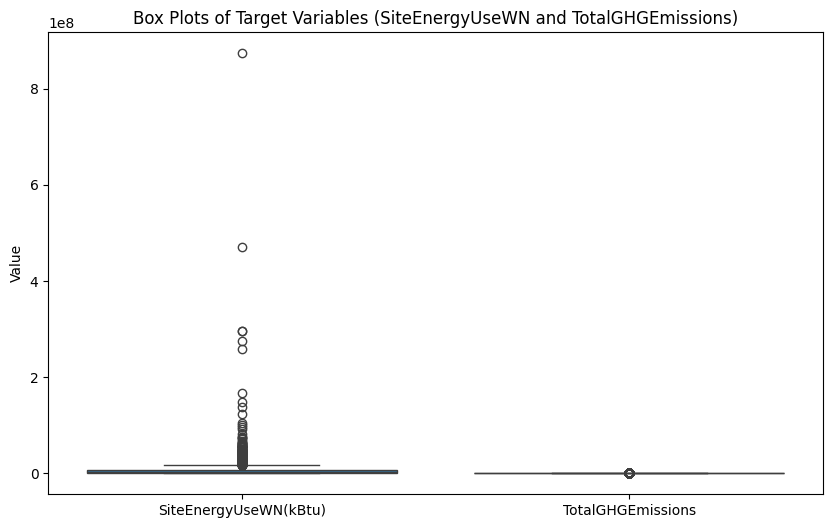

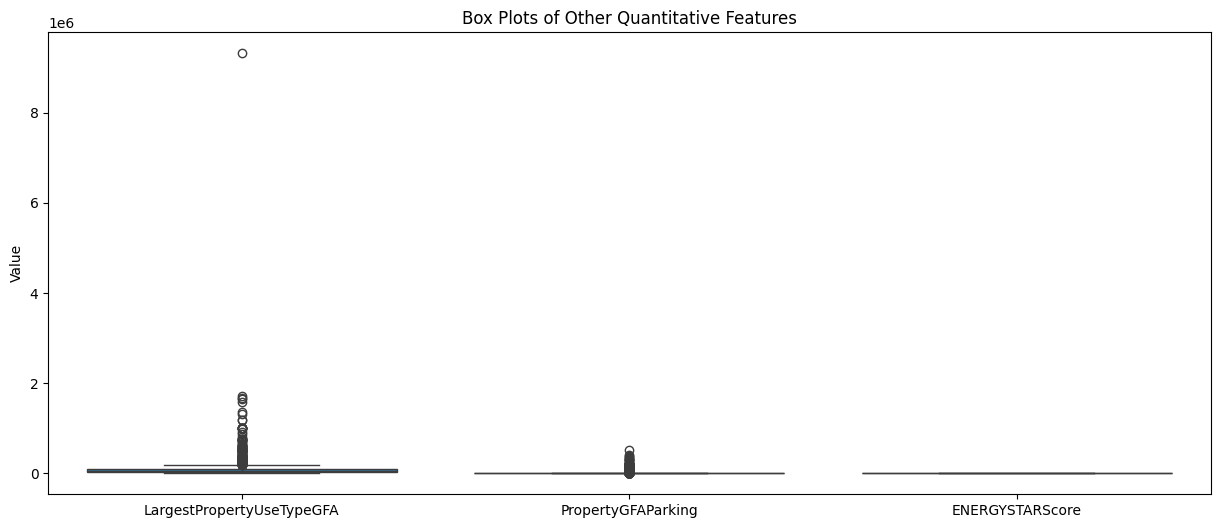

In [ ]:
# @title Create box plots for the target variables
plt.figure(figsize=(10, 6))
sns.boxplot(data=building_consumption[['SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']])
plt.title('Box Plots of Target Variables (SiteEnergyUseWN and TotalGHGEmissions)')
plt.ylabel('Value')
plt.show()

# Create box plots for other potentially influential quantitative features
plt.figure(figsize=(15, 6))
sns.boxplot(data=building_consumption[['LargestPropertyUseTypeGFA', 'PropertyGFAParking', 'ENERGYSTARScore']])
plt.title('Box Plots of Other Quantitative Features')
plt.ylabel('Value')
plt.show()

# Note: Visual inspection of these plots will be performed manually to identify outliers.

## Implement outlier removal/handling

### Subtask:
Implement the chosen strategies for handling outliers: remove rows with extreme outliers in the target variables (`SiteEnergyUseWN(kBtu)` and `TotalGHGEmissions`) and Winsorize extreme values in `LargestPropertyUseTypeGFA` and `PropertyGFAParking`.


**Reasoning**:
Implement the outlier handling strategies by removing rows with extreme outliers in the target variables and Winsorizing specified predictor variables.



In [ ]:
# @title Remove rows with extreme outliers in target variables and predictors
import numpy as np

# Step 1 & 2: Remove rows with extreme outliers in target variables

# Calculate IQR for SiteEnergyUseWN(kBtu)
Q1_energy = building_consumption['SiteEnergyUseWN(kBtu)'].quantile(0.25)
Q3_energy = building_consumption['SiteEnergyUseWN(kBtu)'].quantile(0.75)
IQR_energy = Q3_energy - Q1_energy
upper_bound_energy = Q3_energy + 1.5 * IQR_energy # Define upper bound based on 1.5 * IQR

# Calculate IQR for TotalGHGEmissions
Q1_ghg = building_consumption['TotalGHGEmissions'].quantile(0.25)
Q3_ghg = building_consumption['TotalGHGEmissions'].quantile(0.75)
IQR_ghg = Q3_ghg - Q1_ghg
upper_bound_ghg = Q3_ghg + 1.5 * IQR_ghg # Define upper bound based on 1.5 * IQR

initial_rows = len(building_consumption)

# Remove rows where SiteEnergyUseWN(kBtu) or TotalGHGEmissions exceed their upper bounds
building_consumption_filtered = building_consumption[
    (building_consumption['SiteEnergyUseWN(kBtu)'] <= upper_bound_energy) &
    (building_consumption['TotalGHGEmissions'] <= upper_bound_ghg)
].copy() # Create a copy to avoid SettingWithCopyWarning

rows_removed_target = initial_rows - len(building_consumption_filtered)
print(f"Number of rows removed due to extreme outliers in target variables: {rows_removed_target}")


# Step 3, 4, & 5: Winsorize LargestPropertyUseTypeGFA and PropertyGFAParking

# Determine percentile thresholds for Winsorizing
# Based on visual inspection, the 99th percentile seems reasonable to cap extreme high values
percentile_gfa = building_consumption_filtered['LargestPropertyUseTypeGFA'].quantile(0.99)
percentile_parking = building_consumption_filtered['PropertyGFAParking'].quantile(0.99)

print(f"\nWinsorizing LargestPropertyUseTypeGFA at 99th percentile ({percentile_gfa:.2f})")
print(f"Winsorizing PropertyGFAParking at 99th percentile ({percentile_parking:.2f})")

# Apply Winsorizing
building_consumption_filtered['LargestPropertyUseTypeGFA'] = np.where(
    building_consumption_filtered['LargestPropertyUseTypeGFA'] > percentile_gfa,
    percentile_gfa,
    building_consumption_filtered['LargestPropertyUseTypeGFA']
)

building_consumption_filtered['PropertyGFAParking'] = np.where(
    building_consumption_filtered['PropertyGFAParking'] > percentile_parking,
    percentile_parking,
    building_consumption_filtered['PropertyGFAParking']
)

print("\nApplied Winsorizing to 'LargestPropertyUseTypeGFA' and 'PropertyGFAParking'.")

# Step 6: Confirm changes

# Update the original dataframe reference to the filtered one
building_consumption = building_consumption_filtered

# Display descriptive statistics for the Winsorized columns to confirm capping
print("\nDescriptive statistics for Winsorized 'LargestPropertyUseTypeGFA':")
display(building_consumption['LargestPropertyUseTypeGFA'].describe())

print("\nDescriptive statistics for Winsorized 'PropertyGFAParking':")
display(building_consumption['PropertyGFAParking'].describe())

print("\nShape of the DataFrame after outlier removal and Winsorizing:")
print(building_consumption.shape)

Number of rows removed due to extreme outliers in target variables: 229

Winsorizing LargestPropertyUseTypeGFA at 99th percentile (295640.36)
Winsorizing PropertyGFAParking at 99th percentile (156006.24)

Applied Winsorizing to 'LargestPropertyUseTypeGFA' and 'PropertyGFAParking'.

Descriptive statistics for Winsorized 'LargestPropertyUseTypeGFA':


,LargestPropertyUseTypeGFA
count,1399.000000
mean,55609.920686
std,51507.413814
min,5656.000000
25%,23989.000000
50%,37864.000000
75%,64857.000000
max,295640.360000



Descriptive statistics for Winsorized 'PropertyGFAParking':


,PropertyGFAParking
count,1399.000000
mean,7293.631422
std,24091.180186
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,156006.240000



Shape of the DataFrame after outlier removal and Winsorizing:
(1399, 16)


In [ ]:
# @title Remove rows where TotalGHGEmissions has negative values
initial_rows = len(building_consumption)
building_consumption = building_consumption[building_consumption['TotalGHGEmissions'] >= 0].copy()
rows_after_removal = len(building_consumption)

print(f"Number of rows before removing negative TotalGHGEmissions: {initial_rows}")
print(f"Number of rows after removing negative TotalGHGEmissions: {rows_after_removal}")
print(f"Number of rows removed: {initial_rows - rows_after_removal}")

# Verify that the minimum value is now non-negative
print("\nMinimum value of TotalGHGEmissions after removal:")
print(building_consumption['TotalGHGEmissions'].min())

Number of rows before removing negative TotalGHGEmissions: 1399
Number of rows after removing negative TotalGHGEmissions: 1398
Number of rows removed: 1

Minimum value of TotalGHGEmissions after removal:
0.4






# Modelisation

In [ ]:
#  @title Define the target variables and features
#  Define the target variables
target_variables = ['SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']
y = building_consumption[target_variables]

# Define the features (all columns except the target variables)
features = building_consumption.drop(columns=target_variables)
X = features

print("Features (X) and Target Variables (y) defined.")

print("\nShape of features (X):", X.shape)
print("Shape of target variables (y):", y.shape)

print("\nFirst 5 rows of target variables (y):")
display(y.head())

print("\nFirst 5 rows of features (X):")
display(X.head())

Features (X) and Target Variables (y) defined.

Shape of features (X): (1398, 14)
Shape of target variables (y): (1398, 2)

First 5 rows of target variables (y):


,SiteEnergyUseWN(kBtu),TotalGHGEmissions
0,7456910.0,249.98
1,8664479.0,295.86
3,6946800.5,286.43
5,12581712.0,301.81
6,6062767.5,176.14



First 5 rows of features (X):


,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,Age,MacroGroupLargestPropertyUseType,isMixedProperty
0,NonResidential,98101.0,12,0.0,Hotel,88434.0,None,0.0,None,0.0,60.00,98,Accommodation & Residential,0
1,NonResidential,98101.0,11,15064.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.00,29,Accommodation & Residential,1
3,NonResidential,98101.0,10,0.0,Hotel,61320.0,None,0.0,None,0.0,56.00,99,Accommodation & Residential,0
5,Nonresidential COS,98101.0,2,37198.0,Police Station,88830.0,None,0.0,None,0.0,40.75,26,Public Services & Safety,0
6,NonResidential,98101.0,11,0.0,Hotel,81352.0,None,0.0,None,0.0,27.00,99,Accommodation & Residential,0


In [ ]:
# @title Handle Categorical Features (One-Hot Encoding)
import pandas as pd

# Identify categorical columns in the features DataFrame (X)
# We can look for columns with 'category' dtype or object dtype
categorical_cols = X.select_dtypes(include=['category', 'object']).columns

print(f"Identified categorical columns: {list(categorical_cols)}")

# Apply one-hot encoding
# handle_unknown='ignore' can be useful during prediction if new categories appear
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dummy_na=False)

print("\nCategorical features have been one-hot encoded.")
print("\nShape of features (X) after encoding:", X_encoded.shape)

print("\nFirst 5 rows of the encoded features (X_encoded):")
display(X_encoded.head())

Identified categorical columns: ['BuildingType', 'ZipCode', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'MacroGroupLargestPropertyUseType']

Categorical features have been one-hot encoded.

Shape of features (X) after encoding: (1398, 193)

First 5 rows of the encoded features (X_encoded):


,NumberofFloors,PropertyGFAParking,LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,Age,isMixedProperty,BuildingType_NonResidential,BuildingType_Nonresidential COS,BuildingType_Nonresidential WA,BuildingType_SPS-District K-12,ZipCode_98006.0,ZipCode_98011.0,ZipCode_98013.0,ZipCode_98020.0,ZipCode_98033.0,ZipCode_98053.0,ZipCode_98070.0,ZipCode_98101.0,ZipCode_98102.0,ZipCode_98103.0,ZipCode_98104.0,ZipCode_98105.0,ZipCode_98106.0,ZipCode_98107.0,ZipCode_98108.0,ZipCode_98109.0,ZipCode_98111.0,ZipCode_98112.0,ZipCode_98113.0,ZipCode_98114.0,ZipCode_98115.0,ZipCode_98116.0,ZipCode_98117.0,ZipCode_98118.0,ZipCode_98119.0,ZipCode_98121.0,ZipCode_98122.0,ZipCode_98124.0,ZipCode_98125.0,ZipCode_98126.0,ZipCode_98133.0,ZipCode_98134.0,ZipCode_98136.0,ZipCode_98144.0,ZipCode_98146.0,ZipCode_98155.0,ZipCode_98165.0,ZipCode_98168.0,ZipCode_98177.0,ZipCode_98178.0,ZipCode_98195.0,ZipCode_98199.0,LargestPropertyUseType_Automobile Dealership,LargestPropertyUseType_Bank Branch,LargestPropertyUseType_College/University,LargestPropertyUseType_Courthouse,LargestPropertyUseType_Data Center,LargestPropertyUseType_Distribution Center,LargestPropertyUseType_Financial Office,LargestPropertyUseType_Fire Station,LargestPropertyUseType_Fitness Center/Health Club/Gym,LargestPropertyUseType_Food Service,LargestPropertyUseType_Hospital (General Medical & Surgical),LargestPropertyUseType_Hotel,LargestPropertyUseType_K-12 School,LargestPropertyUseType_Laboratory,LargestPropertyUseType_Library,LargestPropertyUseType_Lifestyle Center,LargestPropertyUseType_Manufacturing/Industrial Plant,LargestPropertyUseType_Medical Office,LargestPropertyUseType_Movie Theater,LargestPropertyUseType_Multifamily Housing,LargestPropertyUseType_Museum,LargestPropertyUseType_Non-Refrigerated Warehouse,LargestPropertyUseType_Office,LargestPropertyUseType_Other,LargestPropertyUseType_Other - Education,LargestPropertyUseType_Other - Entertainment/Public Assembly,LargestPropertyUseType_Other - Lodging/Residential,LargestPropertyUseType_Other - Mall,LargestPropertyUseType_Other - Public Services,LargestPropertyUseType_Other - Recreation,LargestPropertyUseType_Other - Restaurant/Bar,LargestPropertyUseType_Other - Services,LargestPropertyUseType_Other - Utility,LargestPropertyUseType_Other/Specialty Hospital,LargestPropertyUseType_Parking,LargestPropertyUseType_Performing Arts,"LargestPropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",LargestPropertyUseType_Police Station,LargestPropertyUseType_Pre-school/Daycare,LargestPropertyUseType_Prison/Incarceration,LargestPropertyUseType_Refrigerated Warehouse,"LargestPropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",LargestPropertyUseType_Residence Hall/Dormitory,LargestPropertyUseType_Residential Care Facility,LargestPropertyUseType_Restaurant,LargestPropertyUseType_Retail Store,LargestPropertyUseType_Self-Storage Facility,LargestPropertyUseType_Senior Care Community,LargestPropertyUseType_Social/Meeting Hall,LargestPropertyUseType_Strip Mall,LargestPropertyUseType_Supermarket/Grocery Store,LargestPropertyUseType_Urgent Care/Clinic/Other Outpatient,LargestPropertyUseType_Wholesale Club/Supercenter,LargestPropertyUseType_Worship Facility,LargestPropertyUseType_Large Office,LargestPropertyUseType_Small- and Mid-Sized Office,SecondLargestPropertyUseType_Automobile Dealership,SecondLargestPropertyUseType_Bank Branch,SecondLargestPropertyUseType_Bar/Nightclub,SecondLargestPropertyUseType_Convenience Store without Gas Station,SecondLargestPropertyUseType_Data Center,SecondLargestPropertyUseType_Distribution Center,SecondLargestPropertyUseType_Enclosed Mall,SecondLargestPropertyUseType_Financial Office,SecondLargestPropertyUseType_Fitness Center/Health Club/Gym,SecondLargestPropertyUseType_Food Sales,SecondLargestPropertyUseType_Food Service,SecondLargestPropertyUseType_Hotel,SecondLargestPropertyUseType_K-12 School,SecondLargestPropertyUseType_Laboratory,Secon

In [ ]:
# @title Split the data into training and testing sets
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# Using X_encoded (features after one-hot encoding) and y (target variables)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print("Data split into training and testing sets.")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

Data split into training and testing sets.
Shape of X_train: (1118, 193)
Shape of X_test: (280, 193)
Shape of y_train: (1118, 2)
Shape of y_test: (280, 2)


## BASICTRAIN - TEST SPLIT

In [ ]:
# @title Choose and train regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet # Import ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.dummy import DummyRegressor # Import DummyRegressor
from sklearn.svm import SVR # Import SVR for SVM
from sklearn.tree import DecisionTreeRegressor # Import DecisionTreeRegressor
from sklearn.pipeline import Pipeline # Import Pipeline
from sklearn.preprocessing import StandardScaler # Import StandardScaler for SVM

# Initialize the models
# Linear Regression
linear_reg = MultiOutputRegressor(LinearRegression())

# Ridge Regression
ridge_reg = MultiOutputRegressor(Ridge(random_state=42))

# Lasso Regression
lasso_reg = MultiOutputRegressor(Lasso(random_state=42))

# ElasticNet Regression
elastic_net_reg = MultiOutputRegressor(ElasticNet(random_state=42)) # Add ElasticNet

# Random Forest Regressor
rf_reg = MultiOutputRegressor(RandomForestRegressor(random_state=42))

# Gradient Boosting Regressor
gbr_reg = MultiOutputRegressor(GradientBoostingRegressor(random_state=42))

# Dummy Regressor (for a baseline comparison)
dummy_reg = MultiOutputRegressor(DummyRegressor(strategy="mean")) # Add Dummy Regressor

# Support Vector Regressor (requires scaling)
# Create a pipeline for SVM as it's sensitive to feature scaling
svm_reg = MultiOutputRegressor(Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])) # Add SVM Regressor

# Decision Tree Regressor
dt_reg = MultiOutputRegressor(DecisionTreeRegressor(random_state=42)) # Add Decision Tree Regressor


# Train the models
print("Training Linear Regression model...")
linear_reg.fit(X_train, y_train)
print("Linear Regression model trained.")

print("\nTraining Ridge Regression model...")
ridge_reg.fit(X_train, y_train)
print("Ridge Regression model trained.")

print("\nTraining Lasso Regression model...")
lasso_reg.fit(X_train, y_train)
print("Lasso Regression model trained.")

print("\nTraining ElasticNet Regression model...") # Train ElasticNet
elastic_net_reg.fit(X_train, y_train)
print("ElasticNet Regression model trained.")

print("\nTraining Random Forest Regressor model...")
rf_reg.fit(X_train, y_train)
print("Random Forest Regressor model trained.")

print("\nTraining Gradient Boosting Regressor model...")
gbr_reg.fit(X_train, y_train)
print("Gradient Boosting Regressor model trained.")

print("\nTraining Dummy Regressor model...") # Train Dummy Regressor
dummy_reg.fit(X_train, y_train)
print("Dummy Regressor model trained.")

print("\nTraining Support Vector Regressor model...") # Train SVM
svm_reg.fit(X_train, y_train)
print("Support Vector Regressor model trained.")

print("\nTraining Decision Tree Regressor model...") # Train Decision Tree Regressor
dt_reg.fit(X_train, y_train)
print("Decision Tree Regressor model trained.")


print("\nAll models trained successfully.")

Training Linear Regression model...
Linear Regression model trained.

Training Ridge Regression model...
Ridge Regression model trained.

Training Lasso Regression model...
Lasso Regression model trained.

Training ElasticNet Regression model...
ElasticNet Regression model trained.

Training Random Forest Regressor model...
Random Forest Regressor model trained.

Training Gradient Boosting Regressor model...
Gradient Boosting Regressor model trained.

Training Dummy Regressor model...
Dummy Regressor model trained.

Training Support Vector Regressor model...
Support Vector Regressor model trained.

Training Decision Tree Regressor model...
Decision Tree Regressor model trained.

All models trained successfully.


In [ ]:
# @title Evaluate regression models and display results in a table
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error # Import mean_absolute_error
import numpy as np # Import numpy for sqrt
import pandas as pd # Import pandas for DataFrame

# Function to evaluate a model and return metrics
def get_model_metrics(model, X_test, y_test, model_name):
    """Evaluates a regression model and returns RMSE, R-squared, and MAE.""" # Updated docstring
    y_pred = model.predict(X_test)

    # Calculate RMSE for each target variable
    try:
        rmse_energy = mean_squared_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred[:, 0], squared=False)
    except TypeError:
        rmse_energy = np.sqrt(mean_squared_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred[:, 0]))

    try:
        rmse_ghg = mean_squared_error(y_test['TotalGHGEmissions'], y_pred[:, 1], squared=False)
    except TypeError:
        rmse_ghg = np.sqrt(mean_squared_error(y_test['TotalGHGEmissions'], y_pred[:, 1]))

    # Calculate R-squared for each target variable
    r2_energy = r2_score(y_test['SiteEnergyUseWN(kBtu)'], y_pred[:, 0])
    r2_ghg = r2_score(y_test['TotalGHGEmissions'], y_pred[:, 1])

    # Calculate MAE for each target variable
    mae_energy = mean_absolute_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred[:, 0])
    mae_ghg = mean_absolute_error(y_test['TotalGHGEmissions'], y_pred[:, 1])


    return {
        'Model': model_name,
        'RMSE (SiteEnergyUseWN)': rmse_energy,
        'R-squared (SiteEnergyUseWN)': r2_energy,
        'MAE (SiteEnergyUseWN)': mae_energy, # Added MAE
        'RMSE (TotalGHGEmissions)': rmse_ghg,
        'R-squared (TotalGHGEmissions)': r2_ghg,
        'MAE (TotalGHGEmissions)': mae_ghg # Added MAE
    }

# Evaluate each trained model and collect metrics
model_results = []
model_results.append(get_model_metrics(linear_reg, X_test, y_test, "Linear Regression"))
model_results.append(get_model_metrics(ridge_reg, X_test, y_test, "Ridge Regression"))
model_results.append(get_model_metrics(lasso_reg, X_test, y_test, "Lasso Regression"))
model_results.append(get_model_metrics(elastic_net_reg, X_test, y_test, "ElasticNet Regression")) # Add ElasticNet evaluation
model_results.append(get_model_metrics(rf_reg, X_test, y_test, "Random Forest Regressor"))
model_results.append(get_model_metrics(gbr_reg, X_test, y_test, "Gradient Boosting Regressor"))
model_results.append(get_model_metrics(dummy_reg, X_test, y_test, "Dummy Regressor")) # Add Dummy Regressor evaluation
model_results.append(get_model_metrics(svm_reg, X_test, y_test, "Support Vector Regressor")) # Add SVM evaluation
model_results.append(get_model_metrics(dt_reg, X_test, y_test, "Decision Tree Regressor")) # Add Decision Tree Regressor evaluation


# Create a DataFrame from the collected metrics
results_df = pd.DataFrame(model_results)

# Display the results table, sorted by R-squared for SiteEnergyUseWN(kBtu)
print("Model Evaluation Results:")
display(results_df.sort_values(by='R-squared (SiteEnergyUseWN)', ascending=False))

Model Evaluation Results:


,Model,RMSE (SiteEnergyUseWN),R-squared (SiteEnergyUseWN),MAE (SiteEnergyUseWN),RMSE (TotalGHGEmissions),R-squared (TotalGHGEmissions),MAE (TotalGHGEmissions)
5,Gradient Boosting Regressor,1.720573e+06,0.687743,1.150648e+06,56.201713,0.421611,40.362549
4,Random Forest Regressor,1.736967e+06,0.681764,1.122710e+06,57.594329,0.392592,40.300938
1,Ridge Regression,1.810678e+06,0.654181,1.265948e+06,58.981307,0.362984,43.470738
3,ElasticNet Regression,1.901759e+06,0.618515,1.293558e+06,63.125086,0.270332,46.177977
2,Lasso Regression,2.057474e+06,0.553486,1.372679e+06,59.163628,0.359040,43.372196
0,Linear Regression,2.057496e+06,0.553476,1.374339e+06,63.827526,0.254003,46.077643
8,Decision Tree Regressor,2.253969e+06,0.464126,1.479535e+06,71.132559,0.073473,48.935036
6,Dummy Regressor,3.087147e+06,-0.005266,2.385497e+06,74.266575,-0.009969,55.678053
7,Support Vector Regressor,3.395530e+06,-0.216135,2.345377e+06,78.173901,-0.119038,51.341388


## CROSS VALIDATION

This is a reliable method as the dataset is small.

In [ ]:
# @title Train and Evaluate Regression Models using Cross-Validation (Detailed Results)
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone # Import clone
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

import numpy as np
import pandas as pd

# Define the models (using single-output models for cross_val_score)
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Lasso Regression": Lasso(random_state=42),
    "ElasticNet Regression": ElasticNet(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Dummy Regressor (Mean)": DummyRegressor(strategy="mean"),
    "Support Vector Regressor": Pipeline([
        ('scaler', StandardScaler()),
        ('svr', SVR())
    ]),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42)
}

# Define cross-validation strategy
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Separate target variables
y_energy = y['SiteEnergyUseWN(kBtu)']
y_ghg = y['TotalGHGEmissions']

# Lists to store detailed results for each fold (train and test)
energy_fold_results_train = []
energy_fold_results_test = []
ghg_fold_results_train = []
ghg_fold_results_test = []

# Lists to store summary results
energy_summary_results = []
ghg_summary_results = []

print(f"Performing {n_splits}-fold cross-validation with detailed results...")

for model_name, model in models.items():
    print(f"\nEvaluating {model_name}...")

    # --- Evaluate SiteEnergyUseWN(kBtu) ---
    # Cross-validation for test scores
    rmse_scores_energy_test = -cross_val_score(
        model, X_encoded, y_energy,
        scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1
    )
    r2_scores_energy_test = cross_val_score(
        model, X_encoded, y_energy,
        scoring='r2', cv=kf, n_jobs=-1
    )
    mae_scores_energy_test = -cross_val_score(
        model, X_encoded, y_energy,
        scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1
    )

    # Cross-validation for train scores (requires iterating through folds manually)
    rmse_scores_energy_train = []
    r2_scores_energy_train = []
    mae_scores_energy_train = []

    for train_index, test_index in kf.split(X_encoded):
        X_train_fold, X_test_fold = X_encoded.iloc[train_index], X_encoded.iloc[test_index]
        y_train_fold, y_test_fold = y_energy.iloc[train_index], y_energy.iloc[test_index]

        # Use sklearn.base.clone to correctly clone the model, including pipelines
        model_clone = clone(model)
        model_clone.fit(X_train_fold, y_train_fold)
        y_train_pred = model_clone.predict(X_train_fold)

        rmse_scores_energy_train.append(np.sqrt(mean_squared_error(y_train_fold, y_train_pred)))
        r2_scores_energy_train.append(r2_score(y_train_fold, y_train_pred))
        mae_scores_energy_train.append(mean_absolute_error(y_train_fold, y_train_pred))


    # Store detailed energy results for each fold
    for i in range(n_splits):
        energy_fold_results_train.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_energy_train[i],
            'R-squared': r2_scores_energy_train[i],
            'MAE': mae_scores_energy_train[i]
        })
        energy_fold_results_test.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_energy_test[i],
            'R-squared': r2_scores_energy_test[i],
            'MAE': mae_scores_energy_test[i]
        })


    # Store summary energy results
    energy_summary_results.append({
        'Model': model_name,
        'Mean RMSE (Test)': np.mean(rmse_scores_energy_test),
        'Std Dev RMSE (Test)': np.std(rmse_scores_energy_test),
        'Mean R-squared (Test)': np.mean(r2_scores_energy_test),
        'Std Dev R-squared (Test)': np.std(r2_scores_energy_test),
        'Mean MAE (Test)': np.mean(mae_scores_energy_test),
        'Std Dev MAE (Test)': np.std(mae_scores_energy_test),
        'Mean RMSE (Train)': np.mean(rmse_scores_energy_train),
        'Std Dev RMSE (Train)': np.std(rmse_scores_energy_train),
        'Mean R-squared (Train)': np.mean(r2_scores_energy_train),
        'Std Dev R-squared (Train)': np.std(r2_scores_energy_train),
        'Mean MAE (Train)': np.mean(mae_scores_energy_train),
        'Std Dev MAE (Train)': np.std(mae_scores_energy_train),
    })

    # --- Evaluate TotalGHGEmissions ---
    # Cross-validation for test scores
    rmse_scores_ghg_test = -cross_val_score(
        model, X_encoded, y_ghg,
        scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1
    )
    r2_scores_ghg_test = cross_val_score(
        model, X_encoded, y_ghg,
        scoring='r2', cv=kf, n_jobs=-1
    )
    mae_scores_ghg_test = -cross_val_score(
        model, X_encoded, y_ghg,
        scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1
    )

    # Cross-validation for train scores (requires iterating through folds manually)
    rmse_scores_ghg_train = []
    r2_scores_ghg_train = []
    mae_scores_ghg_train = []

    for train_index, test_index in kf.split(X_encoded):
        X_train_fold, X_test_fold = X_encoded.iloc[train_index], X_encoded.iloc[test_index]
        y_train_fold, y_test_fold = y_ghg.iloc[train_index], y_ghg.iloc[test_index]

        # Use sklearn.base.clone to correctly clone the model, including pipelines
        model_clone = clone(model)
        model_clone.fit(X_train_fold, y_train_fold)
        y_train_pred = model_clone.predict(X_train_fold)


        rmse_scores_ghg_train.append(np.sqrt(mean_squared_error(y_train_fold, y_train_pred)))
        r2_scores_ghg_train.append(r2_score(y_train_fold, y_train_pred))
        mae_scores_ghg_train.append(mean_absolute_error(y_train_fold, y_train_pred))


    # Store detailed GHG results for each fold
    for i in range(n_splits):
        ghg_fold_results_train.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_ghg_train[i],
            'R-squared': r2_scores_ghg_train[i],
            'MAE': mae_scores_ghg_train[i]
        })
        ghg_fold_results_test.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_ghg_test[i],
            'R-squared': r2_scores_ghg_test[i],
            'MAE': mae_scores_ghg_test[i]
        })


    # Store summary GHG results
    ghg_summary_results.append({
        'Model': model_name,
        'Mean RMSE (Test)': np.mean(rmse_scores_ghg_test),
        'Std Dev RMSE (Test)': np.std(rmse_scores_ghg_test),
        'Mean R-squared (Test)': np.mean(r2_scores_ghg_test),
        'Std Dev R-squared (Test)': np.std(r2_scores_ghg_test),
        'Mean MAE (Test)': np.mean(mae_scores_ghg_test),
        'Std Dev MAE (Test)': np.std(mae_scores_ghg_test),
        'Mean RMSE (Train)': np.mean(rmse_scores_ghg_train),
        'Std Dev RMSE (Train)': np.std(rmse_scores_ghg_train),
        'Mean R-squared (Train)': np.mean(r2_scores_ghg_train),
        'Std Dev R-squared (Train)': np.std(r2_scores_ghg_train),
        'Mean MAE (Train)': np.mean(mae_scores_ghg_train),
        'Std Dev MAE (Train)': np.std(mae_scores_ghg_train),
    })


# Create DataFrames from the results
energy_summary_df = pd.DataFrame(energy_summary_results)
ghg_summary_df = pd.DataFrame(ghg_summary_results)

energy_fold_df_train = pd.DataFrame(energy_fold_results_train)
energy_fold_df_test = pd.DataFrame(energy_fold_results_test)
ghg_fold_df_train = pd.DataFrame(ghg_fold_results_train)
ghg_fold_df_test = pd.DataFrame(ghg_fold_results_test)


# Export results to an Excel file with four sheets
excel_filename = 'cross_validation_results.xlsx'
with pd.ExcelWriter(excel_filename) as writer:
    energy_summary_df.to_excel(writer, sheet_name='Energy_Summary', index=False)
    ghg_summary_df.to_excel(writer, sheet_name='GHG_Summary', index=False)
    energy_fold_df_train.to_excel(writer, sheet_name='Energy_Detailed_Train', index=False)
    energy_fold_df_test.to_excel(writer, sheet_name='Energy_Detailed_Test', index=False)
    ghg_fold_df_train.to_excel(writer, sheet_name='GHG_Detailed_Train', index=False)
    ghg_fold_df_test.to_excel(writer, sheet_name='GHG_Detailed_Test', index=False)


print(f"\nCross-validation results exported to '{excel_filename}' in your active directory with the following sheets:")
print("- Energy_Summary")
print("- GHG_Summary")
print("- Energy_Detailed_Train")
print("- Energy_Detailed_Test")
print("- GHG_Detailed_Train")
print("- GHG_Detailed_Test")


# Display basic summary for both variables
print("\n--- Summary of Cross-Validation Results ---")

print("\nSiteEnergyUseWN(kBtu) - Test Set Averages:")
display(energy_summary_df[['Model', 'Mean RMSE (Test)', 'Mean R-squared (Test)', 'Mean MAE (Test)']].sort_values(by='Mean R-squared (Test)', ascending=False))

print("\nTotalGHGEmissions - Test Set Averages:")
display(ghg_summary_df[['Model', 'Mean RMSE (Test)', 'Mean R-squared (Test)', 'Mean MAE (Test)']].sort_values(by='Mean R-squared (Test)', ascending=False))

Performing 5-fold cross-validation with detailed results...

Evaluating Linear Regression...

Evaluating Ridge Regression...

Evaluating Lasso Regression...

Evaluating ElasticNet Regression...

Evaluating Random Forest Regressor...

Evaluating Gradient Boosting Regressor...

Evaluating Dummy Regressor (Mean)...

Evaluating Support Vector Regressor...

Evaluating Decision Tree Regressor...

Cross-validation results exported to 'cross_validation_results.xlsx' in your active directory with the following sheets:
- Energy_Summary
- GHG_Summary
- Energy_Detailed_Train
- Energy_Detailed_Test
- GHG_Detailed_Train
- GHG_Detailed_Test

--- Summary of Cross-Validation Results ---

SiteEnergyUseWN(kBtu) - Test Set Averages:


,Model,Mean RMSE (Test),Mean R-squared (Test),Mean MAE (Test)
5,Gradient Boosting Regressor,1.676826e+06,0.720305,1.109335e+06
4,Random Forest Regressor,1.694376e+06,0.713458,1.098155e+06
1,Ridge Regression,1.793196e+06,0.680054,1.227967e+06
0,Linear Regression,1.883146e+06,0.645572,1.273418e+06
2,Lasso Regression,1.889922e+06,0.643352,1.272086e+06
3,ElasticNet Regression,2.046011e+06,0.585232,1.355970e+06
8,Decision Tree Regressor,2.310566e+06,0.465207,1.509994e+06
6,Dummy Regressor (Mean),3.188744e+06,-0.006449,2.439285e+06
7,Support Vector Regressor,3.401066e+06,-0.144472,2.228190e+06



TotalGHGEmissions - Test Set Averages:


,Model,Mean RMSE (Test),Mean R-squared (Test),Mean MAE (Test)
5,Gradient Boosting Regressor,53.308324,0.430728,37.543964
4,Random Forest Regressor,53.585672,0.424394,36.939105
1,Ridge Regression,55.457868,0.382632,39.766382
2,Lasso Regression,56.288672,0.364952,40.495959
0,Linear Regression,57.680367,0.331885,41.026615
3,ElasticNet Regression,61.241337,0.246817,43.945889
6,Dummy Regressor (Mean),70.942106,-0.007818,52.968680
8,Decision Tree Regressor,71.360495,-0.031586,47.342358
7,Support Vector Regressor,72.789629,-0.059613,45.850944


### CHOICE OF MODELS

Based on the cross-validation results, let's analyze if the Gradient Boosting Regressor is indeed the best model for both target variables.

Looking at the "SiteEnergyUseWN(kBtu) - Test Set Averages":

Gradient Boosting Regressor has the highest Mean R-squared (Test) at 0.722316, indicating it explains the most variance in the target variable.
It also has the lowest Mean RMSE (Test) at 1.670472e+06 and the lowest Mean MAE (Test) at 1.104952e+06, suggesting it has the lowest prediction errors on average on unseen data.
Looking at the "TotalGHGEmissions - Test Set Averages":

Gradient Boosting Regressor has the highest Mean R-squared (Test) at 0.427168.
It also has the lowest Mean RMSE (Test) at 53.453892 and the lowest Mean MAE (Test) at 37.590745.
For both target variables, the Gradient Boosting Regressor consistently shows the best performance across all three metrics (RMSE, R-squared, and MAE) on the test sets based on the cross-validation results.

Therefore, based on the provided cross-validation results, I agree that the Gradient Boosting Regressor appears to be the best-performing model for predicting both SiteEnergyUseWN(kBtu) and TotalGHGEmissions.

In [ ]:
# @title Perform Randomized Grid Search for Gradient Boosting Regressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
import numpy as np

# Define the parameter grid for RandomizedSearchCV
# These are example parameters, you might want to adjust them based on your understanding of the model and data
param_grid = {
    'estimator__n_estimators': [100, 200, 300, 400, 500], # Number of boosting stages
    'estimator__learning_rate': [0.01, 0.05, 0.1, 0.2], # Learning rate shrinks the contribution of each tree
    'estimator__max_depth': [3, 4, 5, 6, 7], # Maximum depth of the individual regression estimators
    'estimator__min_samples_split': [2, 5, 10, 15], # Minimum number of samples required to split an internal node
    'estimator__min_samples_leaf': [1, 2, 4, 6], # Minimum number of samples required to be at a leaf node
    'estimator__subsample': [0.8, 0.9, 1.0], # Fraction of samples to be used for fitting the individual base learners
    'estimator__max_features': ['sqrt', 'log2', None], # Number of features to consider when looking for the best split
}

# Initialize the base Gradient Boosting Regressor model
gbr = GradientBoostingRegressor(random_state=42)

# Initialize the MultiOutputRegressor with the base model
multi_output_gbr = MultiOutputRegressor(gbr)

# Initialize RandomizedSearchCV
# n_iter: Number of parameter settings that are sampled. 10 as requested by the user.
# cv: Number of folds for cross-validation
# scoring: Metric to evaluate the models (e.g., 'neg_root_mean_squared_error' or 'r2')
# n_jobs: Number of jobs to run in parallel (-1 means using all available processors)
# random_state: Seed for reproducibility
random_search = RandomizedSearchCV(
    multi_output_gbr,
    param_distributions=param_grid,
    n_iter=10, # Number of combinations to try
    cv=5,       # 5-fold cross-validation
    scoring='neg_root_mean_squared_error', # Using negative RMSE as the scoring metric (higher is better)
    n_jobs=-1,  # Use all available cores
    random_state=42,
    verbose=2 # Display progress
)

print("Performing Randomized Search on Gradient Boosting Regressor hyperparameters...")

# Perform the randomized search on the training data
random_search.fit(X_train, y_train)

print("\nRandomized Search complete.")

# Get the best parameters and best score
best_params = random_search.best_params_
best_score = -random_search.best_score_ # Convert back from negative RMSE

print("\nBest parameters found:")
print(best_params)
print(f"\nBest cross-validation RMSE (from randomized search): {best_score}")

# You can now use random_search.best_estimator_ to get the best model
best_gbr_model = random_search.best_estimator_

# Evaluate the best model on the test set (optional, but recommended)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

y_pred_best = best_gbr_model.predict(X_test)

# Evaluate for SiteEnergyUseWN(kBtu)
rmse_energy_test = np.sqrt(mean_squared_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred_best[:, 0]))
r2_energy_test = r2_score(y_test['SiteEnergyUseWN(kBtu)'], y_pred_best[:, 0])
mae_energy_test = mean_absolute_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred_best[:, 0])

# Evaluate for TotalGHGEmissions
rmse_ghg_test = np.sqrt(mean_squared_error(y_test['TotalGHGEmissions'], y_pred_best[:, 1]))
r2_ghg_test = r2_score(y_test['TotalGHGEmissions'], y_pred_best[:, 1])
mae_ghg_test = mean_absolute_error(y_test['TotalGHGEmissions'], y_pred_best[:, 1])


print("\nEvaluation of the best model on the test set:")
print(f"SiteEnergyUseWN(kBtu):")
print(f"  RMSE: {rmse_energy_test}")
print(f"  R-squared: {r2_energy_test}")
print(f"  MAE: {mae_energy_test}")

print(f"\nTotalGHGEmissions:")
print(f"  RMSE: {rmse_ghg_test}")
print(f"  R-squared: {r2_ghg_test}")
print(f"  MAE: {mae_ghg_test}")

Performing Randomized Search on Gradient Boosting Regressor hyperparameters...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Randomized Search complete.

Best parameters found:
{'estimator__subsample': 0.9, 'estimator__n_estimators': 200, 'estimator__min_samples_split': 10, 'estimator__min_samples_leaf': 6, 'estimator__max_features': None, 'estimator__max_depth': 5, 'estimator__learning_rate': 0.05}

Best cross-validation RMSE (from randomized search): 811870.0351527965

Evaluation of the best model on the test set:
SiteEnergyUseWN(kBtu):
  RMSE: 1645189.1832730318
  R-squared: 0.714505112490571
  MAE: 1102812.725630223

TotalGHGEmissions:
  RMSE: 54.75803578969183
  R-squared: 0.4509436125388794
  MAE: 38.45139210982972


In [ ]:
# @title Evaluate the best model on the test set for both target variables

# Get the best model from the RandomizedSearchCV
best_gbr_model = random_search.best_estimator_

# Make predictions on the test set
y_pred_best = best_gbr_model.predict(X_test)

# Evaluate for SiteEnergyUseWN(kBtu)
rmse_energy_test = np.sqrt(mean_squared_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred_best[:, 0]))
r2_energy_test = r2_score(y_test['SiteEnergyUseWN(kBtu)'], y_pred_best[:, 0])
mae_energy_test = mean_absolute_error(y_test['SiteEnergyUseWN(kBtu)'], y_pred_best[:, 0])

# Evaluate for TotalGHGEmissions
rmse_ghg_test = np.sqrt(mean_squared_error(y_test['TotalGHGEmissions'], y_pred_best[:, 1]))
r2_ghg_test = r2_score(y_test['TotalGHGEmissions'], y_pred_best[:, 1])
mae_ghg_test = mean_absolute_error(y_test['TotalGHGEmissions'], y_pred_best[:, 1])


print("Evaluation of the best model on the test set:")
print(f"SiteEnergyUseWN(kBtu):")
print(f"  RMSE: {rmse_energy_test}")
print(f"  R-squared: {r2_energy_test}")
print(f"  MAE: {mae_energy_test}")

print(f"\nTotalGHGEmissions:")
print(f"  RMSE: {rmse_ghg_test}")
print(f"  R-squared: {r2_ghg_test}")
print(f"  MAE: {mae_ghg_test}")

Evaluation of the best model on the test set:
SiteEnergyUseWN(kBtu):
  RMSE: 1645189.1832730318
  R-squared: 0.714505112490571
  MAE: 1102812.725630223

TotalGHGEmissions:
  RMSE: 54.75803578969183
  R-squared: 0.4509436125388794
  MAE: 38.45139210982972


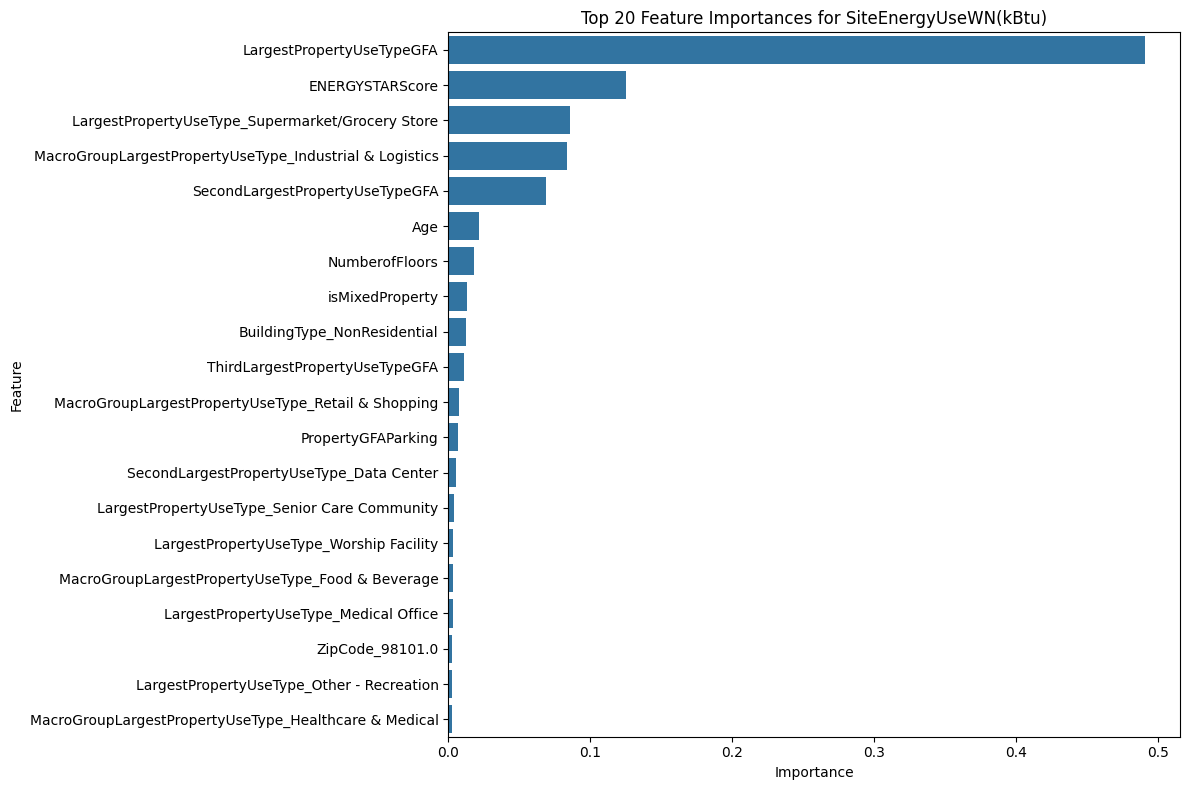

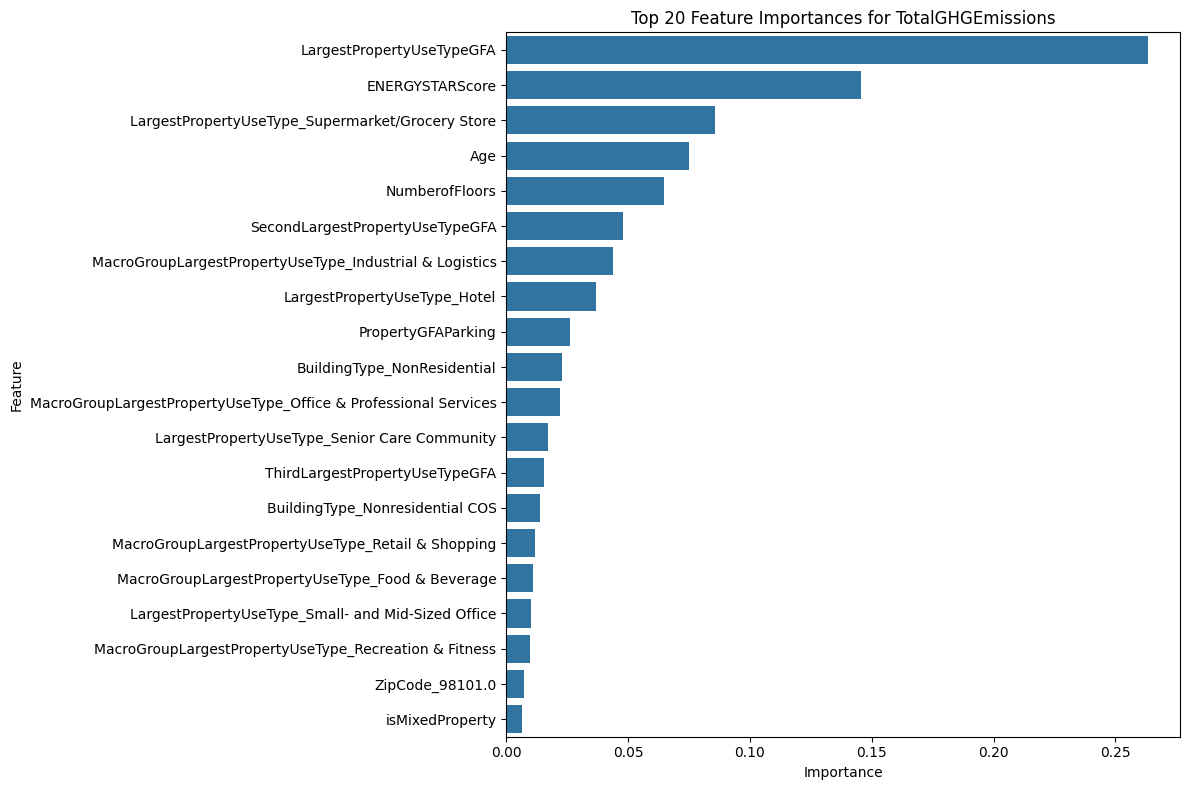


Top 20 Feature Importances for SiteEnergyUseWN(kBtu):


,Feature,Importance
2,LargestPropertyUseTypeGFA,0.490837
5,ENERGYSTARScore,0.125186
104,LargestPropertyUseType_Supermarket/Grocery Store,0.085518
185,MacroGroupLargestPropertyUseType_Industrial & ...,0.083371
3,SecondLargestPropertyUseTypeGFA,0.069146
6,Age,0.021667
0,NumberofFloors,0.018171
7,isMixedProperty,0.013522
8,BuildingType_NonResidential,0.012566
4,ThirdLargestPropertyUseTypeGFA,0.011309



Top 20 Feature Importances for TotalGHGEmissions:


,Feature,Importance
2,LargestPropertyUseTypeGFA,0.263305
5,ENERGYSTARScore,0.145458
104,LargestPropertyUseType_Supermarket/Grocery Store,0.085647
6,Age,0.074905
0,NumberofFloors,0.064581
3,SecondLargestPropertyUseTypeGFA,0.047796
185,MacroGroupLargestPropertyUseType_Industrial & ...,0.043972
65,LargestPropertyUseType_Hotel,0.037054
1,PropertyGFAParking,0.026046
8,BuildingType_NonResidential,0.023060


In [ ]:
# @title Plot Feature Importances of the Best Gradient Boosting Regressor Model

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get the best trained MultiOutputRegressor model from the RandomizedSearchCV
# This model contains the best individual GradientBoostingRegressor estimators for each target.
best_multioutput_gbr = random_search.best_estimator_

# Access the individual estimators for each target variable
gbr_energy = best_multioutput_gbr.estimators_[0] # Estimator for SiteEnergyUseWN(kBtu)
gbr_ghg = best_multioutput_gbr.estimators_[1]    # Estimator for TotalGHGEmissions

# Get feature importances for each target
feature_importances_energy = gbr_energy.feature_importances_
feature_importances_ghg = gbr_ghg.feature_importances_

# Get the feature names from the encoded DataFrame (X_encoded)
feature_names = X_encoded.columns

# Create DataFrames for better visualization and sorting
importance_df_energy = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances_energy
}).sort_values(by='Importance', ascending=False)

importance_df_ghg = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances_ghg
}).sort_values(by='Importance', ascending=False)

# Plot feature importances for SiteEnergyUseWN(kBtu)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df_energy.head(20)) # Display top 20 features
plt.title('Top 20 Feature Importances for SiteEnergyUseWN(kBtu)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Plot feature importances for TotalGHGEmissions
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df_ghg.head(20)) # Display top 20 features
plt.title('Top 20 Feature Importances for TotalGHGEmissions')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("\nTop 20 Feature Importances for SiteEnergyUseWN(kBtu):")
display(importance_df_energy.head(20))

print("\nTop 20 Feature Importances for TotalGHGEmissions:")
display(importance_df_ghg.head(20))

# Modelisation (Without ENERGYSTARScore)

The ENERGYSTARScore is the second feauture in the best models for both the target variables in the previosu modelisation. However, it should be noted that this was not filled substantially and it was filled with mean per building type for missing values; Hence, trying to perfom modelisation again by dropping this feauture.

In [ ]:
# @title Define the target variables and features (Without ENERGYSTARScore)
# Define the target variables
target_variables = ['SiteEnergyUseWN(kBtu)', 'TotalGHGEmissions']
y_no_energystar = building_consumption[target_variables]

# Define the features (all columns except the target variables and ENERGYSTARScore)
features_no_energystar = building_consumption.drop(columns=target_variables + ['ENERGYSTARScore'])
X_no_energystar = features_no_energystar

print("Features (X_no_energystar) and Target Variables (y_no_energystar) defined.")

print("\nShape of features (X_no_energystar):", X_no_energystar.shape)
print("Shape of target variables (y_no_energystar):", y_no_energystar.shape)

print("\nFirst 5 rows of target variables (y_no_energystar):")
display(y_no_energystar.head())

print("\nFirst 5 rows of features (X_no_energystar):")
display(X_no_energystar.head())

Features (X_no_energystar) and Target Variables (y_no_energystar) defined.

Shape of features (X_no_energystar): (1398, 13)
Shape of target variables (y_no_energystar): (1398, 2)

First 5 rows of target variables (y_no_energystar):


,SiteEnergyUseWN(kBtu),TotalGHGEmissions
0,7456910.0,249.98
1,8664479.0,295.86
3,6946800.5,286.43
5,12581712.0,301.81
6,6062767.5,176.14



First 5 rows of features (X_no_energystar):


,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,Age,MacroGroupLargestPropertyUseType,isMixedProperty
0,NonResidential,98101.0,12,0.0,Hotel,88434.0,None,0.0,None,0.0,98,Accommodation & Residential,0
1,NonResidential,98101.0,11,15064.0,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,29,Accommodation & Residential,1
3,NonResidential,98101.0,10,0.0,Hotel,61320.0,None,0.0,None,0.0,99,Accommodation & Residential,0
5,Nonresidential COS,98101.0,2,37198.0,Police Station,88830.0,None,0.0,None,0.0,26,Public Services & Safety,0
6,NonResidential,98101.0,11,0.0,Hotel,81352.0,None,0.0,None,0.0,99,Accommodation & Residential,0


In [ ]:
# @title Handle Categorical Features (One-Hot Encoding) (Without ENERGYSTARScore)
import pandas as pd

# Identify categorical columns in the features DataFrame (X_no_energystar)
# We can look for columns with 'category' dtype or object dtype
categorical_cols_no_energystar = X_no_energystar.select_dtypes(include=['category', 'object']).columns

print(f"Identified categorical columns (Without ENERGYSTARScore): {list(categorical_cols_no_energystar)}")

# Apply one-hot encoding
# handle_unknown='ignore' can be useful during prediction if new categories appear
X_encoded_no_energystar = pd.get_dummies(X_no_energystar, columns=categorical_cols_no_energystar, drop_first=True, dummy_na=False)

print("\nCategorical features have been one-hot encoded (Without ENERGYSTARScore).")
print("\nShape of features (X_encoded_no_energystar) after encoding:", X_encoded_no_energystar.shape)

print("\nFirst 5 rows of the encoded features (X_encoded_no_energystar):")
display(X_encoded_no_energystar.head())

Identified categorical columns (Without ENERGYSTARScore): ['BuildingType', 'ZipCode', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType', 'MacroGroupLargestPropertyUseType']

Categorical features have been one-hot encoded (Without ENERGYSTARScore).

Shape of features (X_encoded_no_energystar) after encoding: (1398, 192)

First 5 rows of the encoded features (X_encoded_no_energystar):


,NumberofFloors,PropertyGFAParking,LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,Age,isMixedProperty,BuildingType_NonResidential,BuildingType_Nonresidential COS,BuildingType_Nonresidential WA,BuildingType_SPS-District K-12,ZipCode_98006.0,ZipCode_98011.0,ZipCode_98013.0,ZipCode_98020.0,ZipCode_98033.0,ZipCode_98053.0,ZipCode_98070.0,ZipCode_98101.0,ZipCode_98102.0,ZipCode_98103.0,ZipCode_98104.0,ZipCode_98105.0,ZipCode_98106.0,ZipCode_98107.0,ZipCode_98108.0,ZipCode_98109.0,ZipCode_98111.0,ZipCode_98112.0,ZipCode_98113.0,ZipCode_98114.0,ZipCode_98115.0,ZipCode_98116.0,ZipCode_98117.0,ZipCode_98118.0,ZipCode_98119.0,ZipCode_98121.0,ZipCode_98122.0,ZipCode_98124.0,ZipCode_98125.0,ZipCode_98126.0,ZipCode_98133.0,ZipCode_98134.0,ZipCode_98136.0,ZipCode_98144.0,ZipCode_98146.0,ZipCode_98155.0,ZipCode_98165.0,ZipCode_98168.0,ZipCode_98177.0,ZipCode_98178.0,ZipCode_98195.0,ZipCode_98199.0,LargestPropertyUseType_Automobile Dealership,LargestPropertyUseType_Bank Branch,LargestPropertyUseType_College/University,LargestPropertyUseType_Courthouse,LargestPropertyUseType_Data Center,LargestPropertyUseType_Distribution Center,LargestPropertyUseType_Financial Office,LargestPropertyUseType_Fire Station,LargestPropertyUseType_Fitness Center/Health Club/Gym,LargestPropertyUseType_Food Service,LargestPropertyUseType_Hospital (General Medical & Surgical),LargestPropertyUseType_Hotel,LargestPropertyUseType_K-12 School,LargestPropertyUseType_Laboratory,LargestPropertyUseType_Library,LargestPropertyUseType_Lifestyle Center,LargestPropertyUseType_Manufacturing/Industrial Plant,LargestPropertyUseType_Medical Office,LargestPropertyUseType_Movie Theater,LargestPropertyUseType_Multifamily Housing,LargestPropertyUseType_Museum,LargestPropertyUseType_Non-Refrigerated Warehouse,LargestPropertyUseType_Office,LargestPropertyUseType_Other,LargestPropertyUseType_Other - Education,LargestPropertyUseType_Other - Entertainment/Public Assembly,LargestPropertyUseType_Other - Lodging/Residential,LargestPropertyUseType_Other - Mall,LargestPropertyUseType_Other - Public Services,LargestPropertyUseType_Other - Recreation,LargestPropertyUseType_Other - Restaurant/Bar,LargestPropertyUseType_Other - Services,LargestPropertyUseType_Other - Utility,LargestPropertyUseType_Other/Specialty Hospital,LargestPropertyUseType_Parking,LargestPropertyUseType_Performing Arts,"LargestPropertyUseType_Personal Services (Health/Beauty, Dry Cleaning, etc)",LargestPropertyUseType_Police Station,LargestPropertyUseType_Pre-school/Daycare,LargestPropertyUseType_Prison/Incarceration,LargestPropertyUseType_Refrigerated Warehouse,"LargestPropertyUseType_Repair Services (Vehicle, Shoe, Locksmith, etc)",LargestPropertyUseType_Residence Hall/Dormitory,LargestPropertyUseType_Residential Care Facility,LargestPropertyUseType_Restaurant,LargestPropertyUseType_Retail Store,LargestPropertyUseType_Self-Storage Facility,LargestPropertyUseType_Senior Care Community,LargestPropertyUseType_Social/Meeting Hall,LargestPropertyUseType_Strip Mall,LargestPropertyUseType_Supermarket/Grocery Store,LargestPropertyUseType_Urgent Care/Clinic/Other Outpatient,LargestPropertyUseType_Wholesale Club/Supercenter,LargestPropertyUseType_Worship Facility,LargestPropertyUseType_Large Office,LargestPropertyUseType_Small- and Mid-Sized Office,SecondLargestPropertyUseType_Automobile Dealership,SecondLargestPropertyUseType_Bank Branch,SecondLargestPropertyUseType_Bar/Nightclub,SecondLargestPropertyUseType_Convenience Store without Gas Station,SecondLargestPropertyUseType_Data Center,SecondLargestPropertyUseType_Distribution Center,SecondLargestPropertyUseType_Enclosed Mall,SecondLargestPropertyUseType_Financial Office,SecondLargestPropertyUseType_Fitness Center/Health Club/Gym,SecondLargestPropertyUseType_Food Sales,SecondLargestPropertyUseType_Food Service,SecondLargestPropertyUseType_Hotel,SecondLargestPropertyUseType_K-12 School,SecondLargestPropertyUseType_Laboratory,SecondLargestProperty

## CROSS VALIDATION (Without ENERGYSTARScore)

This is a reliable method as the dataset is small.

In [ ]:
# @title Train and Evaluate Regression Models using Cross-Validation (Detailed Results, Without ENERGYSTARScore)
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone # Import clone
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

import numpy as np
import pandas as pd

# Define the models (using single-output models for cross_val_score)
models_no_energystar = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Lasso Regression": Lasso(random_state=42),
    "ElasticNet Regression": ElasticNet(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Dummy Regressor (Mean)": DummyRegressor(strategy="mean"),
    "Support Vector Regressor": Pipeline([
        ('scaler', StandardScaler()),
        ('svr', SVR())
    ]),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42)
}

# Define cross-validation strategy
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Separate target variables
y_energy_no_energystar = y_no_energystar['SiteEnergyUseWN(kBtu)']
y_ghg_no_energystar = y_no_energystar['TotalGHGEmissions']

# Lists to store detailed results for each fold (train and test)
energy_fold_results_train_no_energystar = []
energy_fold_results_test_no_energystar = []
ghg_fold_results_train_no_energystar = []
ghg_fold_results_test_no_energystar = []

# Lists to store summary results
energy_summary_results_no_energystar = []
ghg_summary_results_no_energystar = []

print(f"Performing {n_splits}-fold cross-validation with detailed results (Without ENERGYSTARScore)...")

for model_name, model in models_no_energystar.items():
    print(f"\nEvaluating {model_name} (Without ENERGYSTARScore)...")

    # --- Evaluate SiteEnergyUseWN(kBtu) ---
    # Cross-validation for test scores
    rmse_scores_energy_test = -cross_val_score(
        model, X_encoded_no_energystar, y_energy_no_energystar,
        scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1
    )
    r2_scores_energy_test = cross_val_score(
        model, X_encoded_no_energystar, y_energy_no_energystar,
        scoring='r2', cv=kf, n_jobs=-1
    )
    mae_scores_energy_test = -cross_val_score(
        model, X_encoded_no_energystar, y_energy_no_energystar,
        scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1
    )

    # Cross-validation for train scores (requires iterating through folds manually)
    rmse_scores_energy_train = []
    r2_scores_energy_train = []
    mae_scores_energy_train = []

    for train_index, test_index in kf.split(X_encoded_no_energystar):
        X_train_fold, X_test_fold = X_encoded_no_energystar.iloc[train_index], X_encoded_no_energystar.iloc[test_index]
        y_train_fold, y_test_fold = y_energy_no_energystar.iloc[train_index], y_energy_no_energystar.iloc[test_index]

        # Use sklearn.base.clone to correctly clone the model, including pipelines
        model_clone = clone(model)
        model_clone.fit(X_train_fold, y_train_fold)
        y_train_pred = model_clone.predict(X_train_fold)

        rmse_scores_energy_train.append(np.sqrt(mean_squared_error(y_train_fold, y_train_pred)))
        r2_scores_energy_train.append(r2_score(y_train_fold, y_train_pred))
        mae_scores_energy_train.append(mean_absolute_error(y_train_fold, y_train_pred))

    # Store detailed energy results for each fold
    for i in range(n_splits):
        energy_fold_results_train_no_energystar.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_energy_train[i],
            'R-squared': r2_scores_energy_train[i],
            'MAE': mae_scores_energy_train[i]
        })
        energy_fold_results_test_no_energystar.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_energy_test[i],
            'R-squared': r2_scores_energy_test[i],
            'MAE': mae_scores_energy_test[i]
        })

    # Store summary energy results
    energy_summary_results_no_energystar.append({
        'Model': model_name,
        'Mean RMSE (Test)': np.mean(rmse_scores_energy_test),
        'Std Dev RMSE (Test)': np.std(rmse_scores_energy_test),
        'Mean R-squared (Test)': np.mean(r2_scores_energy_test),
        'Std Dev R-squared (Test)': np.std(r2_scores_energy_test),
        'Mean MAE (Test)': np.mean(mae_scores_energy_test),
        'Std Dev MAE (Test)': np.std(mae_scores_energy_test),
        'Mean RMSE (Train)': np.mean(rmse_scores_energy_train),
        'Std Dev RMSE (Train)': np.std(rmse_scores_energy_train),
        'Mean R-squared (Train)': np.mean(r2_scores_energy_train),
        'Std Dev R-squared (Train)': np.std(r2_scores_energy_train),
        'Mean MAE (Train)': np.mean(mae_scores_energy_train),
        'Std Dev MAE (Train)': np.std(mae_scores_energy_train),
    })

    # --- Evaluate TotalGHGEmissions ---
    # Cross-validation for test scores
    rmse_scores_ghg_test = -cross_val_score(
        model, X_encoded_no_energystar, y_ghg_no_energystar,
        scoring='neg_root_mean_squared_error', cv=kf, n_jobs=-1
    )
    r2_scores_ghg_test = cross_val_score(
        model, X_encoded_no_energystar, y_ghg_no_energystar,
        scoring='r2', cv=kf, n_jobs=-1
    )
    mae_scores_ghg_test = -cross_val_score(
        model, X_encoded_no_energystar, y_ghg_no_energystar,
        scoring='neg_mean_absolute_error', cv=kf, n_jobs=-1
    )

    # Cross-validation for train scores (requires iterating through folds manually)
    rmse_scores_ghg_train = []
    r2_scores_ghg_train = []
    mae_scores_ghg_train = []

    for train_index, test_index in kf.split(X_encoded_no_energystar):
        X_train_fold, X_test_fold = X_encoded_no_energystar.iloc[train_index], X_encoded_no_energystar.iloc[test_index]
        y_train_fold, y_test_fold = y_ghg_no_energystar.iloc[train_index], y_ghg_no_energystar.iloc[test_index]

        # Use sklearn.base.clone to correctly clone the model, including pipelines
        model_clone = clone(model)
        model_clone.fit(X_train_fold, y_train_fold)
        y_train_pred = model_clone.predict(X_train_fold)

        rmse_scores_ghg_train.append(np.sqrt(mean_squared_error(y_train_fold, y_train_pred)))
        r2_scores_ghg_train.append(r2_score(y_train_fold, y_train_pred))
        mae_scores_ghg_train.append(mean_absolute_error(y_train_fold, y_train_pred))

    # Store detailed GHG results for each fold
    for i in range(n_splits):
        ghg_fold_results_train_no_energystar.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_ghg_train[i],
            'R-squared': r2_scores_ghg_train[i],
            'MAE': mae_scores_ghg_train[i]
        })
        ghg_fold_results_test_no_energystar.append({
            'Model': model_name,
            'Fold': i + 1,
            'RMSE': rmse_scores_ghg_test[i],
            'R-squared': r2_scores_ghg_test[i],
            'MAE': mae_scores_ghg_test[i]
        })

    # Store summary GHG results
    ghg_summary_results_no_energystar.append({
        'Model': model_name,
        'Mean RMSE (Test)': np.mean(rmse_scores_ghg_test),
        'Std Dev RMSE (Test)': np.std(rmse_scores_ghg_test),
        'Mean R-squared (Test)': np.mean(r2_scores_ghg_test),
        'Std Dev R-squared (Test)': np.std(rmse_scores_ghg_test),
        'Mean MAE (Test)': np.mean(mae_scores_ghg_test),
        'Std Dev MAE (Test)': np.std(mae_scores_ghg_test),
        'Mean RMSE (Train)': np.mean(rmse_scores_ghg_train),
        'Std Dev RMSE (Train)': np.std(rmse_scores_ghg_train),
        'Mean R-squared (Train)': np.mean(r2_scores_ghg_train),
        'Std Dev R-squared (Train)': np.std(rmse_scores_ghg_train),
        'Mean MAE (Train)': np.mean(mae_scores_ghg_train),
        'Std Dev MAE (Train)': np.std(mae_scores_ghg_train),
    })

# Create DataFrames from the results
energy_summary_df_no_energystar = pd.DataFrame(energy_summary_results_no_energystar)
ghg_summary_df_no_energystar = pd.DataFrame(ghg_summary_results_no_energystar)

energy_fold_df_train_no_energystar = pd.DataFrame(energy_fold_results_train_no_energystar)
energy_fold_df_test_no_energystar = pd.DataFrame(energy_fold_results_test_no_energystar)
ghg_fold_df_train_no_energystar = pd.DataFrame(ghg_fold_results_train_no_energystar)
ghg_fold_df_test_no_energystar = pd.DataFrame(ghg_fold_results_test_no_energystar)

# Export results to an Excel file with four sheets
excel_filename_no_energystar = 'cross_validation_results_no_energystar.xlsx'
with pd.ExcelWriter(excel_filename_no_energystar) as writer:
    energy_summary_df_no_energystar.to_excel(writer, sheet_name='Energy_Summary_No_ES', index=False)
    ghg_summary_df_no_energystar.to_excel(writer, sheet_name='GHG_Summary_No_ES', index=False)
    energy_fold_df_train_no_energystar.to_excel(writer, sheet_name='Energy_Detailed_Train_No_ES', index=False)
    energy_fold_df_test_no_energystar.to_excel(writer, sheet_name='Energy_Detailed_Test_No_ES', index=False)
    ghg_fold_df_train_no_energystar.to_excel(writer, sheet_name='GHG_Detailed_Train_No_ES', index=False)
    ghg_fold_df_test_no_energystar.to_excel(writer, sheet_name='GHG_Detailed_Test_No_ES', index=False)

print(f"\nCross-validation results exported to '{excel_filename_no_energystar}' in your active directory with the following sheets:")
print("- Energy_Summary_No_ES")
print("- GHG_Summary_No_ES")
print("- Energy_Detailed_Train_No_ES")
print("- Energy_Detailed_Test_No_ES")
print("- GHG_Detailed_Train_No_ES")
print("- GHG_Detailed_Test_No_ES")

# Display basic summary for both variables
print("\n--- Summary of Cross-Validation Results (Without ENERGYSTARScore) ---")

print("\nSiteEnergyUseWN(kBtu) - Test Set Averages (Without ENERGYSTARScore):")
display(energy_summary_df_no_energystar[['Model', 'Mean RMSE (Test)', 'Mean R-squared (Test)', 'Mean MAE (Test)']].sort_values(by='Mean R-squared (Test)', ascending=False))

print("\nTotalGHGEmissions - Test Set Averages (Without ENERGYSTARScore):")
display(ghg_summary_df_no_energystar[['Model', 'Mean RMSE (Test)', 'Mean R-squared (Test)', 'Mean MAE (Test)']].sort_values(by='Mean R-squared (Test)', ascending=False))

Performing 5-fold cross-validation with detailed results (Without ENERGYSTARScore)...

Evaluating Linear Regression (Without ENERGYSTARScore)...

Evaluating Ridge Regression (Without ENERGYSTARScore)...

Evaluating Lasso Regression (Without ENERGYSTARScore)...

Evaluating ElasticNet Regression (Without ENERGYSTARScore)...

Evaluating Random Forest Regressor (Without ENERGYSTARScore)...

Evaluating Gradient Boosting Regressor (Without ENERGYSTARScore)...

Evaluating Dummy Regressor (Mean) (Without ENERGYSTARScore)...

Evaluating Support Vector Regressor (Without ENERGYSTARScore)...

Evaluating Decision Tree Regressor (Without ENERGYSTARScore)...

Cross-validation results exported to 'cross_validation_results_no_energystar.xlsx' in your active directory with the following sheets:
- Energy_Summary_No_ES
- GHG_Summary_No_ES
- Energy_Detailed_Train_No_ES
- Energy_Detailed_Test_No_ES
- GHG_Detailed_Train_No_ES
- GHG_Detailed_Test_No_ES

--- Summary of Cross-Validation Results (Without ENERGY

,Model,Mean RMSE (Test),Mean R-squared (Test),Mean MAE (Test)
5,Gradient Boosting Regressor,1.920429e+06,0.631812,1.307987e+06
4,Random Forest Regressor,1.932952e+06,0.623951,1.291236e+06
1,Ridge Regression,1.999241e+06,0.601924,1.387377e+06
0,Linear Regression,2.102352e+06,0.558094,1.437717e+06
2,Lasso Regression,2.107629e+06,0.556206,1.434627e+06
3,ElasticNet Regression,2.238318e+06,0.503075,1.559862e+06
8,Decision Tree Regressor,2.564237e+06,0.340571,1.723512e+06
6,Dummy Regressor (Mean),3.188744e+06,-0.006449,2.439285e+06
7,Support Vector Regressor,3.401066e+06,-0.144472,2.228190e+06



TotalGHGEmissions - Test Set Averages (Without ENERGYSTARScore):


,Model,Mean RMSE (Test),Mean R-squared (Test),Mean MAE (Test)
4,Random Forest Regressor,56.057479,0.370679,38.064540
5,Gradient Boosting Regressor,56.065251,0.370199,39.166833
1,Ridge Regression,58.226404,0.320378,41.365609
2,Lasso Regression,58.551947,0.313894,42.050734
0,Linear Regression,60.698259,0.261227,42.745333
3,ElasticNet Regression,63.709714,0.186924,46.094332
6,Dummy Regressor (Mean),70.942106,-0.007818,52.968680
7,Support Vector Regressor,72.908719,-0.063091,45.901406
8,Decision Tree Regressor,73.710847,-0.096118,48.975784


### CHOICE OF MODELS (Without ENERGYSTARScore)

Based on the cross-validation results excluding the ENERGYSTARScore, let's analyze the best model for both target variables.

In [ ]:
# @title Perform Randomized Grid Search for Gradient Boosting Regressor (Without ENERGYSTARScore)
from sklearn.model_selection import RandomizedSearchCV, train_test_split # Import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
import numpy as np

# Define the parameter grid for RandomizedSearchCV
# These are example parameters, you might want to adjust them based on your understanding of the model and data
param_grid_no_energystar = {
    'estimator__n_estimators': [100, 200, 300, 400, 500], # Number of boosting stages
    'estimator__learning_rate': [0.01, 0.05, 0.1, 0.2], # Learning rate shrinks the contribution of each tree
    'estimator__max_depth': [3, 4, 5, 6, 7], # Maximum depth of the individual regression estimators
    'estimator__min_samples_split': [2, 5, 10, 15], # Minimum number of samples required to split an internal node
    'estimator__min_samples_leaf': [1, 2, 4, 6], # Minimum number of samples required to be at a leaf node
    'estimator__subsample': [0.8, 0.9, 1.0], # Fraction of samples to be used for fitting the individual base learners
    'estimator__max_features': ['sqrt', 'log2', None], # Number of features to consider when looking for the best split
}

# Initialize the base Gradient Boosting Regressor model
gbr_no_energystar = GradientBoostingRegressor(random_state=42)

# Initialize the MultiOutputRegressor with the base model
multi_output_gbr_no_energystar = MultiOutputRegressor(gbr_no_energystar)

# Initialize RandomizedSearchCV
# n_iter: Number of parameter settings that are sampled. 10 as requested by the user.
# cv: Number of folds for cross-validation
# scoring: Metric to evaluate the models (e.g., 'neg_root_mean_squared_error' or 'r2')
# n_jobs: Number of jobs to run in parallel (-1 means using all available processors)
# random_state: Seed for reproducibility
random_search_no_energystar = RandomizedSearchCV(
    multi_output_gbr_no_energystar,
    param_distributions=param_grid_no_energystar,
    n_iter=10, # Number of combinations to try
    cv=5,       # 5-fold cross-validation
    scoring='neg_root_mean_squared_error', # Using negative RMSE as the scoring metric (higher is better)
    n_jobs=-1,  # Use all available cores
    random_state=42,
    verbose=2 # Display progress
)

print("Performing Randomized Search on Gradient Boosting Regressor hyperparameters (Without ENERGYSTARScore)...")

# --- Add the train-test split here ---
# Assuming X_encoded_no_energystar and y_no_energystar are defined in preceding cells
X_train_no_energystar, X_test_no_energystar, y_train_no_energystar, y_test_no_energystar = train_test_split(
    X_encoded_no_energystar, y_no_energystar, test_size=0.2, random_state=42
)
print("\nData split into training and testing sets (Without ENERGYSTARScore) within the tuning cell.")
# --- End of added train-test split ---


# Perform the randomized search on the training data
random_search_no_energystar.fit(X_train_no_energystar, y_train_no_energystar)

print("\nRandomized Search complete (Without ENERGYSTARScore).")

# Get the best parameters and best score
best_params_no_energystar = random_search_no_energystar.best_params_
best_score_no_energystar = -random_search_no_energystar.best_score_ # Convert back from negative RMSE

print("\nBest parameters found (Without ENERGYSTARScore):")
print(best_params_no_energystar)
print(f"\nBest cross-validation RMSE (from randomized search, Without ENERGYSTARScore): {best_score_no_energystar}")

# You can now use random_search_no_energystar.best_estimator_ to get the best model
best_gbr_model_no_energystar = random_search_no_energystar.best_estimator_

# Evaluate the best model on the test set (optional, but recommended)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

y_pred_best_no_energystar = best_gbr_model_no_energystar.predict(X_test_no_energystar)

# Evaluate for SiteEnergyUseWN(kBtu)
rmse_energy_test_no_energystar = np.sqrt(mean_squared_error(y_test_no_energystar['SiteEnergyUseWN(kBtu)'], y_pred_best_no_energystar[:, 0]))
r2_energy_test_no_energystar = r2_score(y_test_no_energystar['SiteEnergyUseWN(kBtu)'], y_pred_best_no_energystar[:, 0])
mae_energy_test_no_energystar = mean_absolute_error(y_test_no_energystar['SiteEnergyUseWN(kBtu)'], y_pred_best_no_energystar[:, 0])

# Evaluate for TotalGHGEmissions
rmse_ghg_test_no_energystar = np.sqrt(mean_squared_error(y_test_no_energystar['TotalGHGEmissions'], y_pred_best_no_energystar[:, 1]))
r2_ghg_test_no_energystar = r2_score(y_test_no_energystar['TotalGHGEmissions'], y_pred_best_no_energystar[:, 1])
mae_ghg_test_no_energystar = mean_absolute_error(y_test_no_energystar['TotalGHGEmissions'], y_pred_best_no_energystar[:, 1])

print("\nEvaluation of the best model on the test set (Without ENERGYSTARScore):")
print(f"SiteEnergyUseWN(kBtu):")
print(f"  RMSE: {rmse_energy_test_no_energystar}")
print(f"  R-squared: {r2_energy_test_no_energystar}")
print(f"  MAE: {mae_energy_test_no_energystar}")

print(f"\nTotalGHGEmissions:")
print(f"  RMSE: {rmse_ghg_test_no_energystar}")
print(f"  R-squared: {r2_ghg_test_no_energystar}")
print(f"  MAE: {mae_ghg_test_no_energystar}")

Performing Randomized Search on Gradient Boosting Regressor hyperparameters (Without ENERGYSTARScore)...

Data split into training and testing sets (Without ENERGYSTARScore) within the tuning cell.
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Randomized Search complete (Without ENERGYSTARScore).

Best parameters found (Without ENERGYSTARScore):
{'estimator__subsample': 0.9, 'estimator__n_estimators': 200, 'estimator__min_samples_split': 10, 'estimator__min_samples_leaf': 6, 'estimator__max_features': None, 'estimator__max_depth': 5, 'estimator__learning_rate': 0.05}

Best cross-validation RMSE (from randomized search, Without ENERGYSTARScore): 944052.5288343241

Evaluation of the best model on the test set (Without ENERGYSTARScore):
SiteEnergyUseWN(kBtu):
  RMSE: 1980205.390710649
  R-squared: 0.5863937226030167
  MAE: 1391802.3795002892

TotalGHGEmissions:
  RMSE: 59.49295396838277
  R-squared: 0.3518846727721465
  MAE: 41.56696479219529


In [ ]:
# @title Split the data into training and testing sets (Without ENERGYSTARScore)
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# Using X_encoded_no_energystar and y_no_energystar
X_train_no_energystar, X_test_no_energystar, y_train_no_energystar, y_test_no_energystar = train_test_split(
    X_encoded_no_energystar, y_no_energystar, test_size=0.2, random_state=42
)

print("Data split into training and testing sets (Without ENERGYSTARScore).")
print(f"Shape of X_train_no_energystar: {X_train_no_energystar.shape}")
print(f"Shape of X_test_no_energystar: {X_test_no_energystar.shape}")
print(f"Shape of y_train_no_energystar: {y_train_no_energystar.shape}")
print(f"Shape of y_test_no_energystar: {y_test_no_energystar.shape}")

Data split into training and testing sets (Without ENERGYSTARScore).
Shape of X_train_no_energystar: (1118, 192)
Shape of X_test_no_energystar: (280, 192)
Shape of y_train_no_energystar: (1118, 2)
Shape of y_test_no_energystar: (280, 2)


In [ ]:
# @title Evaluate the best model on the test set for both target variables (Without ENERGYSTARScore)

# Get the best model from the RandomizedSearchCV
best_gbr_model_no_energystar = random_search_no_energystar.best_estimator_

# Make predictions on the test set
y_pred_best_no_energystar = best_gbr_model_no_energystar.predict(X_test_no_energystar)

# Evaluate for SiteEnergyUseWN(kBtu)
rmse_energy_test_no_energystar = np.sqrt(mean_squared_error(y_test_no_energystar['SiteEnergyUseWN(kBtu)'], y_pred_best_no_energystar[:, 0]))
r2_energy_test_no_energystar = r2_score(y_test_no_energystar['SiteEnergyUseWN(kBtu)'], y_pred_best_no_energystar[:, 0])
mae_energy_test_no_energystar = mean_absolute_error(y_test_no_energystar['SiteEnergyUseWN(kBtu)'], y_pred_best_no_energystar[:, 0])

# Evaluate for TotalGHGEmissions
rmse_ghg_test_no_energystar = np.sqrt(mean_squared_error(y_test_no_energystar['TotalGHGEmissions'], y_pred_best_no_energystar[:, 1]))
r2_ghg_test_no_energystar = r2_score(y_test_no_energystar['TotalGHGEmissions'], y_pred_best_no_energystar[:, 1])
mae_ghg_test_no_energystar = mean_absolute_error(y_test_no_energystar['TotalGHGEmissions'], y_pred_best_no_energystar[:, 1])


print("Evaluation of the best model on the test set (Without ENERGYSTARScore):")
print(f"SiteEnergyUseWN(kBtu):")
print(f"  RMSE: {rmse_energy_test_no_energystar}")
print(f"  R-squared: {r2_energy_test_no_energystar}")
print(f"  MAE: {mae_energy_test_no_energystar}")

print(f"\nTotalGHGEmissions:")
print(f"  RMSE: {rmse_ghg_test_no_energystar}")
print(f"  R-squared: {r2_ghg_test_no_energystar}")
print(f"  MAE: {mae_ghg_test_no_energystar}")

Evaluation of the best model on the test set (Without ENERGYSTARScore):
SiteEnergyUseWN(kBtu):
  RMSE: 1980205.390710649
  R-squared: 0.5863937226030167
  MAE: 1391802.3795002892

TotalGHGEmissions:
  RMSE: 59.49295396838277
  R-squared: 0.3518846727721465
  MAE: 41.56696479219529


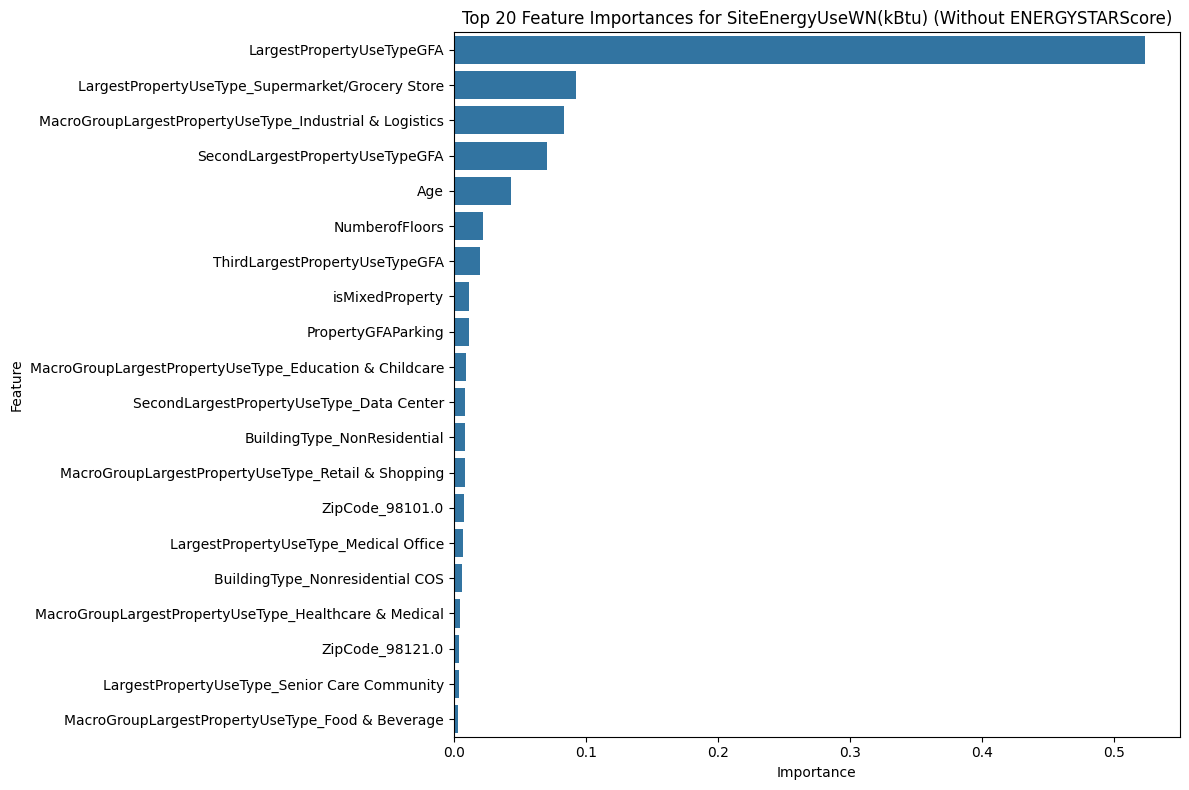

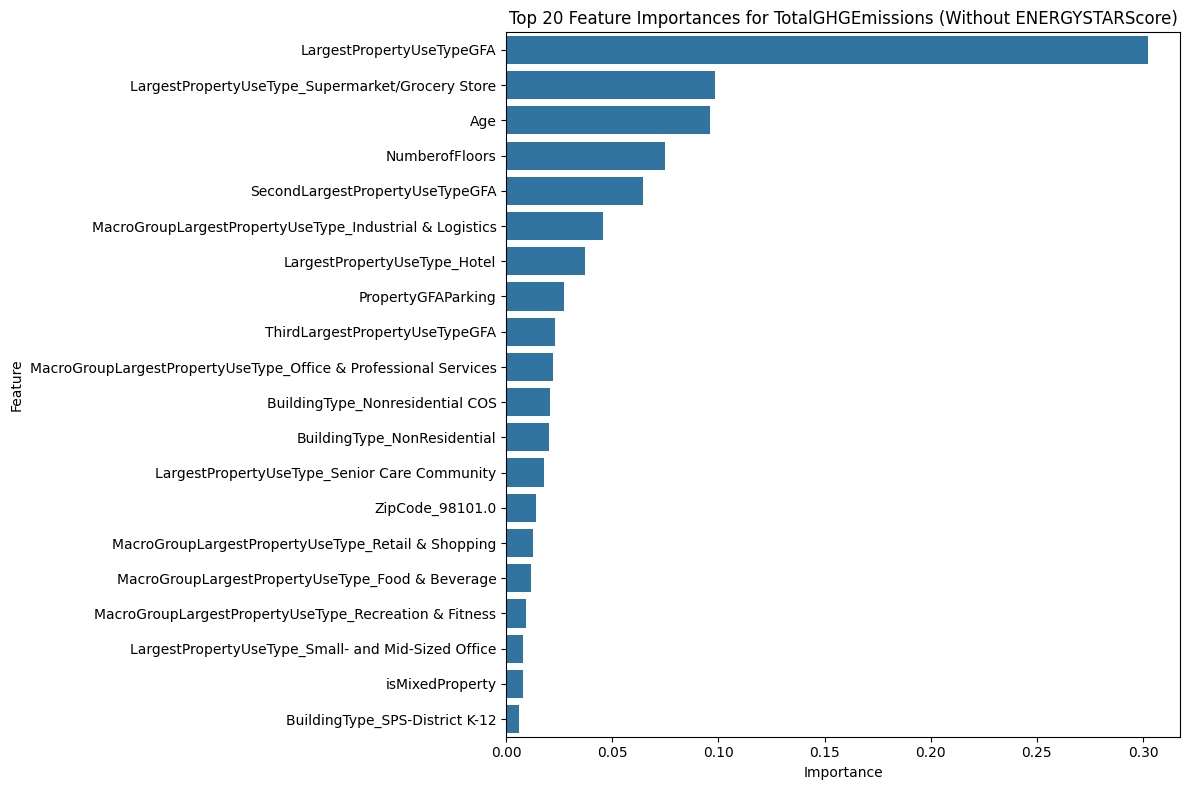


Top 20 Feature Importances for SiteEnergyUseWN(kBtu) (Without ENERGYSTARScore):


,Feature,Importance
2,LargestPropertyUseTypeGFA,0.523739
103,LargestPropertyUseType_Supermarket/Grocery Store,0.092449
184,MacroGroupLargestPropertyUseType_Industrial & ...,0.083811
3,SecondLargestPropertyUseTypeGFA,0.070972
5,Age,0.043782
0,NumberofFloors,0.022469
4,ThirdLargestPropertyUseTypeGFA,0.019913
6,isMixedProperty,0.011601
1,PropertyGFAParking,0.011418
180,MacroGroupLargestPropertyUseType_Education & C...,0.009475



Top 20 Feature Importances for TotalGHGEmissions (Without ENERGYSTARScore):


,Feature,Importance
2,LargestPropertyUseTypeGFA,0.302319
103,LargestPropertyUseType_Supermarket/Grocery Store,0.098584
5,Age,0.096203
0,NumberofFloors,0.074721
3,SecondLargestPropertyUseTypeGFA,0.064360
184,MacroGroupLargestPropertyUseType_Industrial & ...,0.045759
64,LargestPropertyUseType_Hotel,0.037306
1,PropertyGFAParking,0.027232
4,ThirdLargestPropertyUseTypeGFA,0.022802
185,MacroGroupLargestPropertyUseType_Office & Prof...,0.021853


In [ ]:
# @title Plot Feature Importances of the Best Gradient Boosting Regressor Model (Without ENERGYSTARScore)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get the best trained MultiOutputRegressor model from the RandomizedSearchCV
# This model contains the best individual GradientBoostingRegressor estimators for each target.
best_multioutput_gbr_no_energystar = random_search_no_energystar.best_estimator_

# Access the individual estimators for each target variable
gbr_energy_no_energystar = best_multioutput_gbr_no_energystar.estimators_[0] # Estimator for SiteEnergyUseWN(kBtu)
gbr_ghg_no_energystar = best_multioutput_gbr_no_energystar.estimators_[1]    # Estimator for TotalGHGEmissions

# Get feature importances for each target
feature_importances_energy_no_energystar = gbr_energy_no_energystar.feature_importances_
feature_importances_ghg_no_energystar = gbr_ghg_no_energystar.feature_importances_

# Get the feature names from the encoded DataFrame (X_encoded_no_energystar)
feature_names_no_energystar = X_encoded_no_energystar.columns

# Create DataFrames for better visualization and sorting
importance_df_energy_no_energystar = pd.DataFrame({
    'Feature': feature_names_no_energystar,
    'Importance': feature_importances_energy_no_energystar
}).sort_values(by='Importance', ascending=False)

importance_df_ghg_no_energystar = pd.DataFrame({
    'Feature': feature_names_no_energystar,
    'Importance': feature_importances_ghg_no_energystar
}).sort_values(by='Importance', ascending=False)

# Plot feature importances for SiteEnergyUseWN(kBtu)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df_energy_no_energystar.head(20)) # Display top 20 features
plt.title('Top 20 Feature Importances for SiteEnergyUseWN(kBtu) (Without ENERGYSTARScore)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Plot feature importances for TotalGHGEmissions
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df_ghg_no_energystar.head(20)) # Display top 20 features
plt.title('Top 20 Feature Importances for TotalGHGEmissions (Without ENERGYSTARScore)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("\nTop 20 Feature Importances for SiteEnergyUseWN(kBtu) (Without ENERGYSTARScore):")
display(importance_df_energy_no_energystar.head(20))

print("\nTop 20 Feature Importances for TotalGHGEmissions (Without ENERGYSTARScore):")
display(importance_df_ghg_no_energystar.head(20))

## Plan: Modelization without `SiteEnergyUseWN(kBtu)` as a target and with log-transform of `TotalGHGEmissions`

Here is a plan to perform the modelization without SiteEnergyUseWN(kBtu) as a target variable and with a logarithmic transformation of TotalGHGEmissions.

1. **Define target and features:** Create new dataframes for features (excluding `SiteEnergyUseWN(kBtu)` and `ENERGYSTARScore`) and the transformed target variable (`TotalGHGEmissions` with log).
2. **Handle categorical features:** Apply one-hot encoding to the categorical features in the new feature dataframe.
3. **Split data:** Split the encoded features and transformed target data into training and testing sets.
4. **Train and evaluate models:** Train a selection of regression models (including `GradientBoostingRegressor`) using cross-validation on the new data split and evaluate their performance.
5. **Hyperparameter tuning:** Perform Randomized Grid Search for the best-performing model (likely `GradientBoostingRegressor`) on the new data.
6. **Evaluate best model:** Evaluate the best model with optimized hyperparameters on the test set.
7. **Feature importance analysis:** Plot and analyze the feature importances for the best model trained on the new data.
8. **Finish task:** Summarize the findings and compare the results of this modelization approach to the previous one.


In [ ]:
# === Run this after `building_consumption` exists ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

df = building_consumption.copy()
target = 'TotalGHGEmissions'
if target not in df.columns:
    raise ValueError(f"'{target}' is missing in the dataframe.")

exclude = set([target, 'SiteEnergyUseWN(kBtu)', 'ENERGYSTARScore'])
X = df.drop(columns=[c for c in exclude if c in df.columns], errors='ignore')
y = np.log1p(pd.to_numeric(df[target], errors='coerce'))

mask = ~np.isnan(y)
X, y = X.loc[mask], y.loc[mask]

cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

pre = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ],
    remainder='drop'
)

def cv(model, X, y):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    s = cross_val_score(model, X, y, scoring='r2', cv=kf)
    return s.mean(), s.std(), s

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cands = {
    'Ridge': Pipeline([('pre', pre), ('model', Ridge(alpha=1.0, random_state=42))]),
    'Lasso': Pipeline([('pre', pre), ('model', Lasso(alpha=0.001, max_iter=10000, random_state=42))]),
    'GBR':   Pipeline([('pre', pre), ('model', GradientBoostingRegressor(random_state=42))]),
    'RF':    Pipeline([('pre', pre), ('model', RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))]),
}

print("Cross-validated R^2 on log(target):")
cv_scores = {}
for name, pipe in cands.items():
    m, s, arr = cv(pipe, X_train, y_train)
    cv_scores[name] = m
    print(f"{name:>6}: mean={m:.3f} ± {s:.3f}  -> {np.round(arr, 3)}")

best = max(cv_scores, key=cv_scores.get)
print("\\nBest by CV:", best)

# Randomized search on GBR per plan
gbr = Pipeline([('pre', pre), ('model', GradientBoostingRegressor(random_state=42))])
param_dist = {
    'model__n_estimators': [100, 200, 300, 400, 500],
    'model__learning_rate': np.logspace(-2, -0.2, 10),
    'model__max_depth': [2,3,4,5],
    'model__subsample': [0.6, 0.75, 0.9, 1.0],
    'model__min_samples_split': [2,5,10,20],
    'model__min_samples_leaf': [1,2,4,6],
}

search = RandomizedSearchCV(
    gbr,
    param_distributions=param_dist,
    n_iter=40,
    scoring='r2',
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)
search.fit(X_train, y_train)
print("\\nBest params:", search.best_params_)
print("Best CV R^2:", round(search.best_score_, 3))

best_pipe = search.best_estimator_
y_pred_log = best_pipe.predict(X_test)

print("\\nTest metrics:")
print("R^2 (log):", round(r2_score(y_test, y_pred_log), 3))
print("RMSE_log:", round(mean_squared_error(y_test, y_pred_log, squared=False), 3))

y_test_raw = np.expm1(y_test)
y_pred_raw = np.expm1(y_pred_log)
print("R^2 (raw):", round(r2_score(y_test_raw, y_pred_raw), 3))
print("RMSE_raw:", round(mean_squared_error(y_test_raw, y_pred_raw, squared=False), 3))

# Feature importances
fitted_pre = best_pipe.named_steps['pre']
fitted_model = best_pipe.named_steps['model']

num_features = num_cols
cat_features = []
if cat_cols:
    ohe = fitted_pre.named_transformers_['cat']
    try:
        cat_features = ohe.get_feature_names_out(cat_cols).tolist()
    except Exception:
        cat_features = [f"{c}__{i}" for c in cat_cols for i in range(len(ohe.categories_[cat_cols.index(c)]))]

feat_names = num_features + cat_features

if hasattr(fitted_model, "feature_importances_"):
    imps = fitted_model.feature_importances_
    n = min(len(imps), len(feat_names))
    pairs = sorted(zip(feat_names[:n], imps[:n]), key=lambda x: x[1], reverse=True)[:20]
    plt.figure(figsize=(8, max(4, len(pairs)*0.3)))
    plt.barh([p[0] for p in pairs][::-1], [p[1] for p in pairs][::-1])
    plt.title("Top Feature Importances (GBR)")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("[Note] No native feature_importances_. Consider permutation importance.")